In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import glob
import os
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

## GOES along trajectories

In [2]:
with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_with_goes.nc') as ds:
    bt_with_goes = ds.load()

In [3]:
bt_with_goes['goes_cat_at_ec_overpass'] = (bt_with_goes.sel(timestep=0).goes_cats)

In [4]:
bt_with_goes

<xarray.Dataset> Size: 63MB
Dimensions:                  (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 103kB 2024-08-0...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 310kB '01009E' ... '08369E'
Data variables: (12/15)
    lat_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 4MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 4MB N...
    goes_cats                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 4MB nan ... nan
    ...                       ...
    goes_ot_gt_5             (time_startpoint, timestep) float64 4MB nan ... nan
    goes_y_idx               (time_startpoint, timestep) float64 4MB nan ... nan
    goes_x_idx               (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lon_mid             (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lat_mid             (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cat_at_ec_overpass  (time_startpoint) float64 103kB 1.0 1.0 ... 3.0 3.0

In [5]:
# clean up the bt_with_goes dataset: convert a goes_cats value that is surrounded by goes_cats values of all the same category to that category, even if the middle value is different 
# 1, 1, 1      1, 1, 1
# 1, 3, 1  --> 1, 1, 1
# 1, 1, 1      1, 1, 1

bt_with_goes_cleaned = None
orbits = np.unique(bt_with_goes['orbit'])
for orbit in orbits:
    bt_orbit = bt_with_goes.where(bt_with_goes['orbit'] == orbit, drop=True)
    da = bt_orbit['goes_cats']

    neighbors = [
        da.shift(time_startpoint=-1, timestep=-1), da.shift(time_startpoint=-1, timestep=0), da.shift(time_startpoint=-1, timestep=1),
        da.shift(time_startpoint=0,  timestep=-1),                                           da.shift(time_startpoint=0,  timestep=1),
        da.shift(time_startpoint=1,  timestep=-1), da.shift(time_startpoint=1,  timestep=0), da.shift(time_startpoint=1,  timestep=1),
    ]

    stacked = xr.concat(neighbors, dim="neighbor")

    all_equal = (stacked == stacked.isel(neighbor=0)).all("neighbor")
    no_nan_neighbors = ~stacked.isnull().any("neighbor")
    center_diff = da != stacked.isel(neighbor=0)

    isolated_mask = all_equal & no_nan_neighbors & center_diff
    N_isolated = isolated_mask.sum().values

    surround_val = stacked.isel(neighbor=3)
    corrected = da.where(~isolated_mask, surround_val)
    bt_orbit['goes_cats_original'] = da
    bt_orbit['goes_cats'] = corrected

    if bt_with_goes_cleaned is None:
        bt_with_goes_cleaned = bt_orbit.copy()
    else:
        bt_with_goes_cleaned = xr.concat([bt_with_goes_cleaned, bt_orbit], dim='time_startpoint')
    print(f'Orbit {orbit}: {N_isolated} isolated points corrected')

    #fig, (ax0,ax1) = plt.subplots(1,2, figsize=(10,4))
    #da.T.plot(ax=ax0)
    #corrected.T.plot(ax=ax1)
    #fig.tight_layout()
    #plt.show()


Orbit 01009E: 1 isolated points corrected
Orbit 01024E: 1 isolated points corrected
Orbit 01040E: 0 isolated points corrected
Orbit 01056E: 0 isolated points corrected
Orbit 01071E: 1 isolated points corrected
Orbit 01087E: 0 isolated points corrected
Orbit 01102E: 0 isolated points corrected
Orbit 01133E: 0 isolated points corrected
Orbit 01164E: 1 isolated points corrected
Orbit 01180E: 0 isolated points corrected
Orbit 01195E: 0 isolated points corrected
Orbit 01211E: 0 isolated points corrected
Orbit 01227E: 0 isolated points corrected
Orbit 01242E: 0 isolated points corrected
Orbit 01258E: 0 isolated points corrected
Orbit 01273E: 1 isolated points corrected
Orbit 01289E: 1 isolated points corrected
Orbit 01304E: 0 isolated points corrected
Orbit 01320E: 0 isolated points corrected
Orbit 01335E: 0 isolated points corrected
Orbit 01351E: 1 isolated points corrected
Orbit 01367E: 0 isolated points corrected
Orbit 01382E: 1 isolated points corrected
Orbit 01398E: 0 isolated points co

In [6]:
bt_with_goes_cleaned

<xarray.Dataset> Size: 67MB
Dimensions:                  (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 103kB 2024-08-0...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 310kB '01009E' ... '08369E'
Data variables: (12/16)
    lat_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 4MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 4MB N...
    goes_cats                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 4MB nan ... nan
    ...                       ...
    goes_y_idx               (time_startpoint, timestep) float64 4MB nan ... nan
    goes_x_idx               (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lon_mid             (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lat_mid             (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cat_at_ec_overpass  (time_startpoint) float64 103kB 1.0 1.0 ... 3.0 3.0
    goes_cats_original       (time_startpoint, timestep) float64 4MB nan ... nan

## retrieve time to/from transitions

In [7]:
def get_transition_properties(bt_dataset, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True):
    """
    Find where trajectories transition from cat0 to cat1 (e.g. open to closed cells)
    going backwards or forwards in time from timestep=0.
    
    Parameters:
    -----------
    bt_dataset : xarray.Dataset
        Dataset with goes_cats, datetime_traj variables
    transition_from_goes_cats : list
        List of MSI categories to transition from (default: [2])
    transition_to_goes_cats : list
        List of GOES categories to transition to (default: [0, 1])
    backward : bool
        Whether to search backwards in time (default: True)

    Returns:
    --------
    xarray.Dataset
        Dataset with added variables:
        - transition_flag: boolean flag indicating if transition occurred
        - transition_timestep: timestep where transition occurs (first stratiform point)
        - transition_datetime: datetime at transition (mean between last non-stratiform and first stratiform)
        - transition_time_diff: time difference from timestep=0 to transition
        - transition_uncertainty: time uncertainty of transition (half the time difference between last non-stratiform and first stratiform)
    """
    
    # Get dimensions
    n_startpoints = len(bt_dataset.time_startpoint)
    
    # Initialize arrays for results
    transition_flag = np.full(n_startpoints, False)
    transition_timestep = np.full(n_startpoints, np.nan)
    transition_datetime = np.full(n_startpoints, np.datetime64('NaT'), dtype='datetime64[ns]')
    transition_time_diff = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    transition_uncertainty = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    
    # Get timesteps sorted from 0 to negative values
    timesteps = bt_dataset.timestep.values
    if backward:
        timesteps_sorted = np.sort(timesteps)[::-1]  # Descending order: 0, -1, -2, ...
    else:
        timesteps_sorted = np.sort(timesteps)  # Ascending order: 0, 1, 2, ...
    
    for i in range(n_startpoints):
        traj = bt_dataset.isel(time_startpoint=i)
        
        # Check if timestep=0 has the correct goes category to start from
        goes_cat_at_zero = float(traj.sel(timestep=0).goes_cats.values)
        if goes_cat_at_zero not in transition_from_goes_cats:
            continue  # Skip if not starting from desired GOES category
        
        # Get the datetime at timestep=0 for reference
        reference_datetime = traj.sel(timestep=0).datetime_traj.values
            
        # Look through timesteps from 0 backwards to find transition
        last_cat0_timestep = None
        last_cat0_datetime = None
        first_cat1_timestep = None
        first_cat1_datetime = None
        
        for timestep in timesteps_sorted:
            if backward and timestep > 0:
                continue  # Only look at timestep=0 and negative values
            elif not backward and timestep < 0:
                continue  # Only look at timestep=0 and positive values
                
            try:
                cats_value = float(traj.sel(timestep=timestep).goes_cats.values)
                
                # Skip if NaN
                if pd.isna(cats_value):
                    continue
                
                # If still in the from category, keep looking
                if cats_value in transition_from_goes_cats:
                    # update last cat0
                    last_cat0_timestep = timestep
                    last_cat0_datetime = traj.sel(timestep=timestep).datetime_traj.values
                # If the cat value has changed (i.e. clouds have transitioned)
                elif cats_value not in transition_from_goes_cats:
                    # Check if the clouds at timestep are cat1
                    if cats_value in transition_to_goes_cats:
                        first_cat1_timestep = timestep
                        first_cat1_datetime = traj.sel(timestep=timestep).datetime_traj.values
                        break
                    else:
                        # Transition to an unexpected category, stop searching
                        break  
                    
            except (KeyError, ValueError):
                continue  # Skip if timestep doesn't exist or other errors
        
        # If we found a transition, calculate the mean time and uncertainty
        if (first_cat1_timestep is not None and 
            last_cat0_timestep is not None and 
            first_cat1_datetime is not None and 
            last_cat0_datetime is not None):
            
            # Convert to pandas datetime for easier arithmetic
            first_strat_dt = pd.to_datetime(first_cat1_datetime)
            last_non_strat_dt = pd.to_datetime(last_cat0_datetime)
            ref_dt = pd.to_datetime(reference_datetime)
            
            # Calculate mean time between last non-stratiform and first stratiform
            mean_transition_time = last_non_strat_dt + (first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate uncertainty (half the time difference between the two points)
            uncertainty = (first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate time difference from timestep=0 to mean transition time
            time_diff_to_transition = ref_dt - mean_transition_time
            
            # Store results
            transition_flag[i] = True
            transition_timestep[i] = first_cat1_timestep
            transition_datetime[i] = mean_transition_time.to_numpy().astype('datetime64[ns]')
            transition_time_diff[i] = time_diff_to_transition.to_numpy().astype('timedelta64[ns]')
            transition_uncertainty[i] = uncertainty.to_numpy().astype('timedelta64[ns]')
    
    # Add results to dataset
    result = bt_dataset.copy()
    result['transition_flag'] = xr.DataArray(transition_flag, dims='time_startpoint')
    result['transition_timestep'] = xr.DataArray(transition_timestep, dims='time_startpoint')
    result['transition_datetime'] = xr.DataArray(transition_datetime, dims='time_startpoint')
    result['transition_time_diff'] = xr.DataArray(transition_time_diff, dims='time_startpoint')
    result['transition_uncertainty'] = xr.DataArray(transition_uncertainty, dims='time_startpoint')
    result['transition_time_diff'] = result.transition_time_diff.dt.total_seconds() / 3600
    result['transition_uncertainty'] = result.transition_uncertainty.dt.total_seconds() / 3600

    # Add attributes
    result['transition_flag'].attrs = {'description': f'Boolean flag indicating if transition from cats = {transition_from_goes_cats} to cats = {transition_to_goes_cats} occurred'}
    result['transition_timestep'].attrs = {'description': 'Timestep where transition from open to stratiform occurs (timestep of first stratiform point)'}
    result['transition_datetime'].attrs = {'description': 'Mean datetime at transition point (mean between last non-stratiform and first stratiform)'}
    result['transition_time_diff'].attrs = {'description': 'Time difference from timestep=0 to mean transition time (positive means transition is earlier)'}
    result['transition_uncertainty'].attrs = {'description': 'Uncertainty in transition time (half the time between last non-stratiform and first stratiform)'}
    
    return result

In [8]:
# Apply to your open cell trajectories
bt_O = bt_with_goes.where(bt_with_goes.goes_cat_at_ec_overpass == 2, drop=True)
bt_co_back_from_o = get_transition_properties(bt_O, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True)
# Check results
print("Transition statistics C -> O backwards from O:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co_back_from_o.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co_back_from_o.time_startpoint)}")

bt_C = bt_with_goes.where(bt_with_goes.goes_cat_at_ec_overpass == 1, drop=True)
bt_co_forward_from_c = get_transition_properties(bt_C, transition_from_goes_cats=[1], transition_to_goes_cats=[2], backward=False)
# Check results
print("Transition statistics C -> O forwards from C:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co_forward_from_c.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co_forward_from_c.time_startpoint)}")

Transition statistics C -> O backwards from O:
Trajectories with transitions: 537
Total trajectories: 1189
Transition statistics C -> O forwards from C:
Trajectories with transitions: 472
Total trajectories: 2679


/tmp/ipykernel_2904871/3873458029.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)


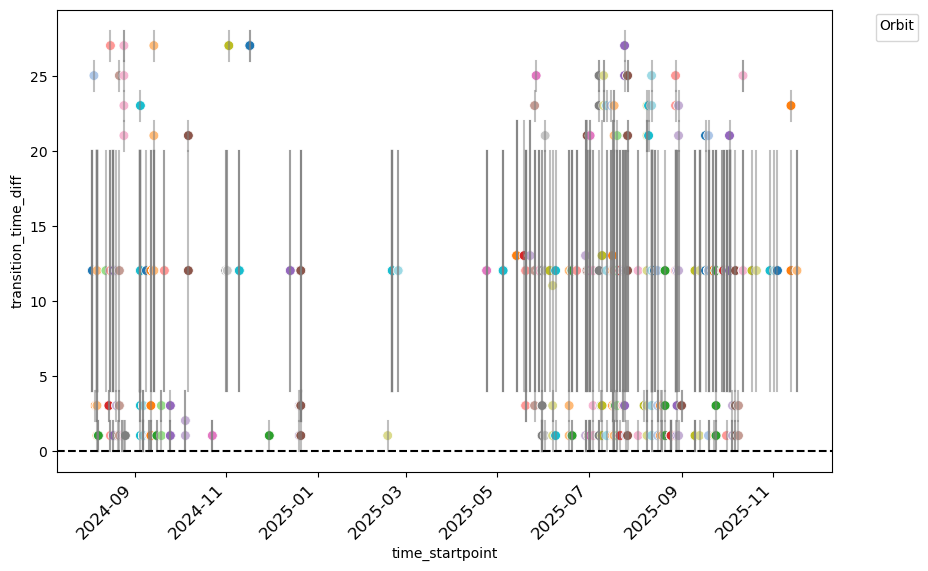

In [11]:
plt.figure(figsize=(10,6))
sns.scatterplot(data = bt_co_back_from_o, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=False, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_co_back_from_o.time_startpoint)):
    if not pd.isna(bt_co_back_from_o.transition_time_diff.values[i]):
        plt.plot([bt_co_back_from_o.time_startpoint.values[i], bt_co_back_from_o.time_startpoint.values[i]], 
                 [bt_co_back_from_o.transition_time_diff.values[i] - bt_co_back_from_o.transition_uncertainty.values[i],
                  bt_co_back_from_o.transition_time_diff.values[i] + bt_co_back_from_o.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

/tmp/ipykernel_3188873/986066155.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)


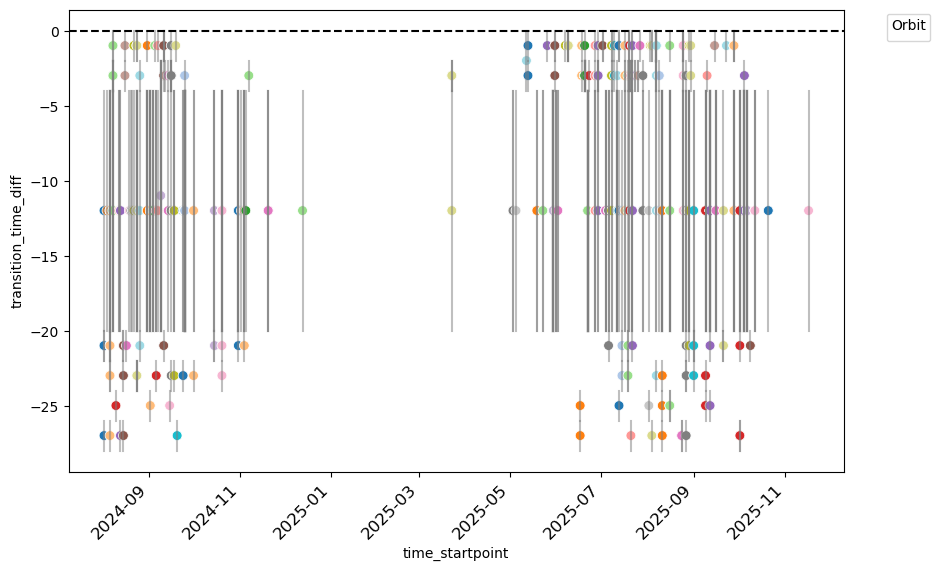

In [9]:
plt.figure(figsize=(10,6))
sns.scatterplot(data = bt_co_forward_from_c, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=False, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_co_forward_from_c.time_startpoint)):
    if not pd.isna(bt_co_forward_from_c.transition_time_diff.values[i]):
        plt.plot([bt_co_forward_from_c.time_startpoint.values[i], bt_co_forward_from_c.time_startpoint.values[i]], 
                 [bt_co_forward_from_c.transition_time_diff.values[i] - bt_co_forward_from_c.transition_uncertainty.values[i],
                  bt_co_forward_from_c.transition_time_diff.values[i] + bt_co_forward_from_c.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

Transition statistics:
Trajectories with transitions: 132
Total trajectories: 1189


/tmp/ipykernel_1463246/2964429737.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Orbit Startpoint', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)


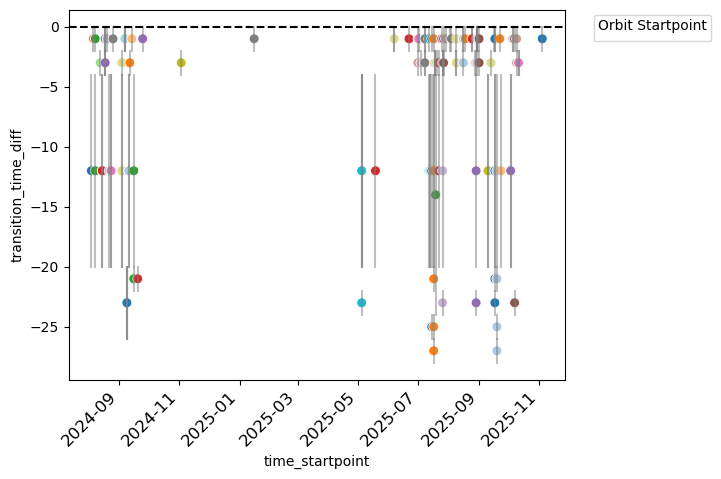

In [28]:
# O -> C transitions
bt_oc_forward_from_o = get_transition_properties(bt_O, transition_from_goes_cats=[2], transition_to_goes_cats=[0,1], backward=False)

# Check results
print("Transition statistics:")
print(f"Trajectories with transitions: {(~pd.isna(bt_oc_forward_from_o.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_oc_forward_from_o.time_startpoint)}")


sns.scatterplot(data = bt_oc_forward_from_o, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=False, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_oc_forward_from_o.time_startpoint)):
    if not pd.isna(bt_oc_forward_from_o.transition_time_diff.values[i]):
        plt.plot([bt_oc_forward_from_o.time_startpoint.values[i], bt_oc_forward_from_o.time_startpoint.values[i]], 
                 [bt_oc_forward_from_o.transition_time_diff.values[i] - bt_oc_forward_from_o.transition_uncertainty.values[i],
                  bt_oc_forward_from_o.transition_time_diff.values[i] + bt_oc_forward_from_o.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit Startpoint', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

### check transition detection visually

In [13]:
bt_co_back_from_o

<xarray.Dataset> Size: 6MB
Dimensions:                  (time_startpoint: 1189, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 10kB 2024-08-03...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 29kB '01040E' ... '08353E'
Data variables: (12/20)
    lat_traj                 (time_startpoint, timestep) float64 409kB -18.36...
    lon_traj                 (time_startpoint, timestep) float64 409kB -77.95...
    plev_traj                (time_startpoint, timestep) float64 409kB 952.3 ...
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 409kB ...
    goes_cats                (time_startpoint, timestep) float64 409kB nan .....
    goes_cert                (time_startpoint, timestep) float64 409kB nan .....
    ...                       ...
    goes_cat_at_ec_overpass  (time_startpoint) float64 10kB 2.0 2.0 ... 2.0 2.0
    transition_flag          (time_startpoint) bool 1kB True True ... True False
    transition_timestep      (time_startpoint) float64 10kB -20.0 -20.0 ... nan
    transition_datetime      (time_startpoint) datetime64[ns] 10kB 2024-08-03...
    transition_time_diff     (time_startpoint) float64 10kB 12.0 12.0 ... nan
    transition_uncertainty   (time_startpoint) float64 10kB -8.0 -8.0 ... nan

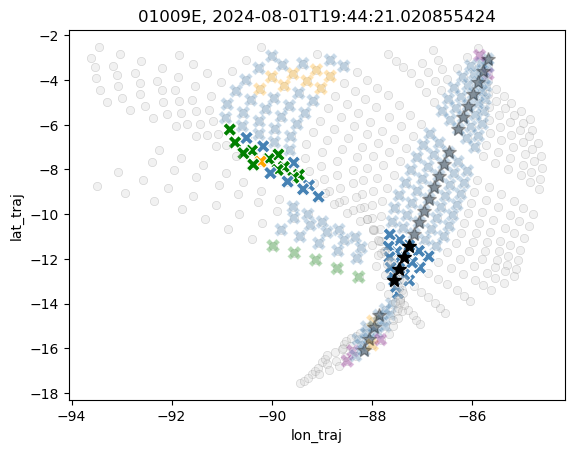

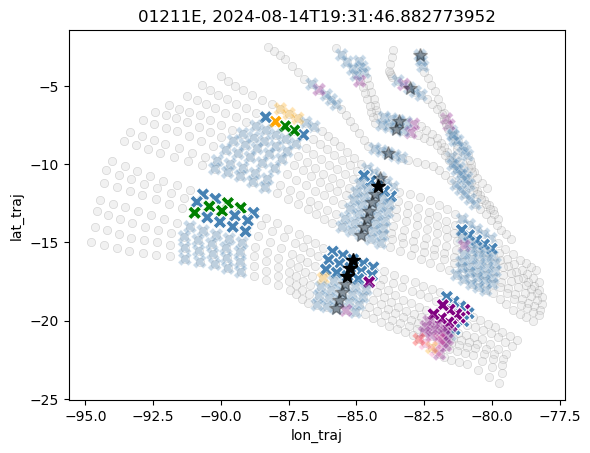

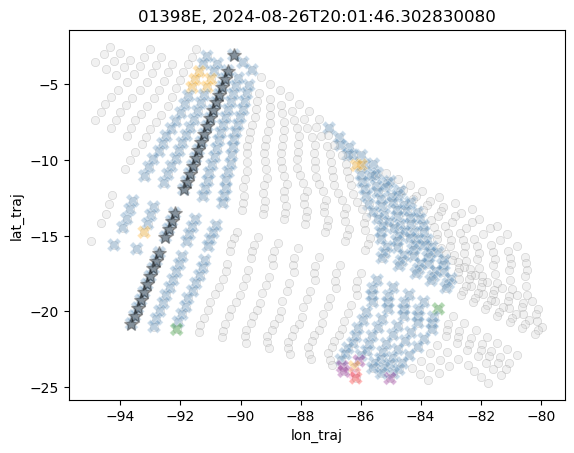

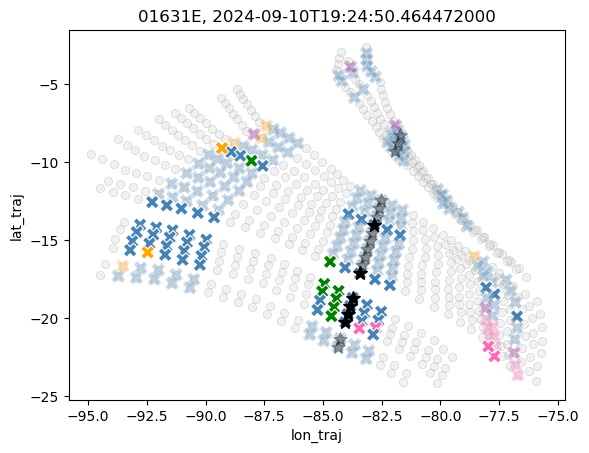

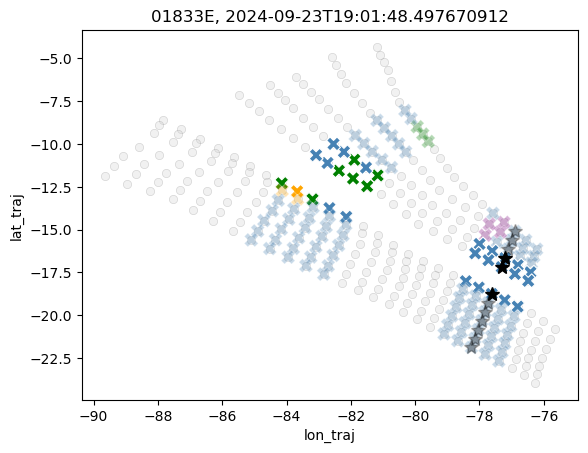

...

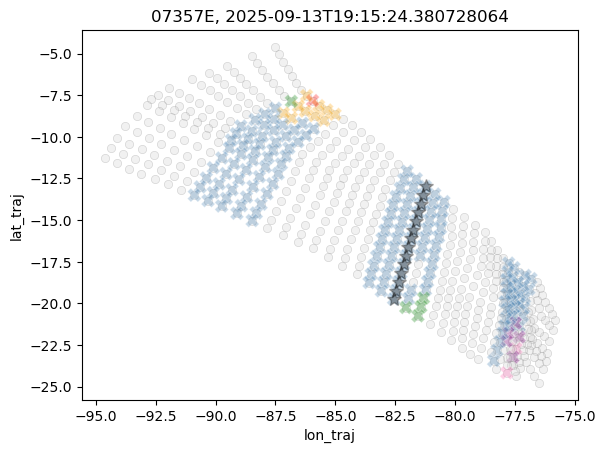

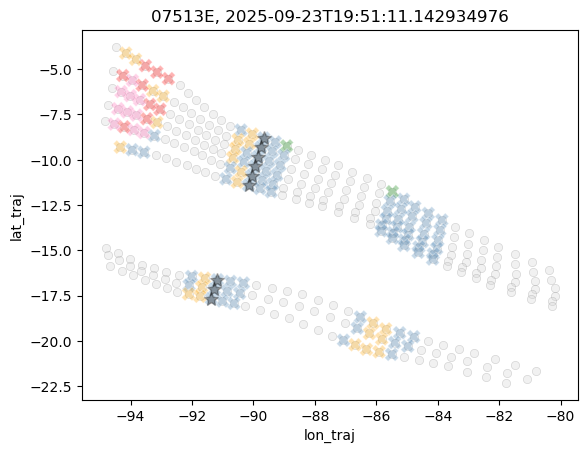

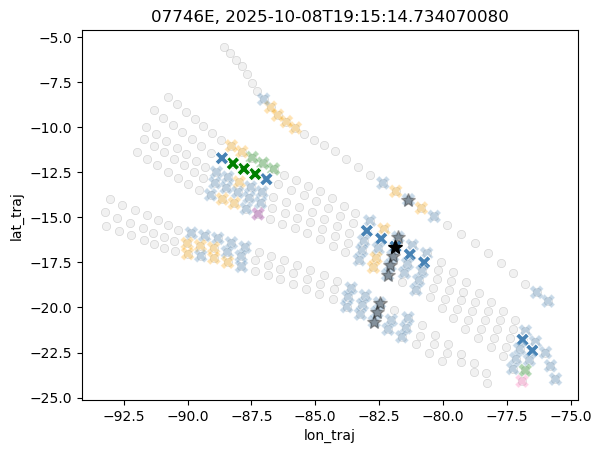

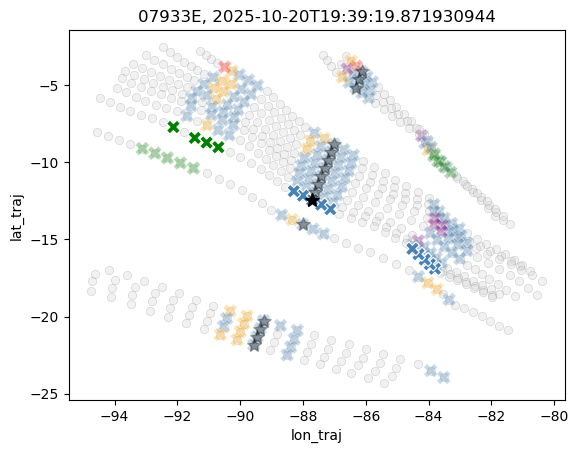

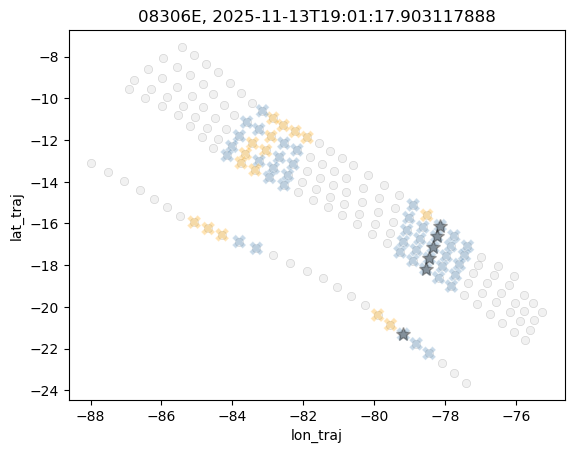

In [14]:
palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

ds_to_check = bt_co_forward_from_c #bt_co_back_from_o

for orbit in np.unique(ds_to_check.orbit)[::10]:
    bt_orbit = ds_to_check.where(ds_to_check.orbit == orbit, drop=True)
    for i in range(len(bt_orbit.time_startpoint)):
        tmp = bt_orbit.isel(time_startpoint=i)
        if tmp.transition_flag == False:
            # no transition detected
            alpha = 0.3
        else:
            # transition detected
            alpha = 1.0
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', color='lightgrey', alpha=0.3, edgecolor='Grey', legend=False)
        plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10, alpha=alpha)
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
    plt.title(f'{orbit}, {bt_orbit.time_startpoint.values[0]}')
    plt.show()

## add ACMCAP information

In [9]:
acmcap_dataset_filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu.h5'
acmcap = pd.read_hdf(acmcap_dataset_filename, key='StCu')

# only need SEP data
acmcap = acmcap[acmcap.stratus_region_index == 2]

ds_acmcap = acmcap.to_xarray()
ds_acmcap = ds_acmcap.rename({'time_mid':'time_startpoint'})
ds_acmcap = ds_acmcap.swap_dims({'index':'time_startpoint'})
ds_acmcap = ds_acmcap.assign_coords({
    'time_startpoint': ds_acmcap.time_startpoint.values,
    'orbit': ('time_startpoint', ds_acmcap.orbit.values)})
ds_acmcap = ds_acmcap.drop_vars(['index'])

ds_acmcap['time_startpoint'] = ds_acmcap.time_startpoint.dt.round('0.1s')
ds_acmcap = ds_acmcap.assign_coords({'timestep': ('timestep', [0])})

ds_acmcap

<xarray.Dataset> Size: 10MB
Dimensions:                               (time_startpoint: 12979, timestep: 1)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 104kB ...
  * timestep                              (timestep) int64 8B 0
    orbit                                 (time_startpoint) object 104kB '010...
Data variables: (12/91)
    scene_id                              (time_startpoint) int64 104kB 25868...
    stratus_region_index                  (time_startpoint) int64 104kB 2 ... 2
    along_track_mid                       (time_startpoint) float64 104kB 128...
    lon_mid                               (time_startpoint) float64 104kB -85...
    lat_mid                               (time_startpoint) float64 104kB -3....
    lat_min                               (time_startpoint) float64 104kB -3....
    ...                                    ...
    rain_rate_mean_perc25                 (time_startpoint) float64 104kB nan...
    rain_rate_mean_perc75                 (time_startpoint) float64 104kB nan...
    rain_rate_mean_perc95                 (time_startpoint) float64 104kB nan...
    rain_gini                             (time_startpoint) float64 104kB 0.0...
    rain_lcf                              (time_startpoint) float64 104kB 0.0...
    rain_n_clusters                       (time_startpoint) int64 104kB 0 ... 3

In [10]:
acmcap_climatology_median = ds_acmcap.where(ds_acmcap.cats.isin([1,2]), drop=True).groupby('cats').median()

/home/jmayer/miniconda3/envs/causal_env/lib/python3.13/site-packages/xarray/structure/concat.py:673: UserWarning: No index created for dimension cats because variable cats is not a coordinate. To create an index for cats, please first call `.set_coords('cats')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


In [11]:
bt_co_forward_from_c['time_startpoint'] = bt_co_forward_from_c.time_startpoint.dt.round('0.1s')

# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_co_forward_from_c, ds_acmcap, join='left')

# Then merge
bt_co_forward_from_c = bt_aligned.merge(acmcap_aligned)

/tmp/ipykernel_3985704/857467339.py:7: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  bt_co_forward_from_c = bt_aligned.merge(acmcap_aligned)


In [12]:
bt_co_forward_from_c

<xarray.Dataset> Size: 15MB
Dimensions:                               (time_startpoint: 2679, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 21kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 21kB '0100...
Data variables: (12/111)
    lat_traj                              (time_startpoint, timestep) float64 922kB ...
    lon_traj                              (time_startpoint, timestep) float64 922kB ...
    plev_traj                             (time_startpoint, timestep) float64 922kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 922kB ...
    goes_cats                             (time_startpoint, timestep) float64 922kB ...
    goes_cert                             (time_startpoint, timestep) float64 922kB ...
    ...                                    ...
    rain_rate_mean_perc25                 (time_startpoint) float64 21kB nan ...
    rain_rate_mean_perc75                 (time_startpoint) float64 21kB nan ...
    rain_rate_mean_perc95                 (time_startpoint) float64 21kB nan ...
    rain_gini                             (time_startpoint) float64 21kB 0.0 ...
    rain_lcf                              (time_startpoint) float64 21kB 0.0 ...
    rain_n_clusters                       (time_startpoint) int64 21kB 0 0 ... 5

In [13]:
bt_co_back_from_o['time_startpoint'] = bt_co_back_from_o.time_startpoint.dt.round('0.1s')

# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_co_back_from_o, ds_acmcap, join='left')

# Then merge
bt_co_back_from_o = bt_aligned.merge(acmcap_aligned)

/tmp/ipykernel_3985704/3443212387.py:7: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  bt_co_back_from_o = bt_aligned.merge(acmcap_aligned)


In [14]:
bt_co_back_from_o

<xarray.Dataset> Size: 7MB
Dimensions:                               (time_startpoint: 1189, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 10kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 10kB '0104...
Data variables: (12/111)
    lat_traj                              (time_startpoint, timestep) float64 409kB ...
    lon_traj                              (time_startpoint, timestep) float64 409kB ...
    plev_traj                             (time_startpoint, timestep) float64 409kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 409kB ...
    goes_cats                             (time_startpoint, timestep) float64 409kB ...
    goes_cert                             (time_startpoint, timestep) float64 409kB ...
    ...                                    ...
    rain_rate_mean_perc25                 (time_startpoint) float64 10kB 1.32...
    rain_rate_mean_perc75                 (time_startpoint) float64 10kB 4.76...
    rain_rate_mean_perc95                 (time_startpoint) float64 10kB 8.78...
    rain_gini                             (time_startpoint) float64 10kB 0.77...
    rain_lcf                              (time_startpoint) float64 10kB 0.29...
    rain_n_clusters                       (time_startpoint) int64 10kB 6 5 ... 5

In [15]:
bt_co_concat = xr.concat([bt_co_forward_from_c, bt_co_back_from_o], dim='time_startpoint')

In [16]:
bt_co_concat

<xarray.Dataset> Size: 22MB
Dimensions:                               (time_startpoint: 3868, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 31kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 31kB '0100...
Data variables: (12/111)
    lat_traj                              (time_startpoint, timestep) float64 1MB ...
    lon_traj                              (time_startpoint, timestep) float64 1MB ...
    plev_traj                             (time_startpoint, timestep) float64 1MB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 1MB ...
    goes_cats                             (time_startpoint, timestep) float64 1MB ...
    goes_cert                             (time_startpoint, timestep) float64 1MB ...
    ...                                    ...
    rain_rate_mean_perc25                 (time_startpoint) float64 31kB nan ...
    rain_rate_mean_perc75                 (time_startpoint) float64 31kB nan ...
    rain_rate_mean_perc95                 (time_startpoint) float64 31kB nan ...
    rain_gini                             (time_startpoint) float64 31kB 0.0 ...
    rain_lcf                              (time_startpoint) float64 31kB 0.0 ...
    rain_n_clusters                       (time_startpoint) int64 31kB 0 0 ... 5

In [ ]:
def add_acmcap_info_to_bt_backup(bt_dataset, acmcap):
    """
    For each trajectory startpoint in bt_dataset, find the corresponding ACMCAP scene(s)
    based on orbit and time, and extract rain rate and other properties if the CATS
    match the specified transition_from_goes_cats.

    Parameters:
    -----------
    bt_dataset : xarray.Dataset
        Dataset with orbit_startpoint and time_startpoint variables
    acmcap : pandas.DataFrame
        ACMCAP dataset with orbit, time, scene_id, cats, rain_rate_cbh, etc.

    Returns:
    --------
    xarray.Dataset
        Dataset with added variables for rain rate and other properties
    """
    acmcap_to_merge = pd.DataFrame(columns=acmcap.columns)
    failed_time_startpoints = []
    for t_ in bt_dataset.time_startpoint.values:
        # skip if no transition was detected
        trans_flag = bt_dataset.sel(time_startpoint=t_).transition_flag
        if trans_flag == False:
            continue
            #acmcap_window =pd.DataFrame([[np.nan]*len(acmcap.columns)], columns=acmcap.columns)

        elif trans_flag == True:
            print(t_)
            orbit = bt_dataset.sel(time_startpoint=t_).orbit.values

            # get ACMCAP data for given scene
            acmcap_window = acmcap[(acmcap.orbit == orbit) & (np.abs(pd.to_datetime(acmcap.time_mid) - pd.to_datetime(t_)) < pd.Timedelta('0.1s'))]
            if len(acmcap_window) == 0:
                print(f'No ACMCAP data found for orbit {orbit} and time {t_}, skipping...')
                failed_time_startpoints.append(t_)
                continue
            elif len(acmcap_window) > 1:
                print(f'Multiple ACMCAP windows found for orbit {orbit} and time {t_}, using first one...')
                acmcap_window = acmcap_window.iloc[0:1]

        acmcap_to_merge = pd.concat([acmcap_to_merge, acmcap_window], ignore_index=True)

    acmcap_to_merge['timestep'] = 0
    acmcap_to_merge.rename(columns={'time_mid':'time_startpoint'}, inplace=True)
    acmcap_to_merge = acmcap_to_merge.set_index(['time_startpoint', 'timestep'])
    acmcap_to_merge = acmcap_to_merge.to_xarray().assign_coords({
                            'time_startpoint': acmcap_to_merge.time_startpoint.values,
                            'timestep': ('timestep', acmcap_to_merge.timestep.values),
                            'orbit': ('time_startpoint', acmcap_to_merge.orbit.values)})
    bt_dataset = bt_dataset.merge(acmcap_to_merge)

    print(f'Failed to find EC window data for {len(failed_time_startpoints)} time_startpoints: {failed_time_startpoints}')

    return bt_dataset

#bt_co_forward_from_c = add_acmcap_info_to_bt_backup(bt_co_forward_from_c, acmcap, judge_SEP)
#bt_co_back_from_o = add_acmcap_info_to_bt_backup(bt_co_back_from_o, acmcap, judge_SEP)

### filter trajectories

In [17]:
# GOES CNN category at overpass should be the same as MSI category
bt_co_concat =bt_co_concat.where(bt_co_concat.goes_cats.sel(timestep=0).drop('timestep') == bt_co_concat.cats, drop=True)

/tmp/ipykernel_3985704/457883729.py:2: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bt_co_concat =bt_co_concat.where(bt_co_concat.goes_cats.sel(timestep=0).drop('timestep') == bt_co_concat.cats, drop=True)


### CO transitions

#### ACMCAP variables as function of time-to-transition

(-30.0, 30.0)

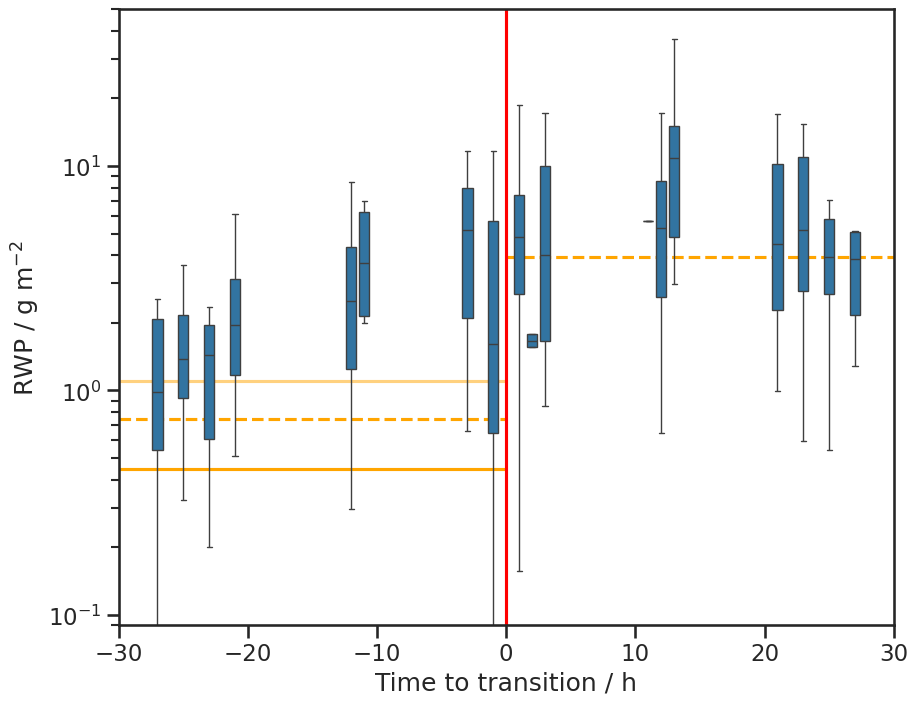

In [19]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

plt.figure(figsize=(10, 8))
plt.hlines(acmcap_climatology_median['rwp'].sel(cats=1)*1e3, xmin=-30, xmax=0, color='orange', linestyle='--')
plt.hlines(acmcap_climatology_median['rwp'].sel(cats=2)*1e3, xmin=0, xmax=30, color='orange', linestyle='--')
plt.hlines(y=bt_non_trans_c['rwp'].median()*1e3, xmin=-30, xmax=0, color='orange', linestyle='-')
plt.hlines(y=bt_non_trans_c['rwp'].quantile(0.25)*1e3, xmin=-30, xmax=0, color='orange', linestyle='-', alpha=0.5)
plt.hlines(y=bt_non_trans_c['rwp'].quantile(0.75)*1e3, xmin=-30, xmax=0, color='orange', linestyle='-', alpha=0.5)

sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp']*1e3, whis=(5, 95), native_scale=True, showfliers=False)
#sns.lineplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp']*1e3)
plt.yscale('log')
plt.ylim(9e-2, 5e1)
#plt.ylim(0, 15)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')
plt.xlim(-30, 30)

<Axes: xlabel='transition_time_diff', ylabel='Count'>

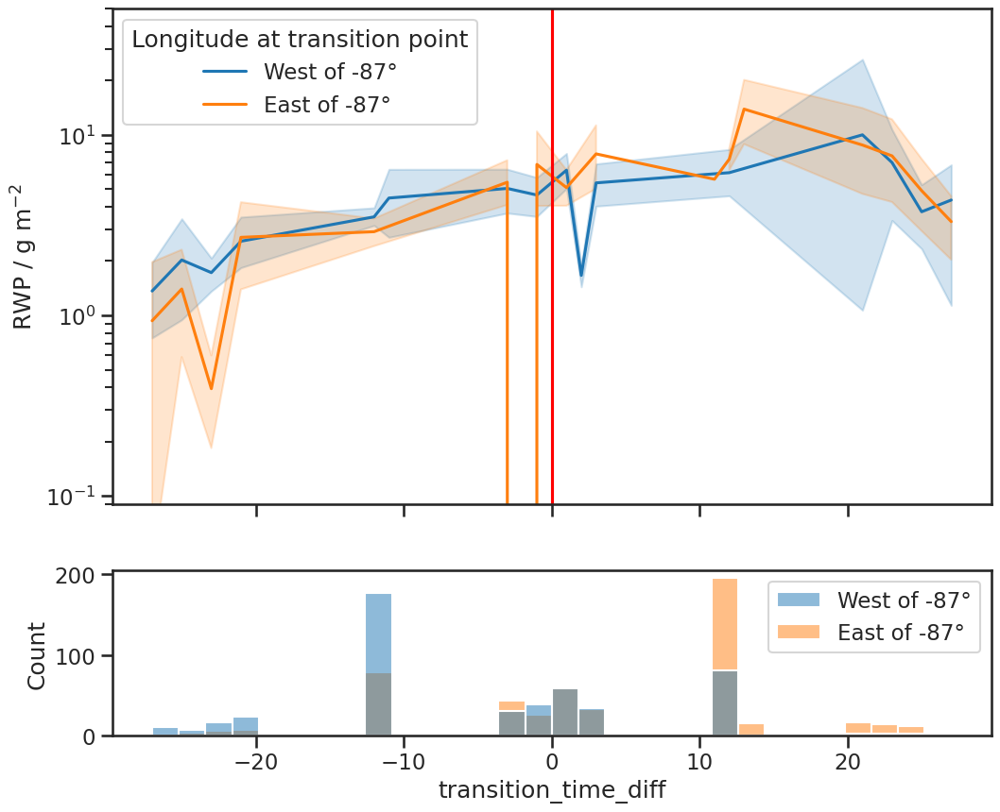

In [45]:
fig, (ax0, ax1) = plt.subplots(2,1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
tmp = bt_co_concat.where(bt_co_concat.transition_flag==1, drop=True)
lon_at_transition = (tmp.sel(timestep=tmp.transition_timestep).lon_traj < -87)
lon_at_transition = np.where(lon_at_transition.values==True, 'West of -87°', 'East of -87°')
sns.lineplot(ax=ax0, data = tmp, x='transition_time_diff', y=tmp['rwp']*1e3, hue=lon_at_transition)
ax0.set_yscale('log')
ax0.set_ylim(9e-2, 5e1)
ax0.legend(title='Longitude at transition point')
ax0.set_xlabel('Time to transition / h')
ax0.set_ylabel('RWP / g m$^{-2}$')
ax0.axvline(0, color='red', linestyle='-')

sns.histplot(ax=ax1, data = tmp, x='transition_time_diff', hue=lon_at_transition, bins=30, color='steelblue', alpha=0.5)

<Axes: xlabel='transition_time_diff', ylabel='Count'>

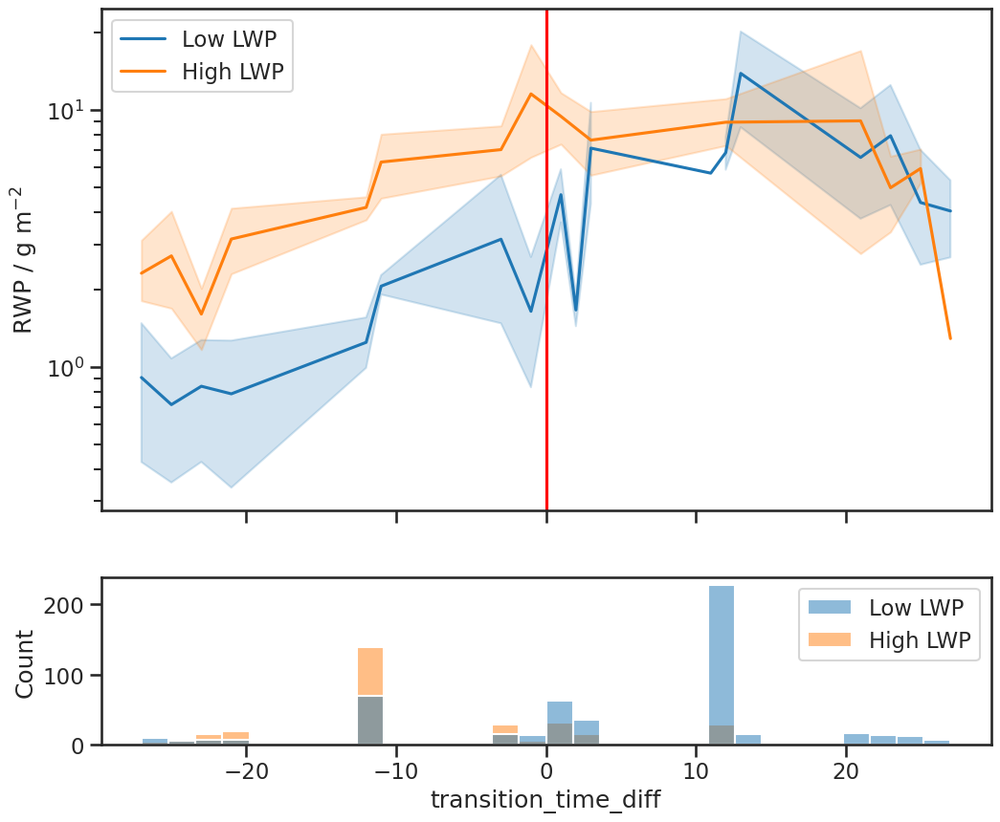

In [27]:
fig, (ax0, ax1) = plt.subplots(2,1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
lwp_bins = (bt_co_concat.lwp > 5e-2)
lwp_bins = np.where(lwp_bins.values==True, 'High LWP', 'Low LWP')
sns.lineplot(ax=ax0, data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp']*1e3, hue=lwp_bins)
ax0.set_yscale('log')
#ax0.legend(title='LWP category')
ax0.set_xlabel('Time to transition / h')
ax0.set_ylabel('RWP / g m$^{-2}$')
ax0.axvline(0, color='red', linestyle='-')

sns.histplot(ax=ax1, data = bt_co_concat, x='transition_time_diff', hue=lwp_bins, bins=30, color='steelblue', alpha=0.5)

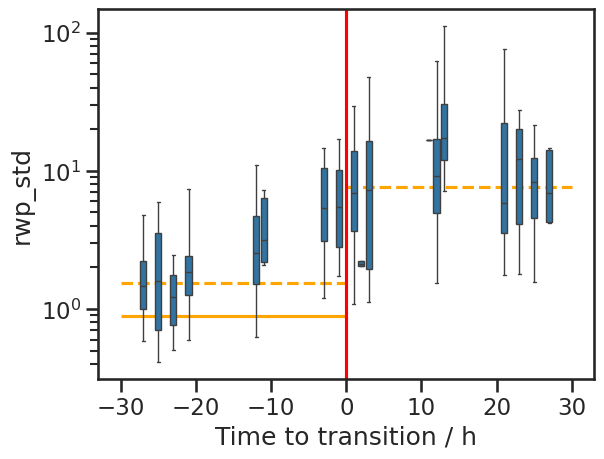

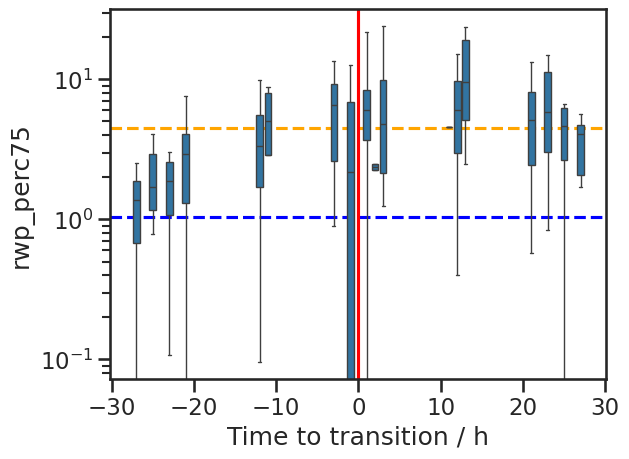

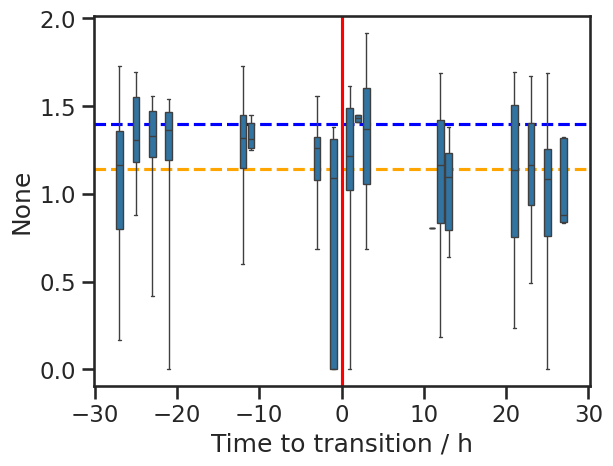

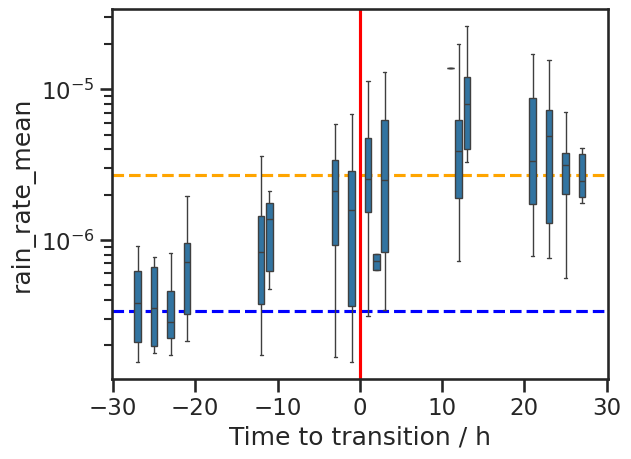

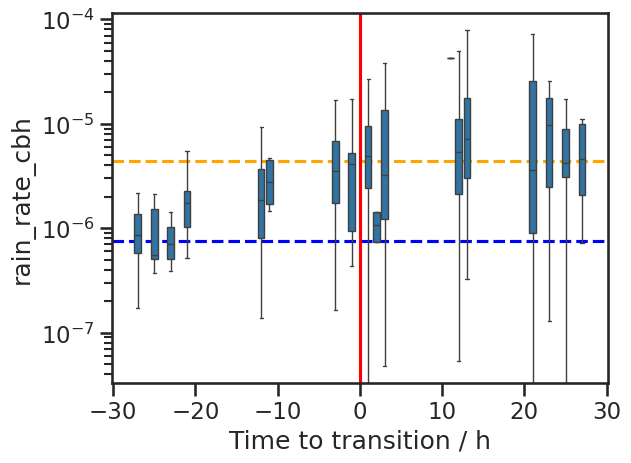

In [29]:
plt.hlines(acmcap_climatology_median['rwp_std'].sel(cats=1)*1e3, xmin=-30, xmax=0, color='orange', linestyle='--')
plt.hlines(acmcap_climatology_median['rwp_std'].sel(cats=2)*1e3, xmin=0, xmax=30, color='orange', linestyle='--')
plt.hlines(y=bt_non_trans_c['rwp_std'].median()*1e3, xmin=-30, xmax=0, color='orange', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp_std']*1e3, whis=(5, 95), native_scale=True, showfliers=False)
plt.yscale('log')
#plt.ylim(1e-7, 2e-4)
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

plt.axhline(acmcap_climatology_median['rwp_perc75'].sel(cats=1)*1e3, color='blue', linestyle='--')
plt.axhline(acmcap_climatology_median['rwp_perc75'].sel(cats=2)*1e3, color='orange', linestyle='--')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp_perc75']*1e3, whis=(5, 95), native_scale=True, showfliers=False)
plt.yscale('log')
#plt.ylim(1e-4, 2e-1)
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

plt.axhline((acmcap_climatology_median['rwp_perc75']/acmcap_climatology_median['rwp']).sel(cats=1), color='blue', linestyle='--')
plt.axhline((acmcap_climatology_median['rwp_perc75']/acmcap_climatology_median['rwp']).sel(cats=2), color='orange', linestyle='--')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp_perc75']/bt_co_concat['rwp'], whis=(5, 95), native_scale=True, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

plt.axhline(acmcap_climatology_median['rain_rate_mean'].sel(cats=1), color='blue', linestyle='--')
plt.axhline(acmcap_climatology_median['rain_rate_mean'].sel(cats=2), color='orange', linestyle='--')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rain_rate_mean'], whis=(5, 95), native_scale=True, showfliers=False)
plt.yscale('log')
#plt.ylim(3e-2, 1e1)
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

plt.axhline(acmcap_climatology_median['rain_rate_cbh'].sel(cats=1), color='blue', linestyle='--')
plt.axhline(acmcap_climatology_median['rain_rate_cbh'].sel(cats=2), color='orange', linestyle='--')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rain_rate_cbh'], whis=(5, 95), native_scale=True, showfliers=False)
plt.yscale('log')
#plt.ylim(3e-2, 1e1)
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

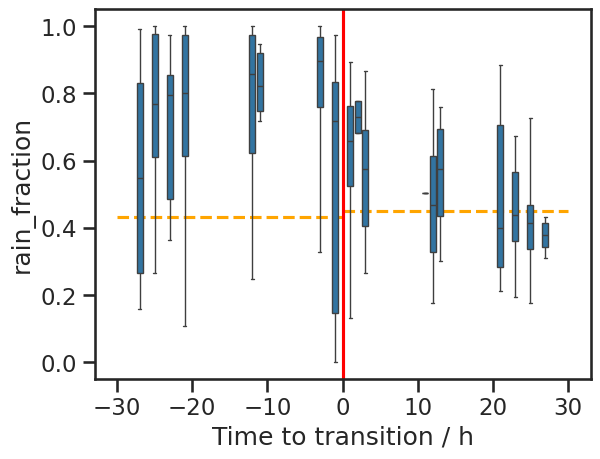

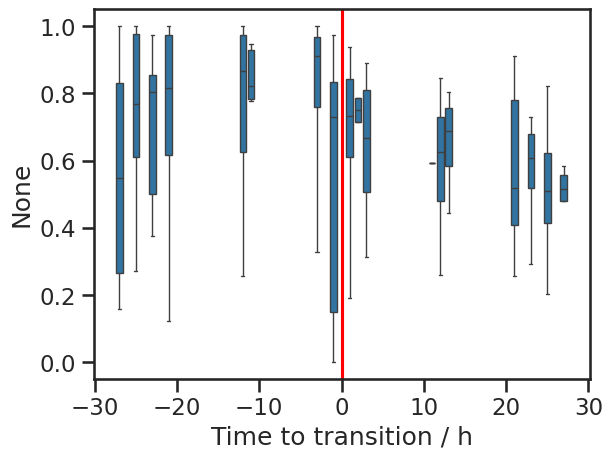

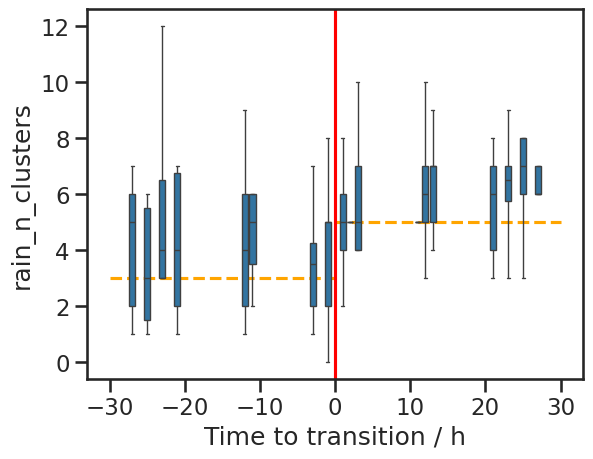

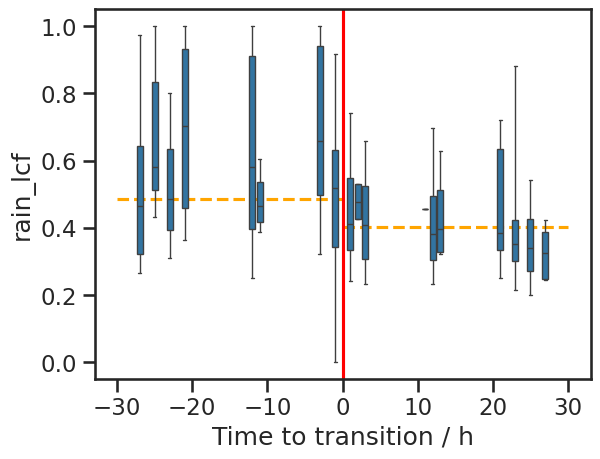

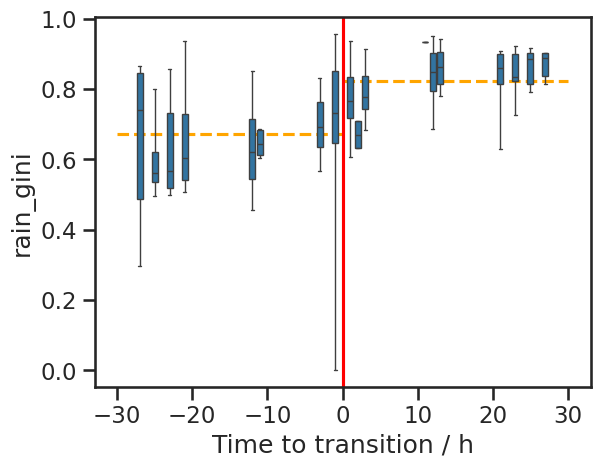

In [28]:
plt.hlines(acmcap_climatology_median['rain_fraction'].sel(cats=1), xmin=-30, xmax=0, color='orange', linestyle='--')
plt.hlines(acmcap_climatology_median['rain_fraction'].sel(cats=2), xmin=0, xmax=30, color='orange', linestyle='--')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rain_fraction'], whis=(5, 95), native_scale=True, showfliers=False)
#plt.ylim(3e-2, 1e1)
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rain_fraction']/bt_co_concat['acmcap_cloud_fraction'], whis=(5, 95), native_scale=True, showfliers=False)
#plt.ylim(3e-2, 1e1)
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

plt.hlines(acmcap_climatology_median['rain_n_clusters'].sel(cats=1), xmin=-30, xmax=0, color='orange', linestyle='--')
plt.hlines(acmcap_climatology_median['rain_n_clusters'].sel(cats=2), xmin=0, xmax=30, color='orange', linestyle='--')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rain_n_clusters'], whis=(5, 95), native_scale=True, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

plt.hlines(acmcap_climatology_median['rain_lcf'].sel(cats=1), xmin=-30, xmax=0, color='orange', linestyle='--')
plt.hlines(acmcap_climatology_median['rain_lcf'].sel(cats=2), xmin=0, xmax=30, color='orange', linestyle='--')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rain_lcf'], whis=(5, 95), native_scale=True, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

plt.hlines(acmcap_climatology_median['rain_gini'].sel(cats=1), xmin=-30, xmax=0, color='orange', linestyle='--')
plt.hlines(acmcap_climatology_median['rain_gini'].sel(cats=2), xmin=0, xmax=30, color='orange', linestyle='--')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rain_gini'], whis=(5, 95), native_scale=True, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

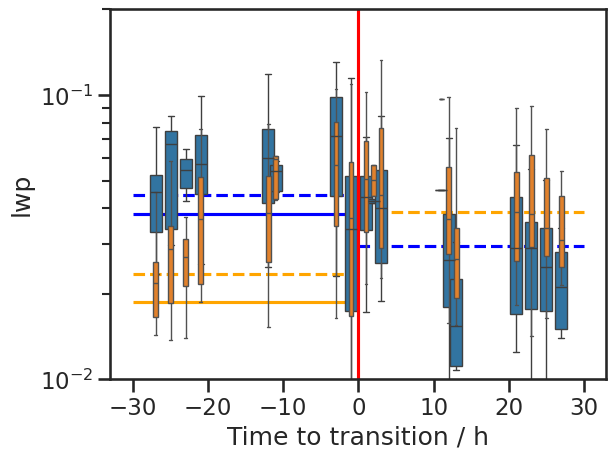

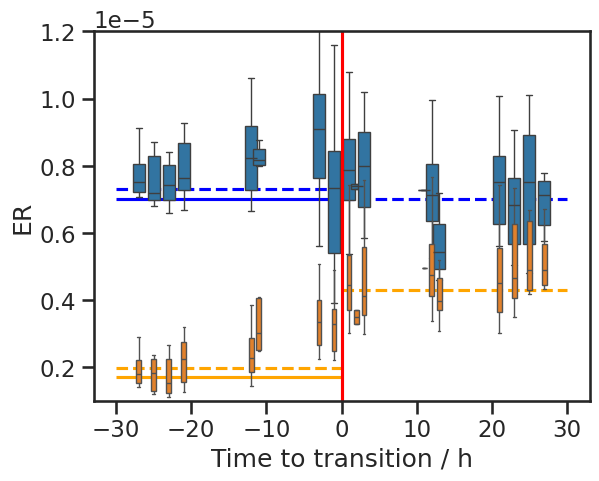

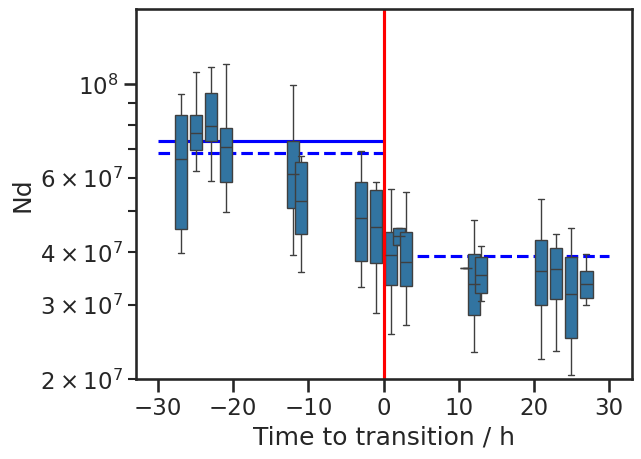

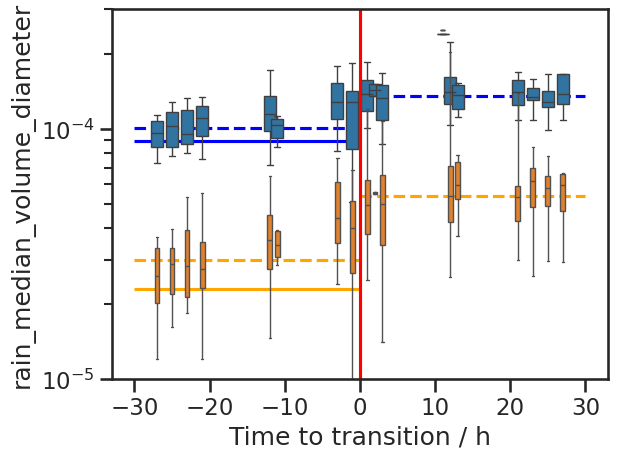

In [48]:
var = 'lwp'
ylim = (1e-2, 2e-1)
yscale = 'log'
plt.hlines(acmcap_climatology_median[var].sel(cats=1), xmin=-30, xmax=0, color='blue', linestyle='--')
plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=0, xmax=30, color='blue', linestyle='--')
plt.hlines(y=bt_non_trans_c[var].median(), xmin=-30, xmax=0, color='blue', linestyle='-')
plt.hlines(acmcap_climatology_median[var+'_std'].sel(cats=1), xmin=-30, xmax=0, color='orange', linestyle='--')
plt.hlines(acmcap_climatology_median[var+'_std'].sel(cats=2), xmin=0, xmax=30, color='orange', linestyle='--')
plt.hlines(y=bt_non_trans_c[var+'_std'].median(), xmin=-30, xmax=0, color='orange', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=3, showfliers=False)
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var+'_std', whis=(5, 95), native_scale=True, gap=1.8, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.yscale(yscale)
plt.ylim(ylim)
plt.xlabel('Time to transition / h')
plt.show()

var = 'ER'
ylim = (1e-6, 12e-6)
yscale = 'linear'
plt.hlines(acmcap_climatology_median[var].sel(cats=1), xmin=-30, xmax=0, color='blue', linestyle='--')
plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=0, xmax=30, color='blue', linestyle='--')
plt.hlines(y=bt_non_trans_c[var].median(), xmin=-30, xmax=0, color='blue', linestyle='-')
plt.hlines(acmcap_climatology_median[var+'_std'].sel(cats=1), xmin=-30, xmax=0, color='orange', linestyle='--')
plt.hlines(acmcap_climatology_median[var+'_std'].sel(cats=2), xmin=0, xmax=30, color='orange', linestyle='--')
plt.hlines(y=bt_non_trans_c[var+'_std'].median(), xmin=-30, xmax=0, color='orange', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=3, showfliers=False)
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var+'_std', whis=(5, 95), native_scale=True, gap=1.8, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.yscale(yscale)
plt.ylim(ylim)
plt.xlabel('Time to transition / h')
plt.show()

var = 'Nd'
ylim = (2e7, 1.5e8)
yscale = 'log'
plt.hlines(acmcap_climatology_median[var].sel(cats=1), xmin=-30, xmax=0, color='blue', linestyle='--')
plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=0, xmax=30, color='blue', linestyle='--')
plt.hlines(y=bt_non_trans_c[var].median(), xmin=-30, xmax=0, color='blue', linestyle='-')
#plt.hlines(acmcap_climatology_median[var+'_std'].sel(cats=1), xmin=-30, xmax=0, color='orange', linestyle='--')
#plt.hlines(acmcap_climatology_median[var+'_std'].sel(cats=2), xmin=0, xmax=30, color='orange', linestyle='--')
#plt.hlines(y=bt_non_trans_c[var+'_std'].median(), xmin=-30, xmax=0, color='orange', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=3, showfliers=False)
#sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var+'_std', whis=(5, 95), native_scale=True, gap=1.8, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.yscale(yscale)
plt.ylim(ylim)
plt.xlabel('Time to transition / h')
plt.show()

var = 'rain_median_volume_diameter'
ylim = (1e-5, 3e-4)
yscale = 'log'
plt.hlines(acmcap_climatology_median[var].sel(cats=1), xmin=-30, xmax=0, color='blue', linestyle='--')
plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=0, xmax=30, color='blue', linestyle='--')
plt.hlines(y=bt_non_trans_c[var].median(), xmin=-30, xmax=0, color='blue', linestyle='-')
plt.hlines(acmcap_climatology_median[var+'_std'].sel(cats=1), xmin=-30, xmax=0, color='orange', linestyle='--')
plt.hlines(acmcap_climatology_median[var+'_std'].sel(cats=2), xmin=0, xmax=30, color='orange', linestyle='--')
plt.hlines(y=bt_non_trans_c[var+'_std'].median(), xmin=-30, xmax=0, color='orange', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=3, showfliers=False)
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var+'_std', whis=(5, 95), native_scale=True, gap=1.8, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.yscale(yscale)
plt.ylim(ylim)
plt.xlabel('Time to transition / h')
plt.show()

In [22]:
bt_co_concat

<xarray.Dataset> Size: 15MB
Dimensions:                               (time_startpoint: 2745, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 22kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 22kB '0100...
Data variables: (12/94)
    lat_traj                              (time_startpoint, timestep) float64 944kB ...
    lon_traj                              (time_startpoint, timestep) float64 944kB ...
    plev_traj                             (time_startpoint, timestep) float64 944kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 944kB ...
    goes_cats                             (time_startpoint, timestep) float64 944kB ...
    goes_cert                             (time_startpoint, timestep) float64 944kB ...
    ...                                    ...
    rwp_perc25                            (time_startpoint) float64 22kB 0.0 ...
    rwp_perc75                            (time_startpoint) float64 22kB 0.0 ...
    rain_median_volume_diameter_std       (time_startpoint) float64 22kB 1.93...
    rain_median_volume_diameter_median    (time_startpoint) float64 22kB 9.52...
    rain_median_volume_diameter_perc25    (time_startpoint) float64 22kB 8.93...
    rain_median_volume_diameter_perc75    (time_startpoint) float64 22kB 9.55...

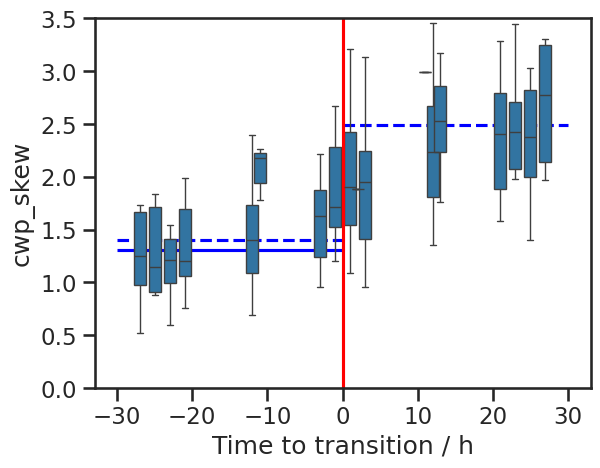

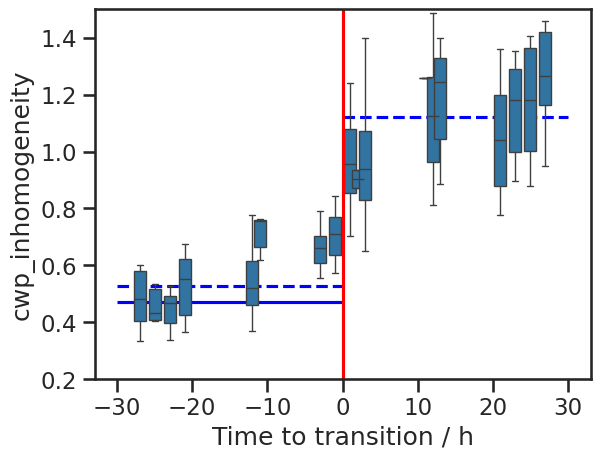

In [28]:
var = 'cwp_skew'
ylim = (0, 3.5)
yscale = 'linear'
plt.hlines(acmcap_climatology_median[var].sel(cats=1), xmin=-30, xmax=0, color='blue', linestyle='--')
plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=0, xmax=30, color='blue', linestyle='--')
plt.hlines(y=bt_non_trans_c[var].median(), xmin=-30, xmax=0, color='blue', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=3, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.yscale(yscale)
plt.ylim(ylim)
plt.xlabel('Time to transition / h')
plt.show()

var = 'cwp_inhomogeneity'
ylim = (0.2, 1.5)
yscale = 'linear'
plt.hlines(acmcap_climatology_median[var].sel(cats=1), xmin=-30, xmax=0, color='blue', linestyle='--')
plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=0, xmax=30, color='blue', linestyle='--')
plt.hlines(y=bt_non_trans_c[var].median(), xmin=-30, xmax=0, color='blue', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=3, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.yscale(yscale)
plt.ylim(ylim)
plt.xlabel('Time to transition / h')
plt.show()

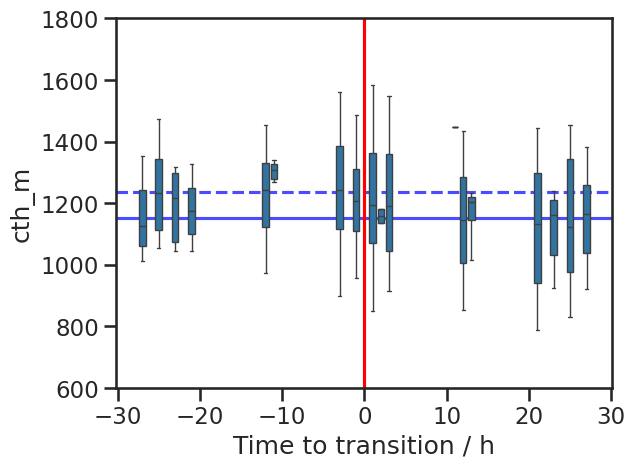

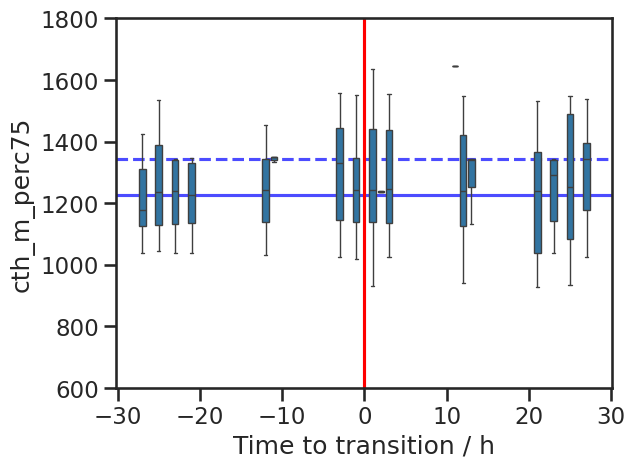

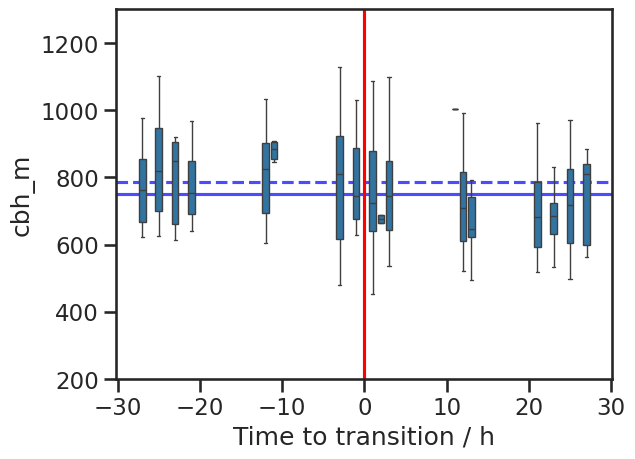

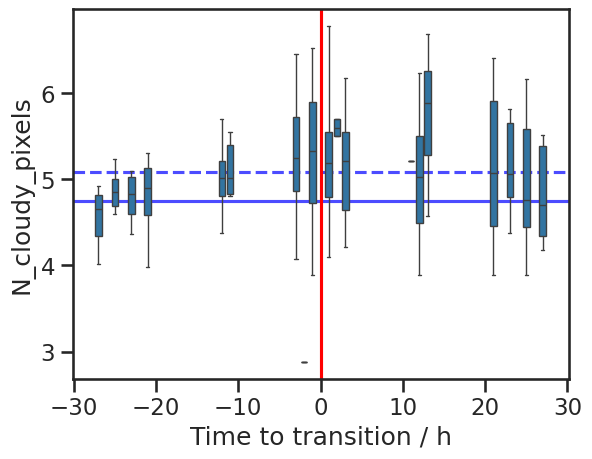

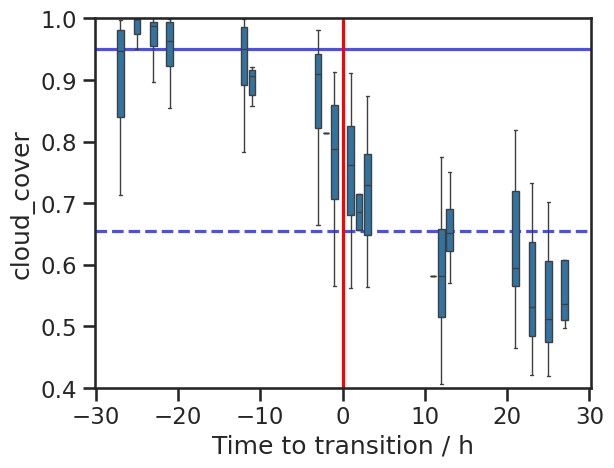

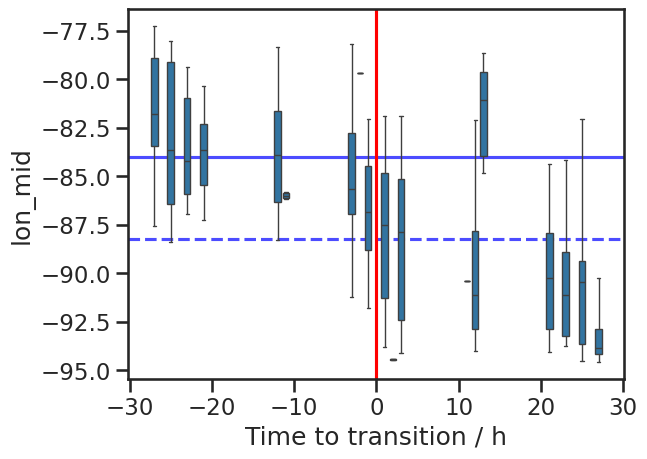

In [57]:
for var in ['cth_m', 'cth_m_perc75', 'cbh_m', 'N_cloudy_pixels', 'cloud_cover', 'lon_mid']:
    if var in ['cth_m', 'cth_m_perc75']:
        plt.ylim(600, 1800)
    elif var == 'cbh_m':
        plt.ylim(200, 1300)
    elif var == 'cloud_cover':
        plt.ylim(0.4, 1)
    plt.axhline(acmcap_climatology_median[var].sel(cats=1), color='blue', linestyle='-', alpha=0.7)
    plt.axhline(acmcap_climatology_median[var].sel(cats=2), color='blue', linestyle='--', alpha=0.7)
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, showfliers=False)
    plt.axvline(0, color='red', linestyle='-')
    plt.xlabel('Time to transition / h')
    plt.show()

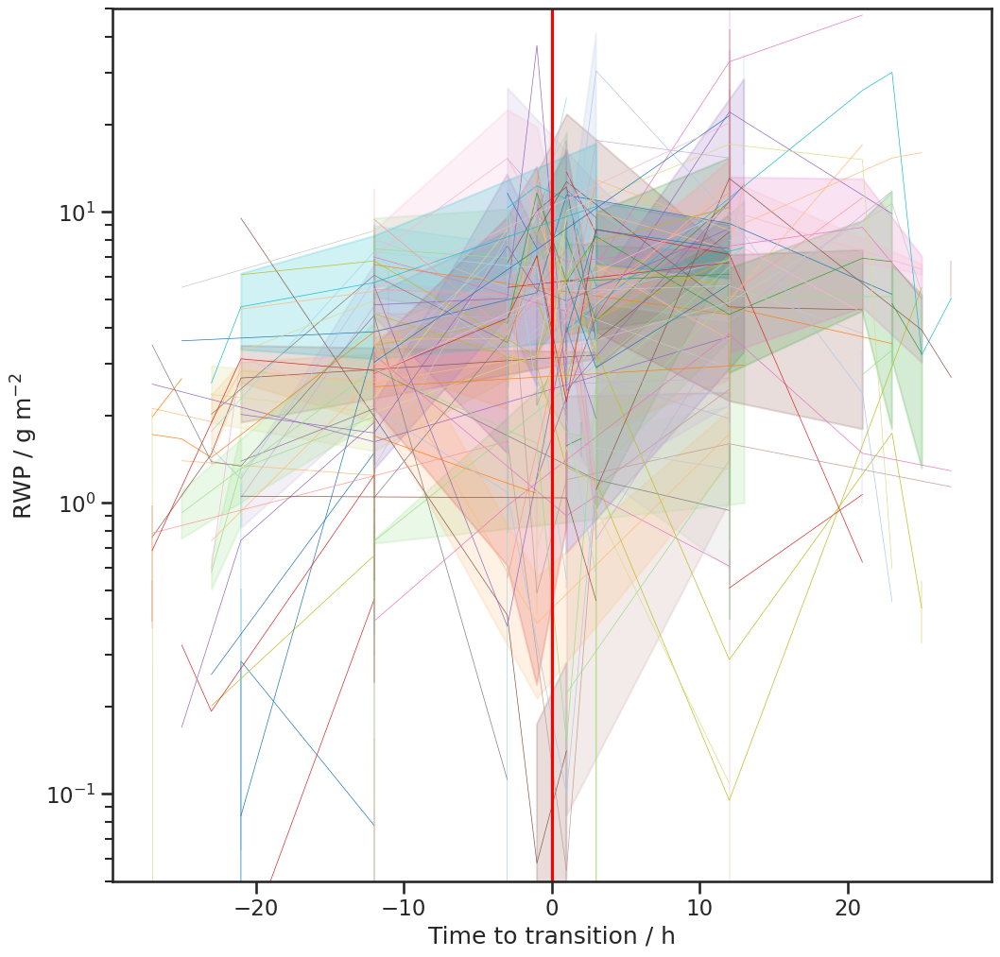

In [62]:
plt.figure(figsize=(12,12))
sns.lineplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp']*1e3, hue='orbit', palette='tab20', legend=False, lw=0.5, errorbar="ci")
plt.yscale('log')
#plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.ylim(5e-2, 5e1)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

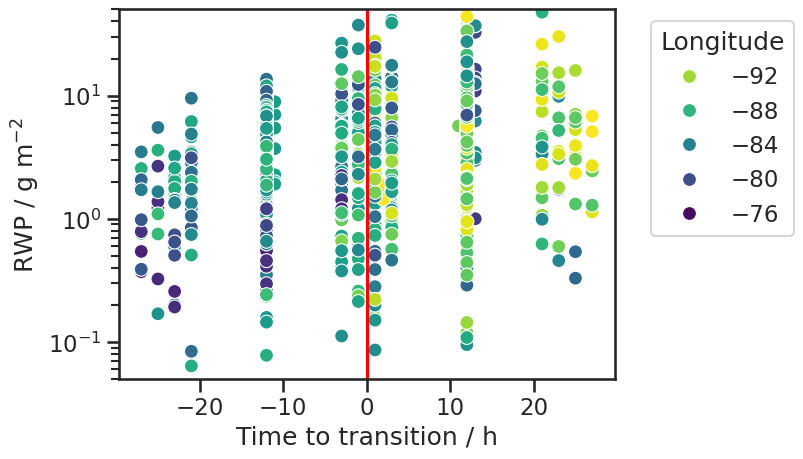

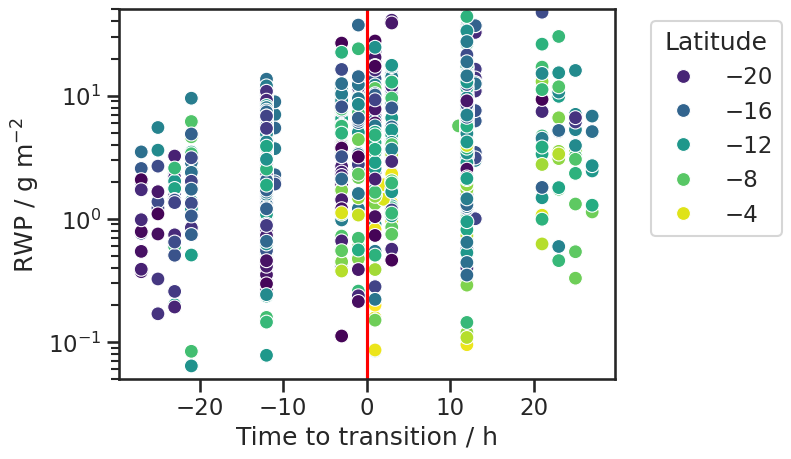

In [82]:
from matplotlib.colors import LogNorm
sns.scatterplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp']*1e3, hue='lon_traj', palette='viridis_r', legend=True, s=100)
plt.yscale('log')
plt.legend(title='Longitude', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylim(5e-2, 5e1)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')
plt.show()

sns.scatterplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp']*1e3, hue='lat_traj', palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.legend(title='Latitude', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylim(5e-2, 5e1)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

/tmp/ipykernel_1476150/523902182.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


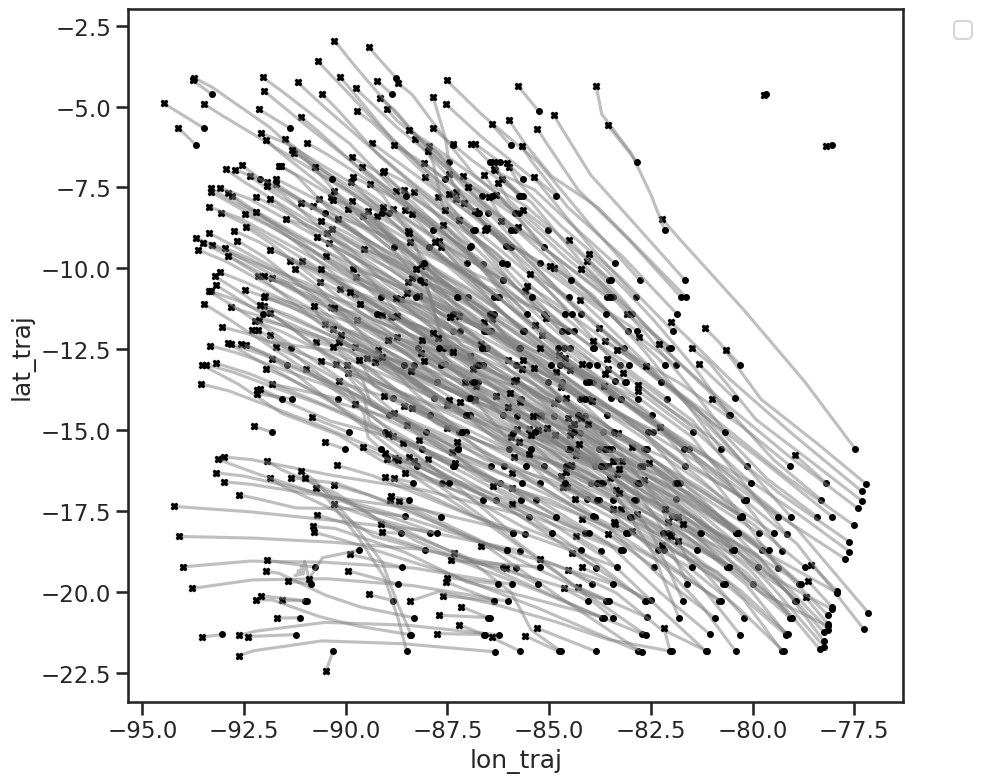

KeyError: "not all values found in index 'timestep'. Try setting the `method` keyword argument (example: method='nearest')."

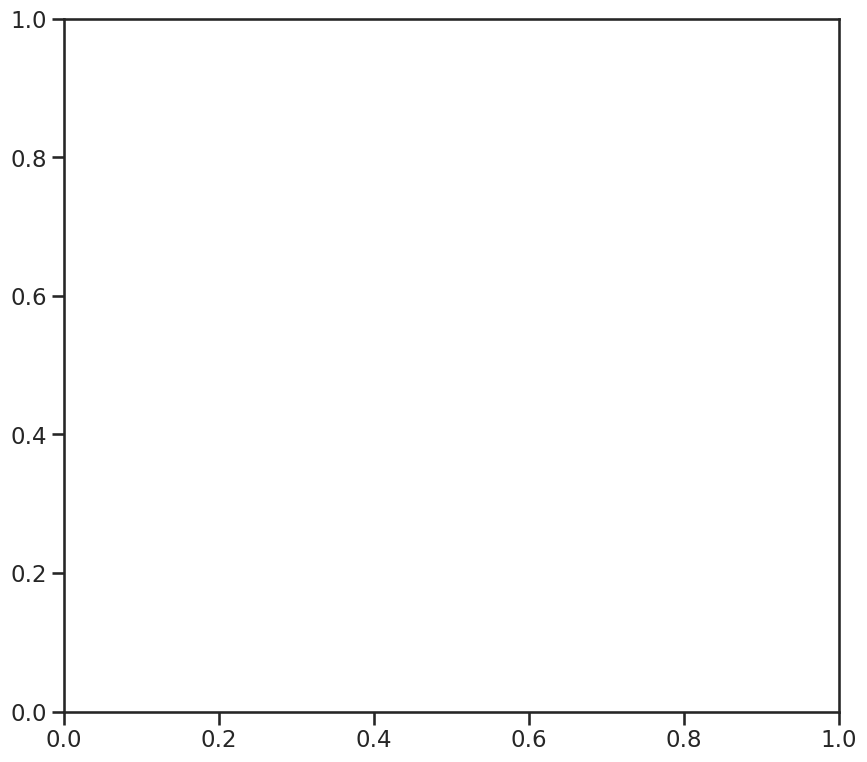

In [ ]:

plt.figure(figsize=(10, 9))
bt_co_forward_from_c_with_trans = bt_co_forward_from_c.where(~ np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True)
for startpoint in bt_co_forward_from_c_with_trans.time_startpoint.values:
    tmp = bt_co_forward_from_c_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(0,50)).sortby('timestep')
    #orbit = tmp.orbit_startpoint.values
    transition_timestep = tmp.transition_timestep.values
    tmp = tmp.sel(timestep=slice(0,transition_timestep+1))
    sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=4)
    plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=7, color='black')
    #sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=50, marker='o')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

plt.figure(figsize=(10, 9))
bt_co_back_from_o_with_trans = bt_co_back_from_o.where(~ np.isnan(bt_co_back_from_o.transition_time_diff) & ~np.isnan(bt_co_back_from_o.lwp), drop=True)
for startpoint in bt_co_back_from_o_with_trans.time_startpoint.values:
    tmp = bt_co_back_from_o_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(-50,1)).sortby('timestep')
    #orbit = tmp.orbit_startpoint.values
    transition_timestep = tmp.transition_timestep.values
    tmp = tmp.sel(timestep=slice(0,transition_timestep+1))
    sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=4)
    plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=7, color='black')
    #sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=50, marker='o')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

#### compare CO clouds with non-transitioning clouds

In [32]:
bt_c_non_co_trans = bt_co_forward_from_c.where(bt_co_forward_from_c.transition_flag==False, drop=True)
tmp = bt_c_non_co_trans.sel(timestep = slice(0,30)).goes_cats.fillna(-1)
enough_datapoints_along_track = (tmp.isin([0,1,2,3,4,5]).sum(dim='timestep')) >= 6
always_closed_cell = tmp.isin([-1,1]).all(dim='timestep')

bt_non_trans_c = bt_c_non_co_trans.where(enough_datapoints_along_track & always_closed_cell, drop=True)
print(f'Number of trajectories that stay closed-cell: {len(bt_non_trans_c.time_startpoint)}')

bt_co_transitioning_c = bt_co_forward_from_c.where(bt_co_forward_from_c.transition_flag == True, drop=True)
print(f'Number of trajectories that transition from closed to open cell: {len(bt_co_transitioning_c.time_startpoint)}')

Number of trajectories that stay closed-cell: 382
Number of trajectories that transition from closed to open cell: 472


In [23]:
bt_non_trans_c

<xarray.Dataset> Size: 2MB
Dimensions:                               (time_startpoint: 382, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 3kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 3kB '01009...
Data variables: (12/94)
    lat_traj                              (time_startpoint, timestep) float64 131kB ...
    lon_traj                              (time_startpoint, timestep) float64 131kB ...
    plev_traj                             (time_startpoint, timestep) float64 131kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 131kB ...
    goes_cats                             (time_startpoint, timestep) float64 131kB ...
    goes_cert                             (time_startpoint, timestep) float64 131kB ...
    ...                                    ...
    rwp_perc25                            (time_startpoint) float64 3kB 0.0 ....
    rwp_perc75                            (time_startpoint) float64 3kB 0.0 ....
    rain_median_volume_diameter_std       (time_startpoint) float64 3kB nan ....
    rain_median_volume_diameter_median    (time_startpoint) float64 3kB nan ....
    rain_median_volume_diameter_perc25    (time_startpoint) float64 3kB nan ....
    rain_median_volume_diameter_perc75    (time_startpoint) float64 3kB nan ....

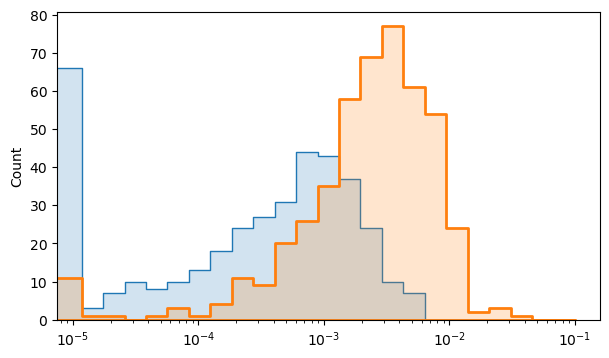

In [ ]:
bins = np.logspace(-5.1, -1, 25)
bins[0] = 0
plt.figure(figsize=(7, 4))
sns.histplot(bt_non_trans_c.rwp, bins=bins, alpha=0.2, element='step')

sns.histplot(bt_co_transitioning_c.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

In [ ]:
#bt_cc_forward_from_c['flag_neighboring_transitioning'] = xr.DataArray(np.zeros(len(bt_cc_forward_from_c.time_startpoint), dtype=bool), dims='time_startpoint', coords={'time_startpoint': bt_cc_forward_from_c.time_startpoint.values})
#for i in range(len(bt_cc_forward_from_c.time_startpoint)):
#    time_diff_to_transitioning_traj = np.abs(bt_cc_forward_from_c.time_startpoint.values[i] - bt_co_forward_from_c_transitioning.time_startpoint.values).min() / np.timedelta64(1, 's')
#    if time_diff_to_transitioning_traj <= 15:  # within 15 seconds
#        bt_cc_forward_from_c['flag_neighboring_transitioning'].values[i] = True
#
#bt_cc_forward_from_c['flag_neighboring_open_cells'] = xr.DataArray(np.zeros(len(bt_cc_forward_from_c.time_startpoint), dtype=bool), dims='time_startpoint', coords={'time_startpoint': bt_cc_forward_from_c.time_startpoint.values})
#for i in range(len(bt_cc_forward_from_c.time_startpoint)):
#    t_ = bt_cc_forward_from_c.time_startpoint.values[i] 
#    cats_in_neighborhood = judge_SEP[np.abs(pd.to_datetime(judge_SEP.time_mid) - t_) < pd.Timedelta('10s')]['cats']
#    if 2 in cats_in_neighborhood.values:
#        bt_cc_forward_from_c['flag_neighboring_open_cells'].values[i] = True

<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2111205/3804739664.py:45: SyntaxWarning: invalid escape sequence '\m'
  ax[1].set_xlabel('ER / $\mu$')


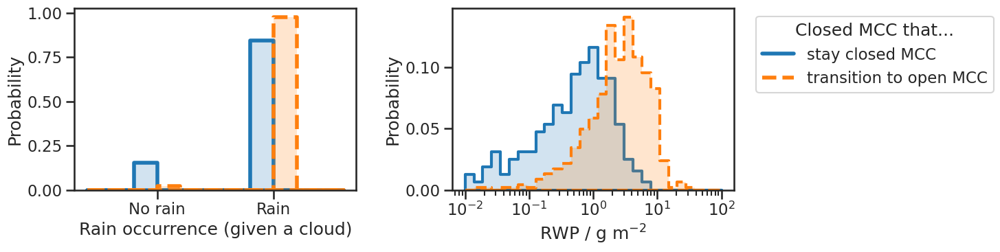

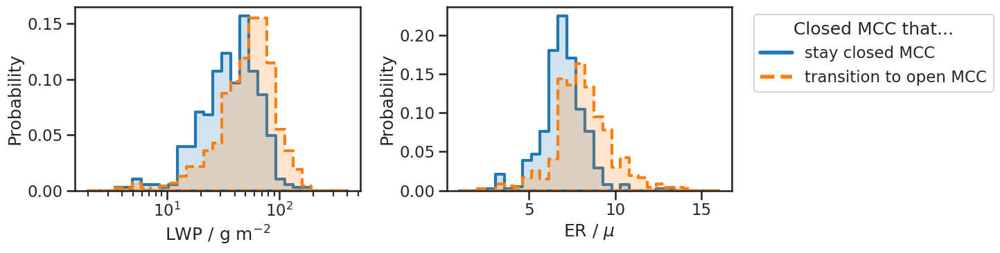

In [31]:
line_styles = ['-', '--', '-.']
colors = sns.color_palette('tab10')
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False


fig, ax = plt.subplots(1,2, figsize=(11, 4))
for j,dffil in enumerate([bt_non_trans_c, bt_co_transitioning_c]):
    sns.histplot(ax=ax[0], x=(dffil['rwp'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                 element='step', alpha=0.2, stat='probability', lw=4, color=colors[j], ls=line_styles[j])
    sns.histplot(
        ax=ax[1], x=dffil['rwp']*1e3, bins=np.logspace(-2,2,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
ax[1].set_xscale('log')
ax[1].set_xlabel('RWP / g m$^{-2}$')
ax[0].set_xticks([0.1,1.1])
ax[0].set_xticklabels(['No rain', 'Rain'])
ax[0].set_xlabel('Rain occurrence (given a cloud)')
fig.tight_layout()
legend_handles = [
    plt.Line2D([0], [0], color=colors[0], lw=4, ls=line_styles[0], label='stay closed MCC'),
    plt.Line2D([0], [0], color=colors[1], lw=4, ls=line_styles[1], label='transition to open MCC')
]
ax[1].legend(title='Closed MCC that...', handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left')


fig, ax = plt.subplots(1,2, figsize=(11, 4))
for j,dffil in enumerate([bt_non_trans_c, bt_co_transitioning_c]):
    sns.histplot(
        ax=ax[0], x=dffil['lwp']*1e3, bins=np.logspace(0.3,2.6,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
    sns.histplot(
        ax=ax[1], x=dffil['ER']*1e6, bins=np.linspace(1,16,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
ax[0].set_xscale('log')
ax[0].set_xlabel('LWP / g m$^{-2}$')
ax[1].set_xscale('linear')
ax[1].set_xlabel('ER / $\mu$')
fig.tight_layout()
legend_handles = [
    plt.Line2D([0], [0], color=colors[0], lw=4, ls=line_styles[0], label='stay closed MCC'),
    plt.Line2D([0], [0], color=colors[1], lw=4, ls=line_styles[1], label='transition to open MCC')
]
ax[1].legend(title='Closed MCC that...', handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left')

/tmp/ipykernel_1638429/533491473.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
/tmp/ipykernel_1638429/533491473.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
/tmp/ipykernel_1638429/533491473.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warni

Text(0.5, 1.0, 'Mean RWP given LWP')

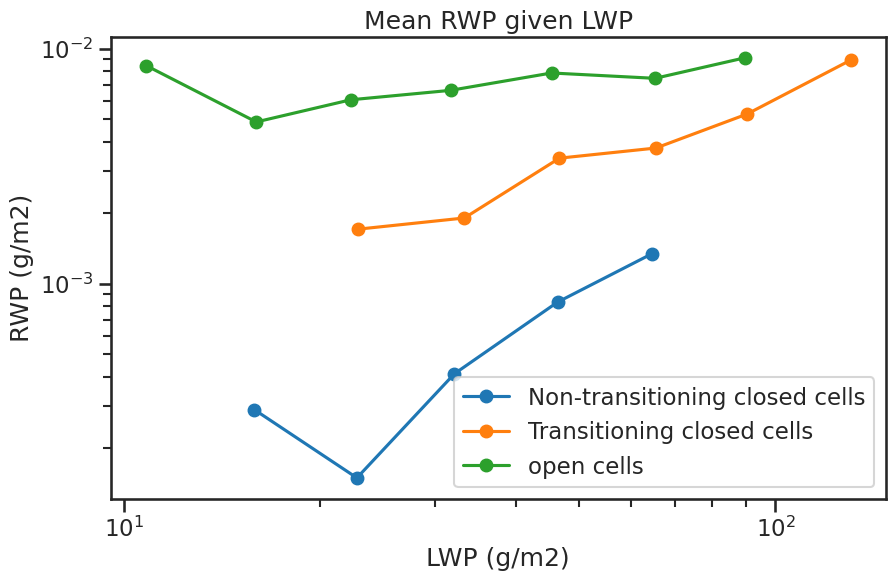

In [70]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for tmp, label in [(bt_non_trans_c, 'Non-transitioning closed cells'), (bt_co_transitioning_c, 'Transitioning closed cells'), (bt_co_back_from_o.where(bt_co_back_from_o.transition_flag == True, drop=True), 'open cells')]:
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    tmp['lwp'] = tmp['lwp']*1e3  # convert to g/m2
    #tmp['rwp'] = tmp['rwp']*1e3  # convert to g/m2
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=label)
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('LWP (g/m2)')
plt.ylabel('RWP (g/m2)')
plt.title('Mean RWP given LWP')

/tmp/ipykernel_2111205/4211940507.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lwp_std_given_lwp = tmp[['lwp','lwp_std']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
/tmp/ipykernel_2111205/4211940507.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lwp_std_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
/tmp/ipykernel_2111205/4211940507.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and sil

Text(0.5, 1.0, 'Mean lwp_std given LWP')

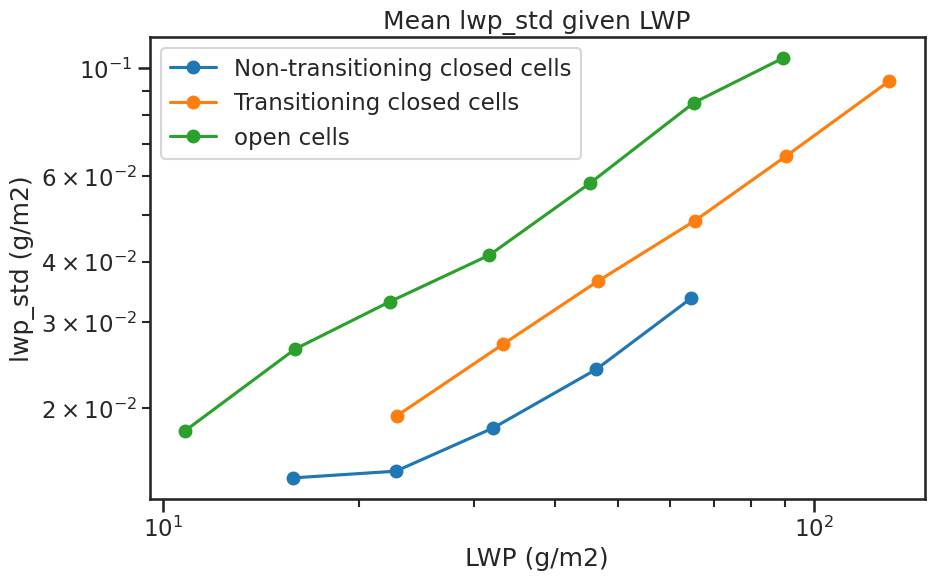

In [32]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for tmp, label in [(bt_non_trans_c, 'Non-transitioning closed cells'), (bt_co_transitioning_c, 'Transitioning closed cells'), (bt_co_back_from_o.where(bt_co_back_from_o.transition_flag == True, drop=True), 'open cells')]:
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    tmp['lwp'] = tmp['lwp']*1e3  # convert to g/m2
    #tmp['lwp_std'] = tmp['lwp_std']*1e3  # convert to g/m2
    lwp_std_given_lwp = tmp[['lwp','lwp_std']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    lwp_std_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    lwp_std_given_lwp['lwp_std'] = lwp_std_given_lwp['lwp_std'].where(lwp_std_given_lwp['size'] >= 20, np.nan)
    lwp_std_given_lwp.plot(y='lwp_std', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=label)
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('LWP (g/m2)')
plt.ylabel('lwp_std (g/m2)')
plt.title('Mean lwp_std given LWP')

/tmp/ipykernel_2776896/2661582944.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lwp_given_lon = tmp[['lon_mid','lwp']].groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).mean()
/tmp/ipykernel_2776896/2661582944.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lwp_given_lon['size'] = tmp.groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).size()
/tmp/ipykernel_2776896/2661582944.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default

Text(0.5, 1.0, 'Mean lwp given lon_mid')

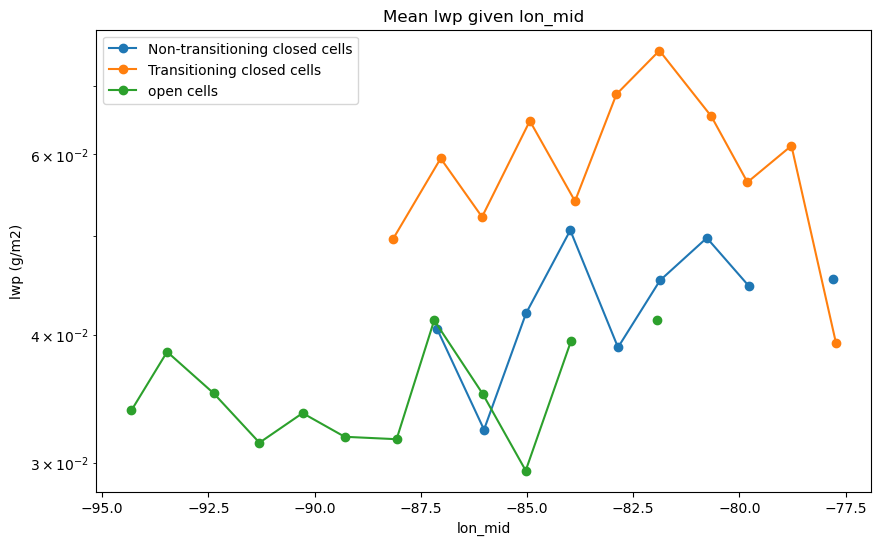

In [22]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for tmp, label in [(bt_non_trans_c, 'Non-transitioning closed cells'), (bt_co_transitioning_c, 'Transitioning closed cells'), (bt_co_back_from_o.where(bt_co_back_from_o.transition_flag == True, drop=True), 'open cells')]:
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    lwp_given_lon = tmp[['lon_mid','lwp']].groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).mean()
    lwp_given_lon['size'] = tmp.groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).size()
    lwp_given_lon['lwp'] = lwp_given_lon['lwp'].where(lwp_given_lon['size'] >= 20, np.nan)
    lwp_given_lon.plot(y='lwp', x='lon_mid', logy=True, logx=False,marker='o', ax=axs, label=label)
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('lon_mid')
plt.ylabel('lwp (g/m2)')
plt.title('Mean lwp given lon_mid')

Text(0, 0.5, 'RWP (g/m²)')

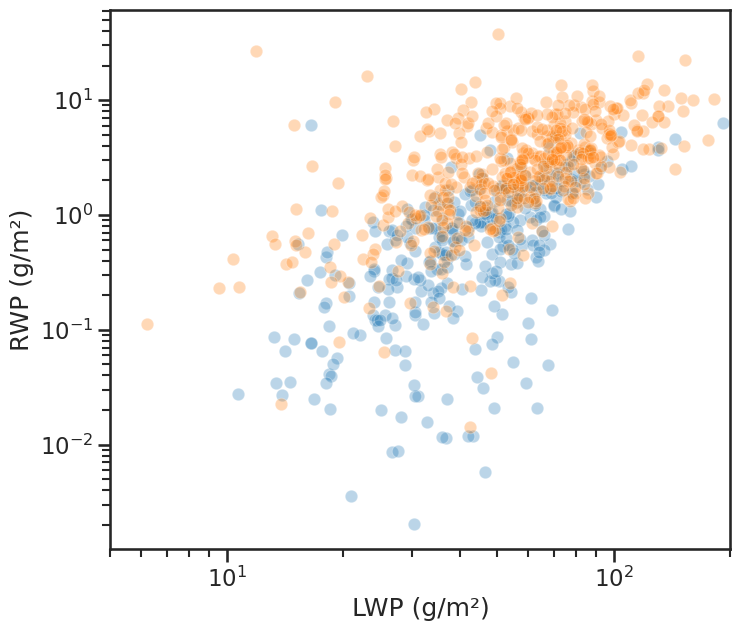

In [54]:
plt.figure(figsize=(8, 7))
sns.scatterplot(x=bt_non_trans_c['lwp']*1e3, y=bt_non_trans_c['rwp']*1e3, alpha=0.3)
sns.scatterplot(x=bt_co_transitioning_c['lwp']*1e3, y=bt_co_transitioning_c['rwp']*1e3, alpha=0.3)
#sns.scatterplot(x=bt_co_back_from_o['lwp']*1e3, y=bt_co_back_from_o['rwp']*1e3, alpha=0.3)
plt.xscale('log')
plt.yscale('log')
plt.xlim(5, 2e2)
plt.xlabel('LWP (g/m²)')
plt.ylabel('RWP (g/m²)')

Text(0, 0.5, 'RWP (g/m²)')

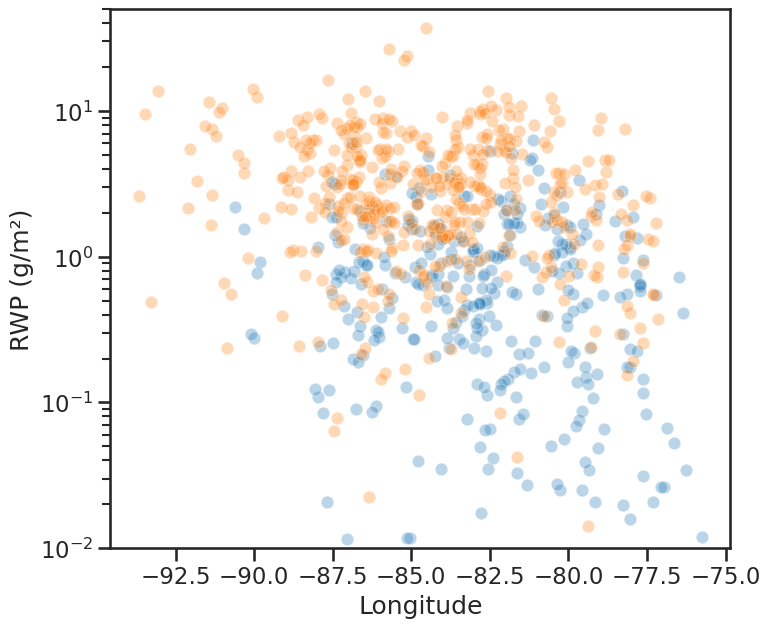

In [ ]:
plt.figure(figsize=(8, 7))
sns.scatterplot(x=bt_non_trans_c['lon_mid'], y=bt_non_trans_c['rwp']*1e3, alpha=0.3)
sns.scatterplot(x=bt_co_transitioning_c['lon_mid'], y=bt_co_transitioning_c['rwp']*1e3, alpha=0.3)
plt.yscale('log')
plt.ylim(1e-2, 5e1)
plt.xlabel('Longitude')
plt.ylabel('RWP (g/m²)')

<>:34: SyntaxWarning: invalid escape sequence '\D'
<>:35: SyntaxWarning: invalid escape sequence '\D'
<>:34: SyntaxWarning: invalid escape sequence '\D'
<>:35: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_1608663/1873646341.py:34: SyntaxWarning: invalid escape sequence '\D'
  plt.Line2D([0], [0], color=colors[1], lw=4, ls=line_styles[1], label='transition to open MCC ($\Delta$t >= {} h)'.format(np.abs(delta_t_threshold))),
/tmp/ipykernel_1608663/1873646341.py:35: SyntaxWarning: invalid escape sequence '\D'
  plt.Line2D([0], [0], color=colors[2], lw=4, ls=line_styles[2], label='transition to open MCC ($\Delta$t < {} h)'.format(np.abs(delta_t_threshold))),


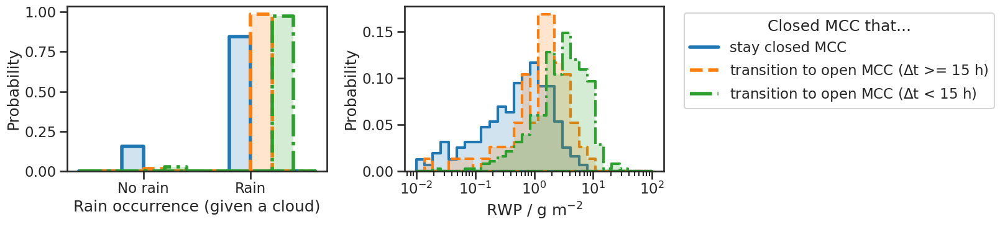

In [117]:
line_styles = ['-', '--', '-.']
colors = sns.color_palette('tab10')
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

delta_t_threshold = -15  # hours
bt_co_transitioning_c_far_from_trans = bt_co_transitioning_c.where(bt_co_transitioning_c.transition_time_diff <= delta_t_threshold, drop=True)
bt_co_transitioning_c_close_to_trans = bt_co_transitioning_c.where(bt_co_transitioning_c.transition_time_diff > delta_t_threshold, drop=True)

fig, ax = plt.subplots(1,2, figsize=(11, 4))
for j,dffil in enumerate([bt_non_trans_c, bt_co_transitioning_c_far_from_trans, bt_co_transitioning_c_close_to_trans]):
    sns.histplot(ax=ax[0], x=(dffil['rwp'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                 element='step', alpha=0.2, stat='probability', lw=4, color=colors[j], ls=line_styles[j])
    sns.histplot(
        ax=ax[1], x=dffil['rwp']*1e3, bins=np.logspace(-2,2,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])


ax[1].set_xscale('log')
ax[1].set_xlabel('RWP / g m$^{-2}$')

ax[0].set_xticks([0.1,1.1])
ax[0].set_xticklabels(['No rain', 'Rain'])
ax[0].set_xlabel('Rain occurrence (given a cloud)')
fig.tight_layout()

legend_handles = [
    plt.Line2D([0], [0], color=colors[0], lw=4, ls=line_styles[0], label='stay closed MCC'),
    plt.Line2D([0], [0], color=colors[1], lw=4, ls=line_styles[1], label='transition to open MCC ($\Delta$t >= {} h)'.format(np.abs(delta_t_threshold))),
    plt.Line2D([0], [0], color=colors[2], lw=4, ls=line_styles[2], label='transition to open MCC ($\Delta$t < {} h)'.format(np.abs(delta_t_threshold))),
]
ax[1].legend(title='Closed MCC that...', handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left')

In [118]:
rwp_thresh = 3e-3
n_trans_smaller_thresh = bt_co_transitioning_c.where(bt_co_transitioning_c.rwp < rwp_thresh, drop=True).rwp.count()
n_trans_greater_thresh = bt_co_transitioning_c.where(bt_co_transitioning_c.rwp >= rwp_thresh, drop=True).rwp.count()
n_non_trans_smaller_thresh = bt_non_trans_c.where(bt_non_trans_c.rwp < rwp_thresh, drop=True).rwp.count()
n_non_trans_greater_thresh = bt_non_trans_c.where(bt_non_trans_c.rwp >= rwp_thresh, drop=True).rwp.count()

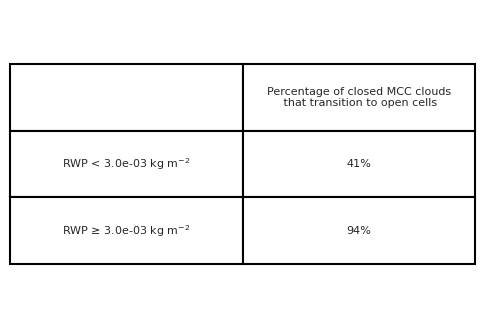

In [119]:
percent_of_transitioning_clouds_for_rwp_smaller_thresh = n_trans_smaller_thresh / (n_trans_smaller_thresh + n_non_trans_smaller_thresh)
percent_of_transitioning_clouds_for_rwp_greater_thresh = n_trans_greater_thresh / (n_trans_greater_thresh + n_non_trans_greater_thresh)

# plot a table
plt.figure(figsize=(6, 4))
table_data = [
    ['RWP < {:.1e} kg m$^{{-2}}$'.format(rwp_thresh), f'{percent_of_transitioning_clouds_for_rwp_smaller_thresh:.0%}'],
    ['RWP ≥ {:.1e} kg m$^{{-2}}$'.format(rwp_thresh), f'{percent_of_transitioning_clouds_for_rwp_greater_thresh:.0%}']
]
columns = ['', 'Percentage of closed MCC clouds\n that transition to open cells']
table = plt.table(cellText=table_data, colLabels=columns, cellLoc='center', loc='center', colWidths=[0.5, 0.5])
plt.axis('off')
table.set_fontsize(12)
table.scale(1, 4)  # Scale width=1, height=2

/tmp/ipykernel_3985704/80815408.py:8: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

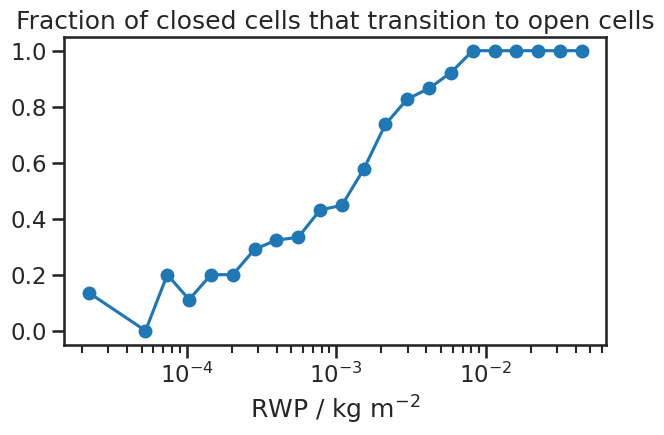

In [43]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-4.5, -1, 25)
bins[0] = 0
rwp_bin_centers = (bins[:-1] + bins[1:]) / 2
rwp_hist_trans = np.histogram(bt_co_transitioning_c.rwp, bins=bins)[0]
rwp_hist_non_trans = np.histogram(bt_non_trans_c.rwp, bins=bins)[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rwp_bin_centers, rwp_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('RWP / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

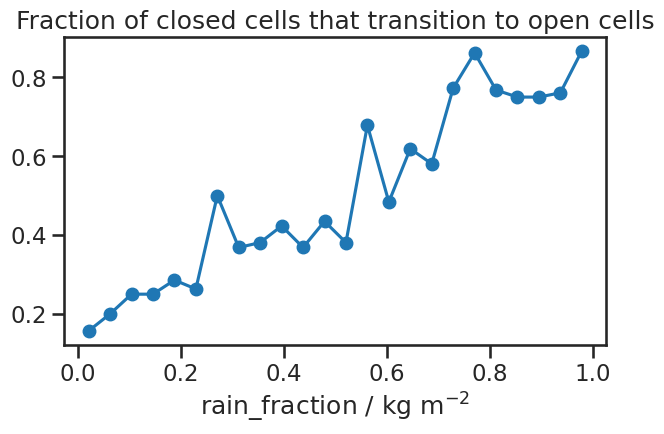

In [74]:
# plot probability that cloud will transition vs rain_fraction
bins = np.linspace(0, 1, 25)
bins[0] = 0
rain_fraction_bin_centers = (bins[:-1] + bins[1:]) / 2
rain_fraction_hist_trans = np.histogram(bt_co_transitioning_c.rain_fraction, bins=bins)[0]
rain_fraction_hist_non_trans = np.histogram(bt_non_trans_c.rain_fraction, bins=bins)[0]
rain_fraction_hist_total = rain_fraction_hist_trans + rain_fraction_hist_non_trans
rain_fraction_transition_prob = rain_fraction_hist_trans / rain_fraction_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rain_fraction_bin_centers, rain_fraction_transition_prob, marker='o')
plt.xlabel('rain_fraction / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_3985704/2513230141.py:12: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

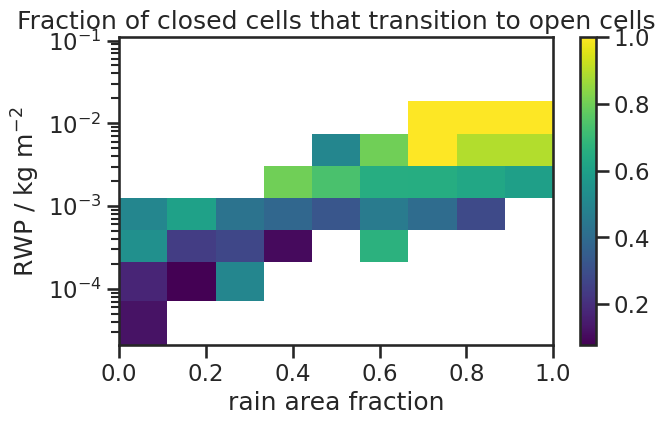

In [70]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 10)
bins_y[0] = 0
bins_x = np.linspace(0, 1, 10)

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_fraction_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rain_fraction, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rain_fraction, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 3, np.nan, rwp_transition_prob) 
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rain_fraction_bin'], coords={'rwp_bin': rwp_bin_centers, 'rain_fraction_bin': rain_fraction_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('rain area fraction')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_3985704/3852118749.py:13: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

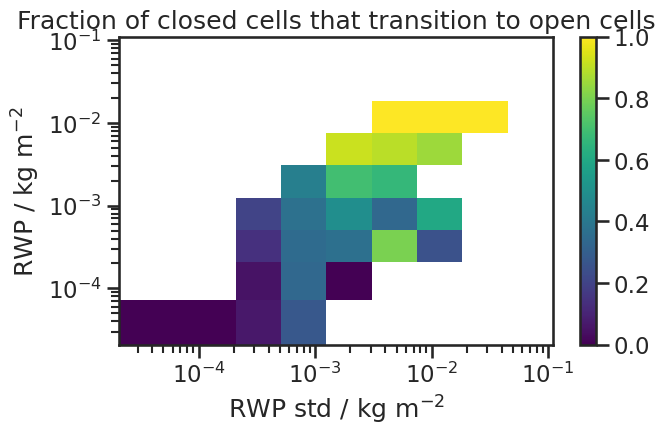

In [71]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 10)
bins_y[0] = 0
bins_x = np.logspace(-4.5, -1, 10)
bins_x[0] = 0

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rwp_std_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rwp_std, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rwp_std, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 3, np.nan, rwp_transition_prob) 
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rwp_std_bin'], coords={'rwp_bin': rwp_bin_centers, 'rwp_std_bin': rwp_std_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log', xscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('RWP std / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_3985704/756791808.py:13: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

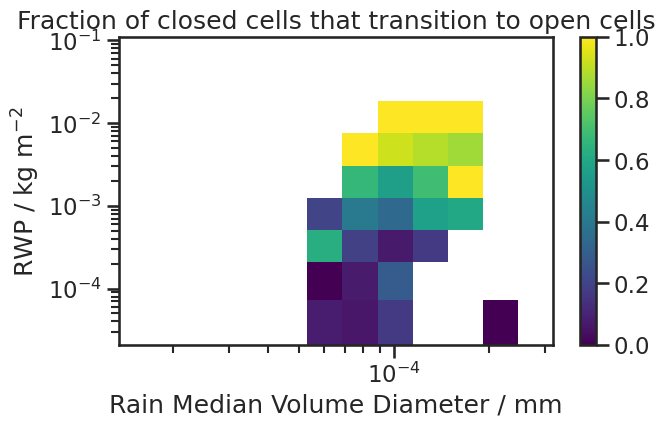

In [67]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 10)
bins_y[0] = 0
bins_x = np.logspace(-4.5, -3.5, 10)
bins_x[0] = 0

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_median_volume_diameter_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 3, np.nan, rwp_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rain_median_volume_diameter_bin'], coords={'rwp_bin': rwp_bin_centers, 'rain_median_volume_diameter_bin': rain_median_volume_diameter_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log', xscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('Rain Median Volume Diameter / mm')
plt.title('Fraction of closed cells that transition to open cells')

#### compare CO clouds with neighboring non-trans clouds

In [23]:
tmp = bt_co_forward_from_c.sel(timestep = slice(0,30)).goes_cats.fillna(-1)
enough_datapoints_along_track = (tmp.isin([0,1,2,3,4,5]).sum(dim='timestep')) >= 6
always_closed_cell = tmp.isin([-1,1]).all(dim='timestep')

# new flag: 1 = transition to open cell, 0 = stay closed cell, -1 = something else (not enough data or transition to other category)
bt_co_forward_from_c['flag_closed_cell_transition'] = xr.where(bt_co_forward_from_c.transition_flag, 1, xr.where(~bt_co_forward_from_c.transition_flag & enough_datapoints_along_track & always_closed_cell, 0, -1))

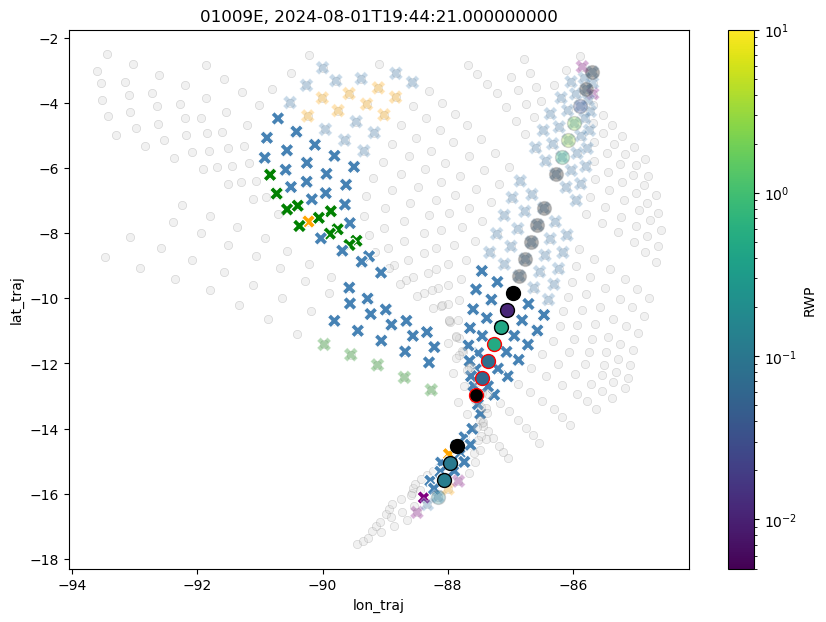

In [24]:
for orbit, group in bt_co_forward_from_c.groupby('orbit'):
    non_trans_closed_cells = (group.flag_closed_cell_transition == 0).sum()
    co_trans_closed_cells = (group.flag_closed_cell_transition == 1).sum()
    if non_trans_closed_cells > 0 and co_trans_closed_cells > 0:
        
        # Create colormap normalization once outside the loop
        norm = LogNorm(vmin=5e-3, vmax=1e1)
        cmap = plt.cm.viridis
        plt.figure(figsize=(10, 7))
        
        for i in range(len(group.time_startpoint)):
            tmp = group.isel(time_startpoint=i)
            if tmp.flag_closed_cell_transition == 0:
                # persistent closed cell
                alpha = 1.0
                marker_edge_color = 'black'
            elif tmp.flag_closed_cell_transition == 1:
                # transition from closed to open cell
                alpha = 1.0
                marker_edge_color = 'red'
            else:
                alpha = 0.3
                marker_edge_color = 'Grey'

            sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', color='lightgrey', alpha=0.3, edgecolor='Grey', legend=False)
            
            # Get the RWP value and map it to a color
            rwp_value = tmp.sel(timestep=0).rwp.values*1e3  # convert to g/m²
            color = cmap(norm(rwp_value))
            
            plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 
                    color=color, marker='o', markersize=10, markeredgecolor=marker_edge_color, alpha=alpha)
            sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
        
        # Add colorbar to show the RWP scale
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        plt.colorbar(sm, label='RWP', ax=plt.gca())
        
        plt.title(f'{orbit}, {group.time_startpoint.values[0]}')
        plt.show()
        break

In [25]:
group

<xarray.Dataset> Size: 126kB
Dimensions:                               (time_startpoint: 23, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 184B ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 184B '0100...
Data variables: (12/95)
    lat_traj                              (time_startpoint, timestep) float64 8kB ...
    lon_traj                              (time_startpoint, timestep) float64 8kB ...
    plev_traj                             (time_startpoint, timestep) float64 8kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 8kB ...
    goes_cats                             (time_startpoint, timestep) float64 8kB ...
    goes_cert                             (time_startpoint, timestep) float64 8kB ...
    ...                                    ...
    rwp_perc75                            (time_startpoint) float64 184B 0.0 ...
    rain_median_volume_diameter_std       (time_startpoint) float64 184B nan ...
    rain_median_volume_diameter_median    (time_startpoint) float64 184B nan ...
    rain_median_volume_diameter_perc25    (time_startpoint) float64 184B nan ...
    rain_median_volume_diameter_perc75    (time_startpoint) float64 184B nan ...
    flag_closed_cell_transition           (time_startpoint) int64 184B -1 ... -1

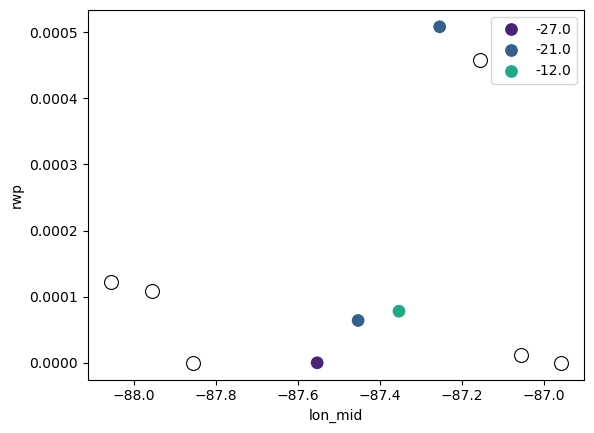

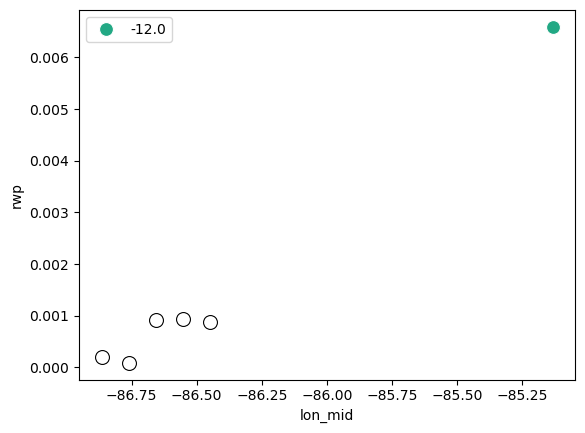

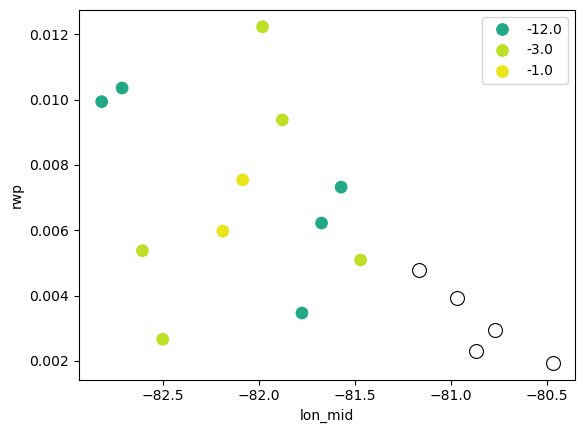

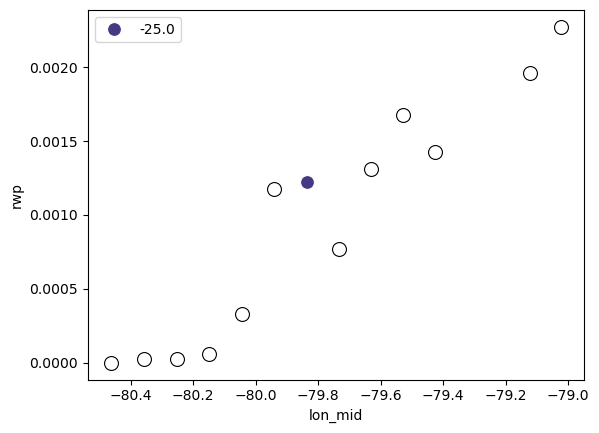

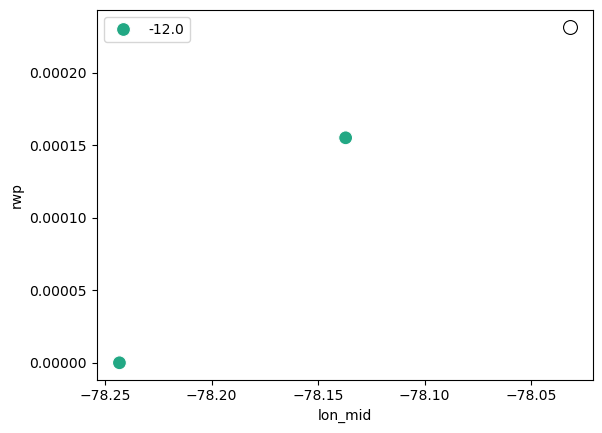

...

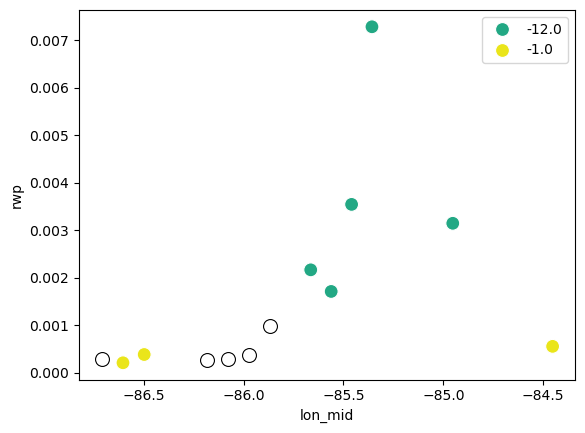

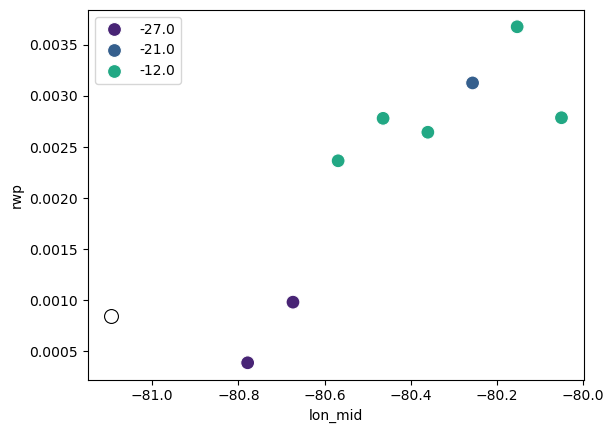

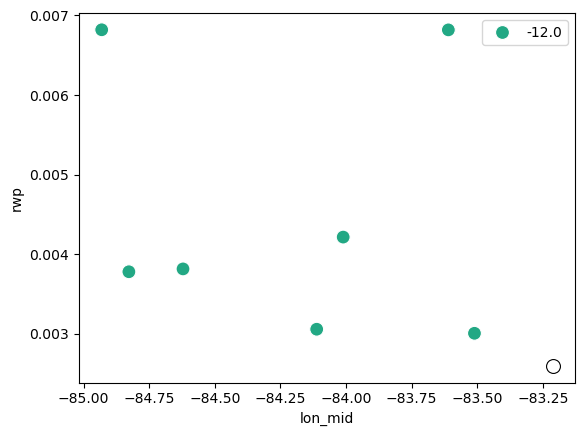

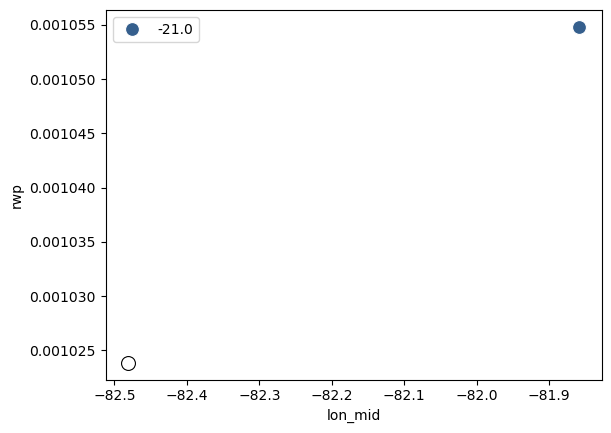

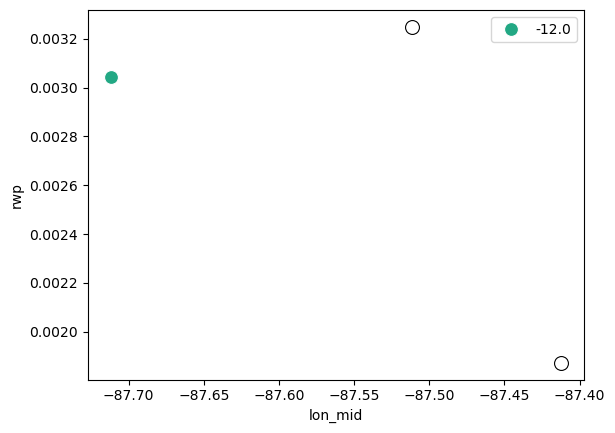

In [25]:
for orbit, group in bt_co_forward_from_c.groupby('orbit'):
    non_trans_closed_cells = (group.flag_closed_cell_transition == 0).sum()
    co_trans_closed_cells = (group.flag_closed_cell_transition == 1).sum()
    if non_trans_closed_cells > 0 and co_trans_closed_cells > 0:
        sns.scatterplot(data=group.where(group.flag_closed_cell_transition == 1, drop=True), x='lon_mid', y='rwp', hue='transition_time_diff', 
                        palette='viridis', hue_norm=(-30,0), legend=True, marker='o', s=100)
        sns.scatterplot(data=group.where(group.flag_closed_cell_transition == 0, drop=True), x='lon_mid', y='rwp',
                        color='white', legend=True, marker='o', s=100, edgecolor='black')
        plt.show()

#### examples of transitioning clouds

In [17]:
def plot_ACMCAP_MCOP_for_orbit(orbit, lat_min, lat_max):
    sys.path.append('./../../../ectools/')
    from ectools import ecio
    sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_msi/')
    import access_ec_on_maap as maap

    dfscene = bt_co_concat.where((bt_co_concat.orbit == orbit) & (bt_co_concat.lat_mid >= lat_min) & (bt_co_concat.lat_mid <= lat_max), drop=True)
    time_startpoint = dfscene.time_startpoint.values[0]
    year = pd.to_datetime(time_startpoint).year
    month = pd.to_datetime(time_startpoint).month
    day = pd.to_datetime(time_startpoint).day
    region = 'SEP'
    transition_params=dfscene[['transition_time_diff','along_track_mid','cats','goes_cats','scene_id']].sel(timestep=0).groupby('scene_id').mean()

    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/{year}/{month:02d}/{day:02d}/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
    ACMCAP.encoding = encoding.copy()
    ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
    ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})

    # load MCOP
    MCOP_list = maap.get_mcop_via_maap(
            region=region, 
            frame=orbit[-1],
            orbitNumber=orbit[:-1],
            mcop_variables=['time', 'latitude', 'longitude', 'cloud_optical_thickness', 'cloud_water_path','cloud_effective_radius'], 
            max_items=1)
        
    MCOP, _ = MCOP_list[0]

    MCOP = MCOP.assign_coords(
        {
        'along_track': (
            ["along_track"],
            MCOP['along_track'].data,
            MCOP['along_track'].attrs
            ),
        'across_track': (
            ['across_track'],
            MCOP['across_track'].data,
            MCOP['across_track'].attrs
            )
        })
    along_track_min = np.abs(MCOP.sel(across_track=284).latitude - lat_min).argmin()
    along_track_max = np.abs(MCOP.sel(across_track=284).latitude - lat_max).argmin()
    MCOP2 = MCOP.sel(along_track=slice(MCOP.along_track[along_track_max], MCOP.along_track[along_track_min]))
    MCOP2 = MCOP2.sel(across_track=slice(360 - 256, 360))

    # plot
    sns.set_context('talk')
    length_along_track = len(ACMCAP.along_track)
    figsize = (length_along_track/112*7, 9)
    fig, axs = plt.subplots(2,1, figsize=figsize, gridspec_kw={'height_ratios': [1, 3]})
    ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='Blues', add_colorbar=False)
    ACMCAP.liquid_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-6, vmax=1e-3, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'LWC (kg m$^{-3}$)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    title = f'{orbit}, lat:{np.round(lat_min, 2)}-{np.round(lat_max, 2)}'
    axs[0].set_title(title)
    ax = axs[1]
    MCOP2.cloud_water_path.T.plot(ax=ax, cmap='viridis', vmin=1e-2, vmax=1e0, norm=LogNorm(), add_colorbar=True)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP liquid water path')
    for i,t in enumerate(transition_params["transition_time_diff"].values):
        ax.annotate(f'{t:.2f}', xy=(transition_params["along_track_mid"].values[i], 290), xycoords='data', fontsize=12, color='red')
    fig.tight_layout()
    plt.show()

    sns.set_context('talk')
    fig, axs = plt.subplots(2,1, figsize=figsize, gridspec_kw={'height_ratios': [1, 3]})
    ACMCAP.liquid_effective_radius.T.plot(ax=axs[0], ylim=(0,3000), vmin=5e-6, vmax=2e-5, cmap='turbo', cbar_kwargs={'label': 'ER (m)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    axs[0].set_title(title)
    ax = axs[1]
    MCOP2.cloud_effective_radius.T.plot(ax=ax, cmap='viridis', vmin=5e-6, vmax=2e-5, add_colorbar=True)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP effective radius')
    for i,t in enumerate(transition_params["transition_time_diff"].values):
        ax.annotate(f'{t:.2f}', xy=(transition_params["along_track_mid"].values[i], 290), xycoords='data', fontsize=12, color='red')
        ax.annotate(f'{transition_params["cats"].values[i]}', xy=(transition_params["along_track_mid"].values[i], 275), xycoords='data', fontsize=12, color='black')
        ax.annotate(f'{transition_params["goes_cats"].values[i]}', xy=(transition_params["along_track_mid"].values[i], 265), xycoords='data', fontsize=12, color='blue')
    fig.tight_layout()
    plt.show()

    sns.set_context('talk')
    figsize = (length_along_track/112*7, 8)
    fig, axs = plt.subplots(3,1, figsize=figsize, gridspec_kw={'height_ratios': [1, 1, 1]})
    ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'RWC (kg m$^{-3}$)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    axs[0].set_title(title)
    ax = axs[1]
    ACMCAP.CPR_doppler_velocity.T.plot(ax=ax, ylim=(0,3000), vmin=-2, vmax=2, cmap='RdBu', cbar_kwargs={'label': 'Doppler Velocity (m s$^{-1}$)'})
    ax = axs[2]
    ACMCAP.CPR_reflectivity_factor.T.plot(ax=ax, ylim=(0,3000), vmin=-40, vmax=0, cmap='turbo', cbar_kwargs={'label': 'Reflectivity Factor (dBZ)'})
    fig.tight_layout()
    plt.show()

In [50]:
ds_at_transition = bt_co_concat.where(np.abs(bt_co_concat.transition_time_diff) <= 1, drop=True)

# look for low LWP clouds at transition - what is going on here?
ds_at_transition = ds_at_transition.where((ds_at_transition.lwp > 3e-2) & (ds_at_transition.cats == 1), drop=True)
np.unique(ds_at_transition.orbit.values)

array(['01351E', '01460E', '05630E', '05708E', '05848E', '06019E',
       '06439E', '06517E', '06766E', '07046E', '07373E'], dtype=object)

In [18]:
ds_before_transition = bt_co_concat.where((bt_co_concat.transition_time_diff <= -20) & (bt_co_concat.transition_time_diff >= -24), drop=True)
np.unique(ds_before_transition.orbit.values)

array(['01009E', '01071E', '01211E', '01242E', '01351E', '01382E',
       '01553E', '01631E', '01709E', '01740E', '01833E', '01942E',
       '02160E', '02238E', '02409E', '02471E', '06268E', '06408E',
       '06470E', '06517E', '06766E', '06828E', '07077E', '07108E',
       '07155E', '07279E', '07326E', '07466E', '07637E', '07746E'],
      dtype=object)

Selecting frame from 9 to 4883
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/01/ECA_EXBA_MSI_COP_2A_20240801T193740Z_20250904T094044Z_01009E/ECA_EXBA_MSI_COP_2A_20240801T193740Z_20250904T094044Z_01009E/ECA_EXBA_MSI_COP_2A_20240801T193740Z_20250904T094044Z_01009E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/01/ECA_EXBA_MSI_COP_2A_20240801T193740Z_20250904T094044Z_01009E/ECA_EXBA_MSI_COP_2A_20240801T193740Z_20250904T094044Z_01009E/ECA_EXBA_MSI_COP_2A_20240801T193740Z_20250904T094044Z_01009E.h5
Orbit: 01009E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/01/ECA_EXBA_MSI_COP_2A_20240801T193740Z_20250904T094044Z_01009E/ECA_EXBA_MSI_COP_2A_20240801T193740Z_20250904T094044Z_010

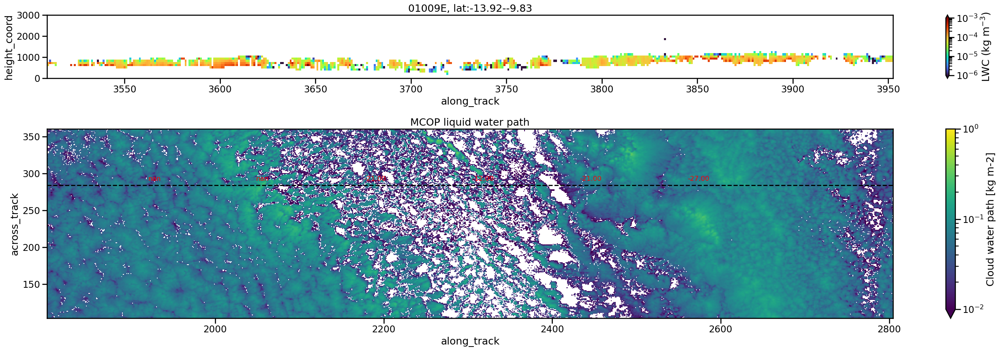

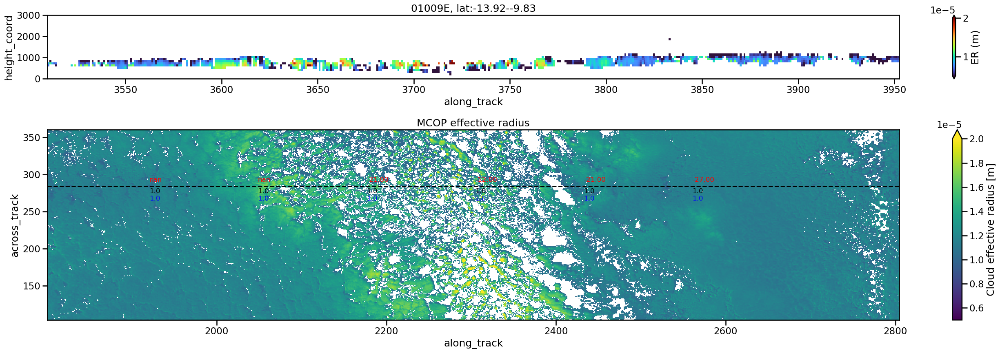

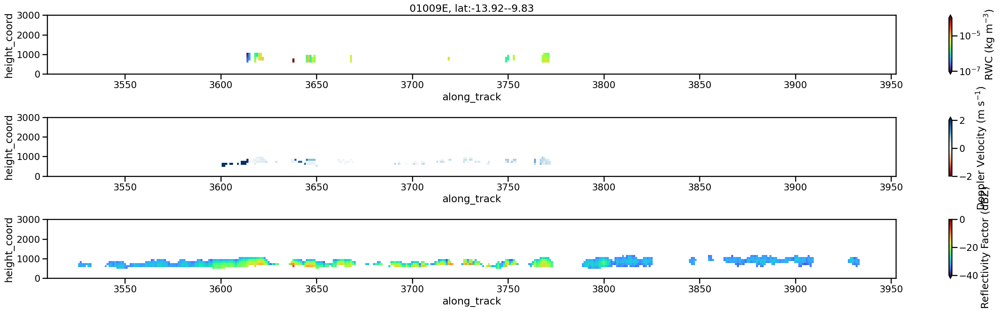

Selecting frame from 7 to 4879
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/05/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/05/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E.h5
Orbit: 01071E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/05/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_010

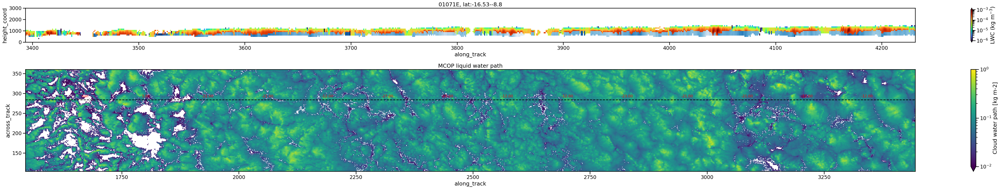

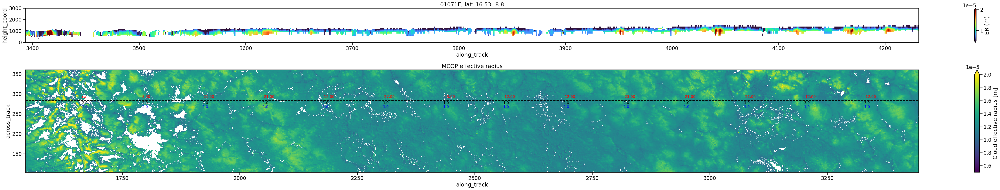

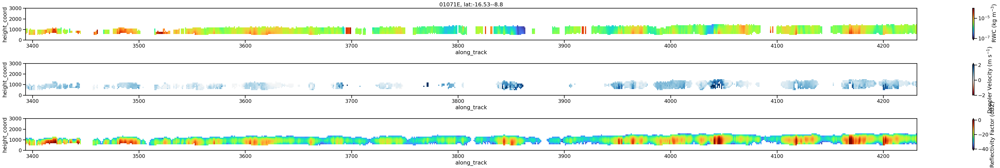

Selecting frame from 8 to 4876
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/14/ECA_EXBA_MSI_COP_2A_20240814T192507Z_20250904T092704Z_01211E/ECA_EXBA_MSI_COP_2A_20240814T192507Z_20250904T092704Z_01211E/ECA_EXBA_MSI_COP_2A_20240814T192507Z_20250904T092704Z_01211E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/14/ECA_EXBA_MSI_COP_2A_20240814T192507Z_20250904T092704Z_01211E/ECA_EXBA_MSI_COP_2A_20240814T192507Z_20250904T092704Z_01211E/ECA_EXBA_MSI_COP_2A_20240814T192507Z_20250904T092704Z_01211E.h5
Orbit: 01211E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/14/ECA_EXBA_MSI_COP_2A_20240814T192507Z_20250904T092704Z_01211E/ECA_EXBA_MSI_COP_2A_20240814T192507Z_20250904T092704Z_012

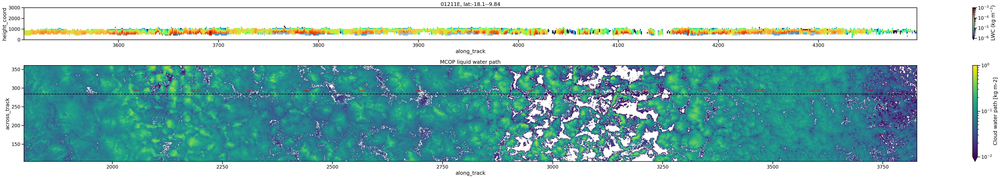

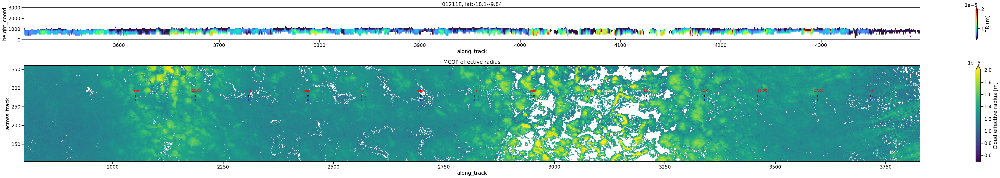

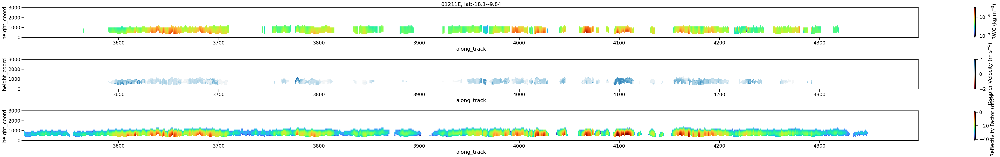

Selecting frame from 6 to 4874
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/16/ECA_EXBA_MSI_COP_2A_20240816T191513Z_20250904T090349Z_01242E/ECA_EXBA_MSI_COP_2A_20240816T191513Z_20250904T090349Z_01242E/ECA_EXBA_MSI_COP_2A_20240816T191513Z_20250904T090349Z_01242E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/16/ECA_EXBA_MSI_COP_2A_20240816T191513Z_20250904T090349Z_01242E/ECA_EXBA_MSI_COP_2A_20240816T191513Z_20250904T090349Z_01242E/ECA_EXBA_MSI_COP_2A_20240816T191513Z_20250904T090349Z_01242E.h5
Orbit: 01242E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/16/ECA_EXBA_MSI_COP_2A_20240816T191513Z_20250904T090349Z_01242E/ECA_EXBA_MSI_COP_2A_20240816T191513Z_20250904T090349Z_012

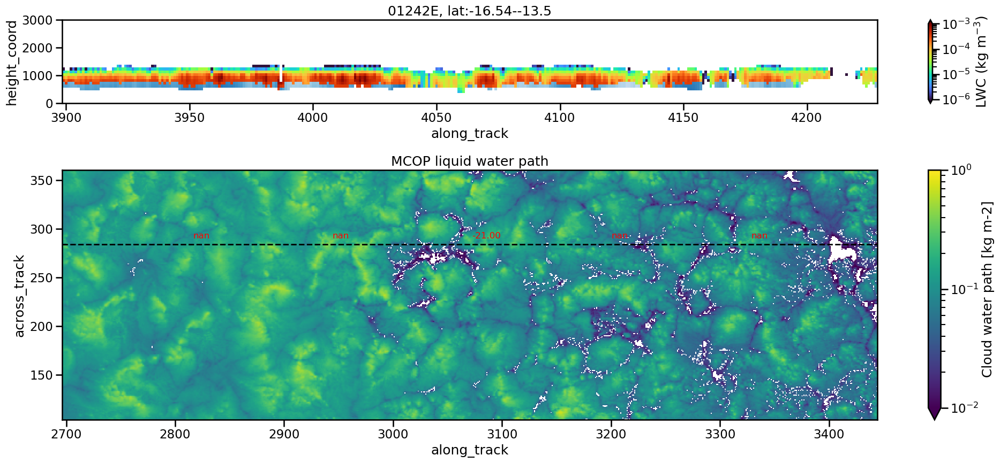

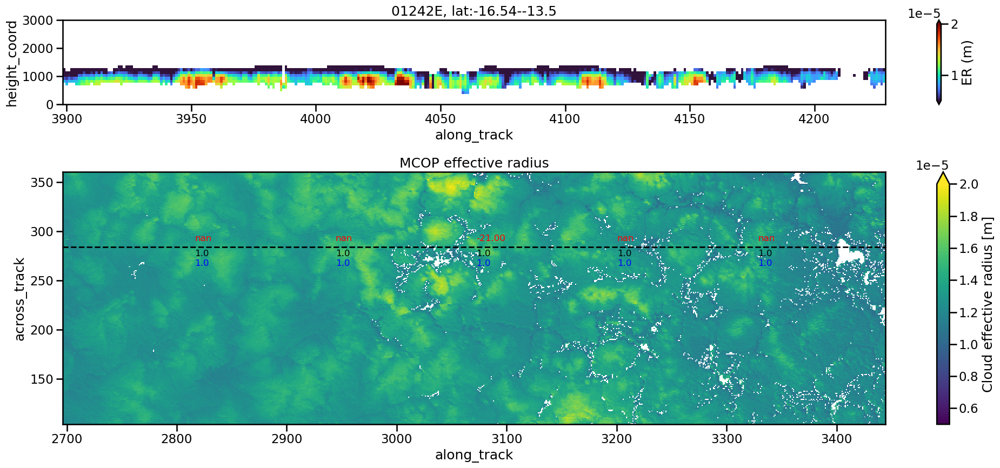

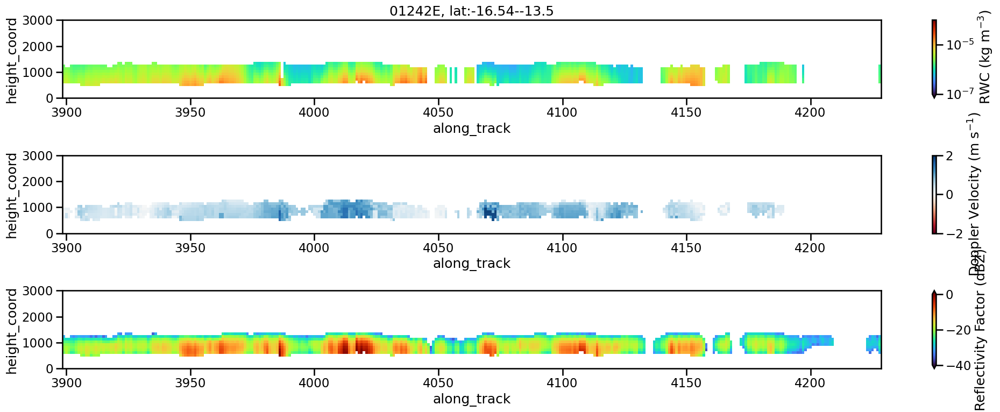

Selecting frame from 8 to 4873
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E.h5
Orbit: 01351E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_013

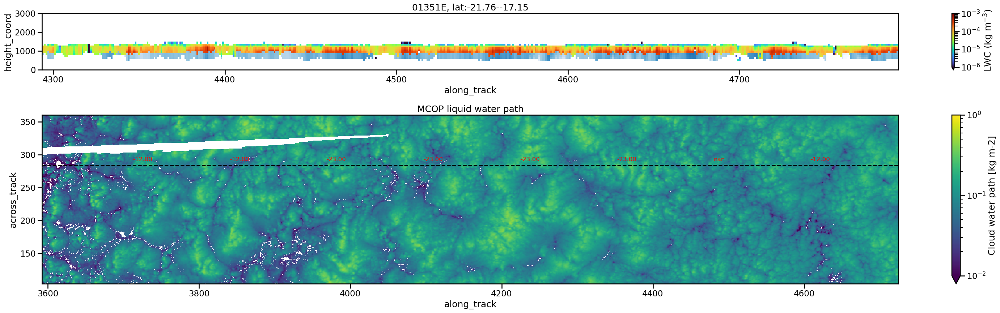

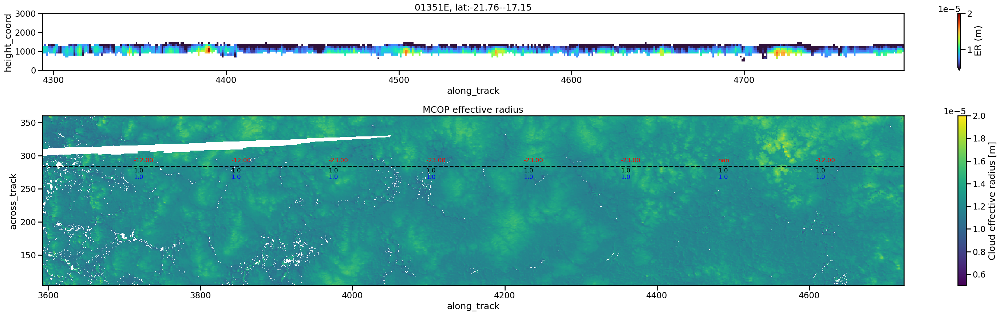

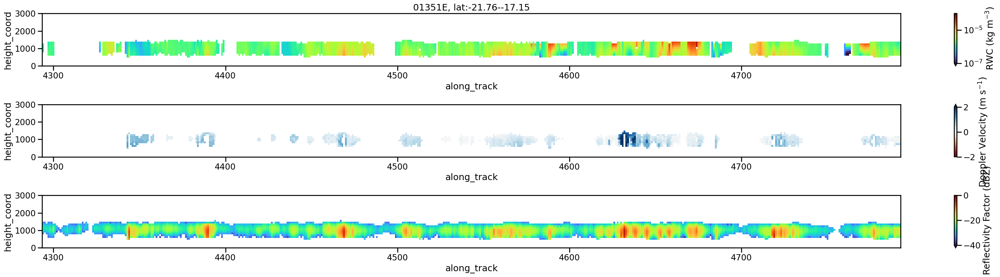

In [19]:
for i,orbit in enumerate(np.unique(ds_before_transition.orbit.values)[:5]):
    ds_before_transition_orbit = ds_before_transition.where(ds_before_transition.orbit == orbit, drop=True)
    lat_min = ds_before_transition_orbit.lat_min.min().values
    lat_max = ds_before_transition_orbit.lat_max.max().values
    plot_ACMCAP_MCOP_for_orbit(orbit, lat_min - 1, lat_max + 1)
    if i >= 5:
        break

Selecting frame from 9 to 4881
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/06/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/06/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E.h5
Orbit: 01087E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/06/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_01087E/ECA_EXBA_MSI_COP_2A_20240806T200218Z_20250904T091334Z_010

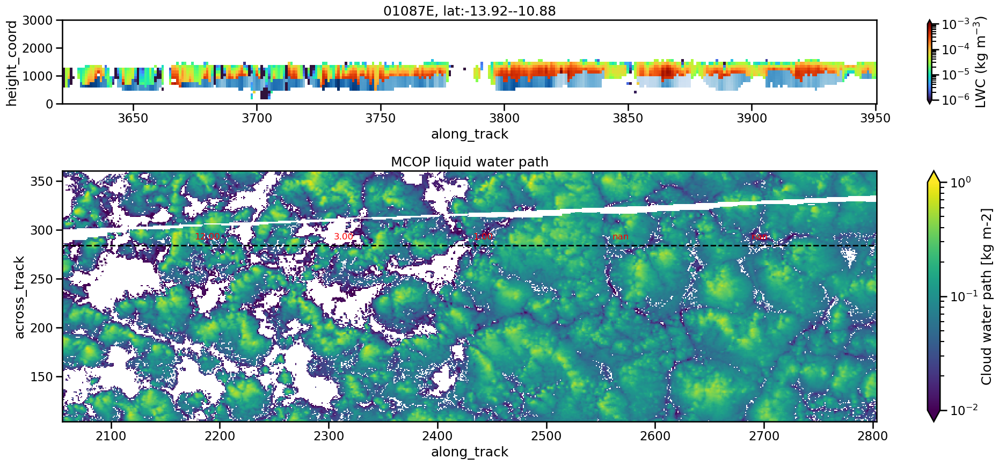

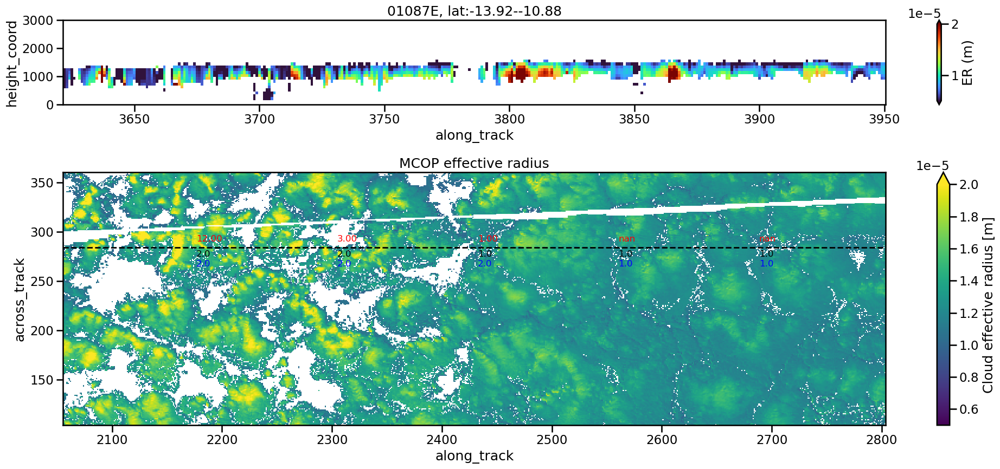

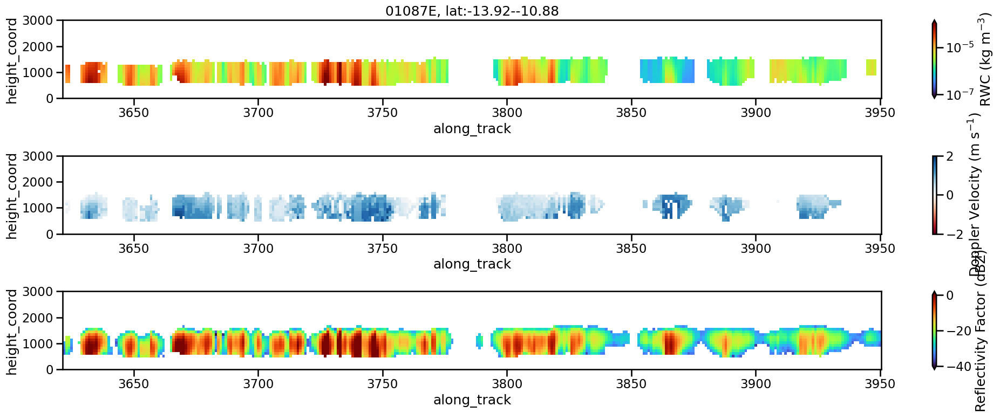

Selecting frame from 9 to 4880
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/07/ECA_EXBA_MSI_COP_2A_20240807T191132Z_20250904T103831Z_01102E/ECA_EXBA_MSI_COP_2A_20240807T191132Z_20250904T103831Z_01102E/ECA_EXBA_MSI_COP_2A_20240807T191132Z_20250904T103831Z_01102E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/07/ECA_EXBA_MSI_COP_2A_20240807T191132Z_20250904T103831Z_01102E/ECA_EXBA_MSI_COP_2A_20240807T191132Z_20250904T103831Z_01102E/ECA_EXBA_MSI_COP_2A_20240807T191132Z_20250904T103831Z_01102E.h5
Orbit: 01102E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/07/ECA_EXBA_MSI_COP_2A_20240807T191132Z_20250904T103831Z_01102E/ECA_EXBA_MSI_COP_2A_20240807T191132Z_20250904T103831Z_011

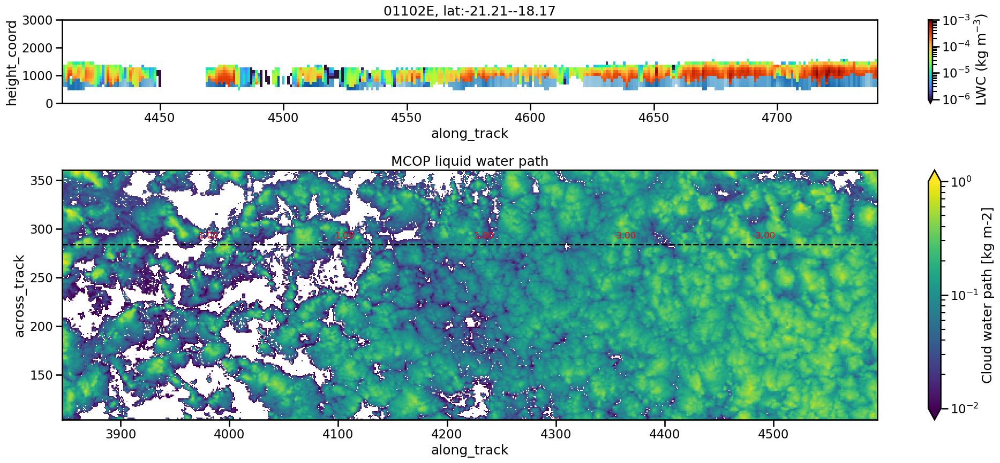

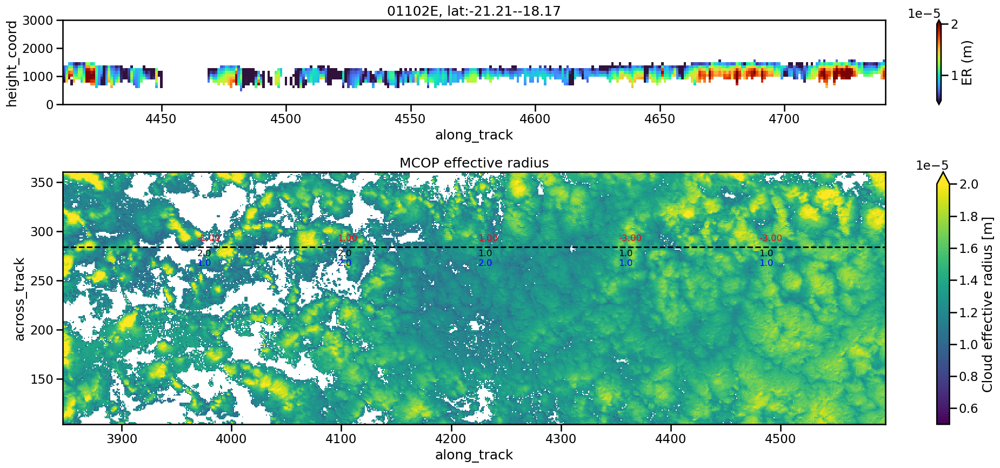

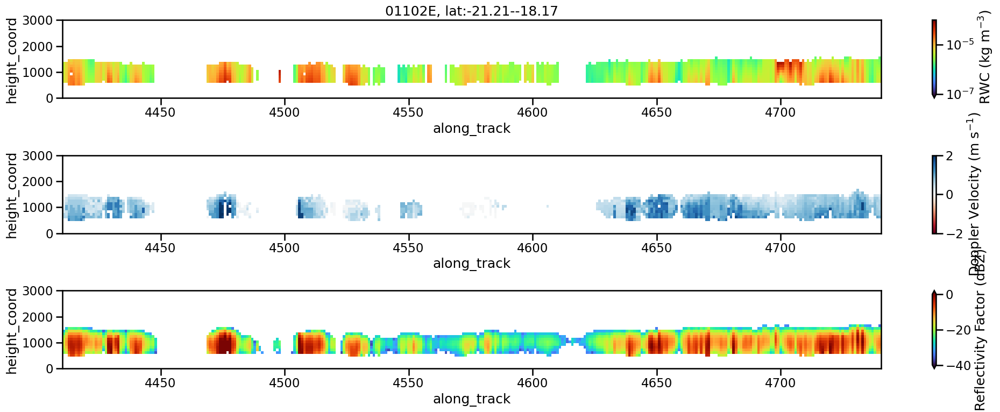

Selecting frame from 8 to 4875
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/21/ECA_EXBA_MSI_COP_2A_20240821T193547Z_20250904T103821Z_01320E/ECA_EXBA_MSI_COP_2A_20240821T193547Z_20250904T103821Z_01320E/ECA_EXBA_MSI_COP_2A_20240821T193547Z_20250904T103821Z_01320E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/21/ECA_EXBA_MSI_COP_2A_20240821T193547Z_20250904T103821Z_01320E/ECA_EXBA_MSI_COP_2A_20240821T193547Z_20250904T103821Z_01320E/ECA_EXBA_MSI_COP_2A_20240821T193547Z_20250904T103821Z_01320E.h5
Orbit: 01320E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/21/ECA_EXBA_MSI_COP_2A_20240821T193547Z_20250904T103821Z_01320E/ECA_EXBA_MSI_COP_2A_20240821T193547Z_20250904T103821Z_013

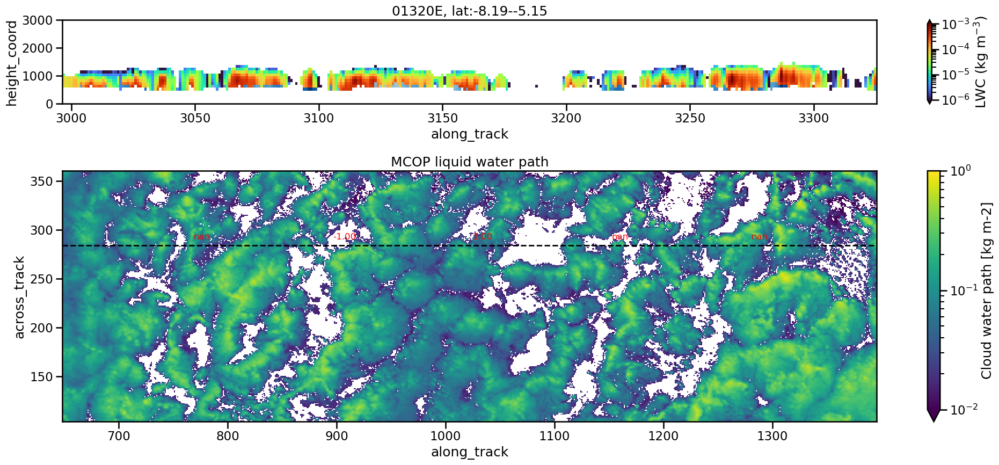

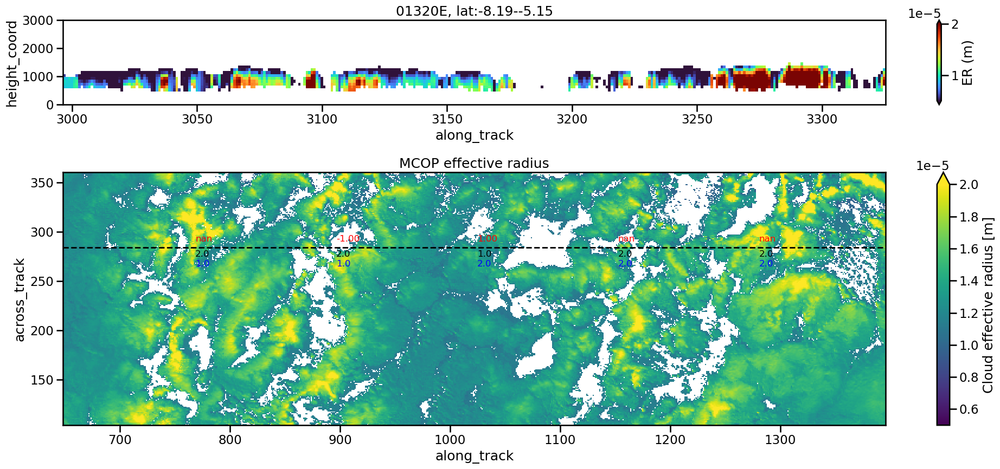

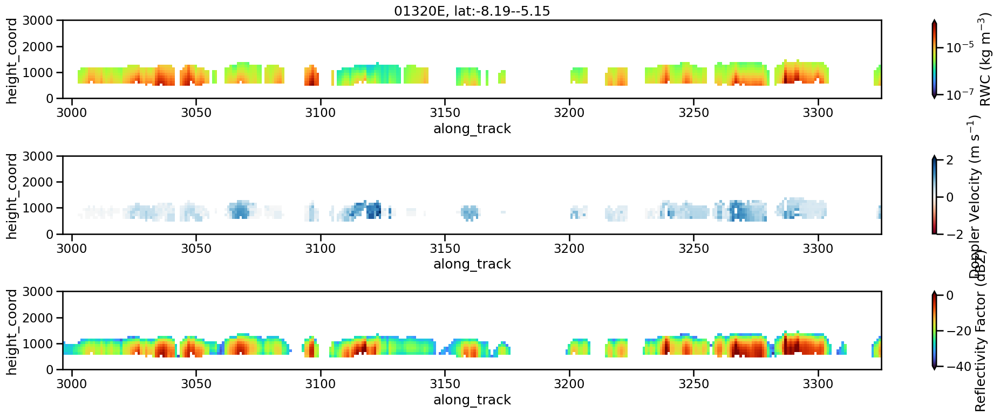

Selecting frame from 8 to 4873
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E.h5
Orbit: 01351E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_013

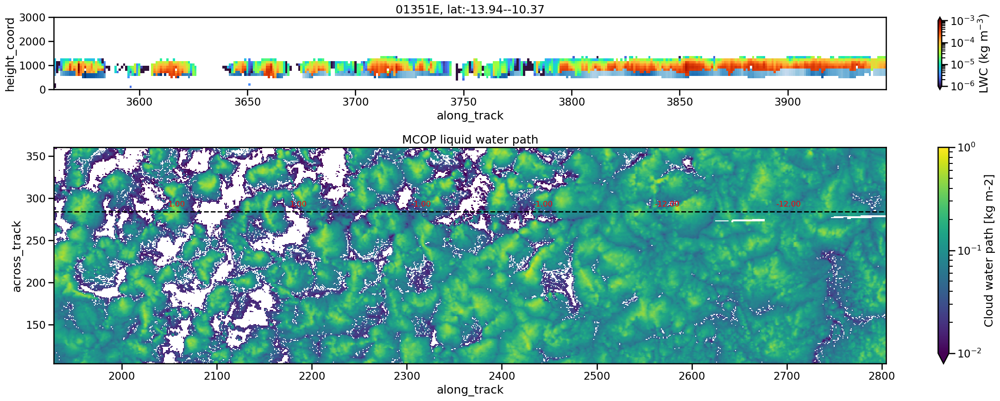

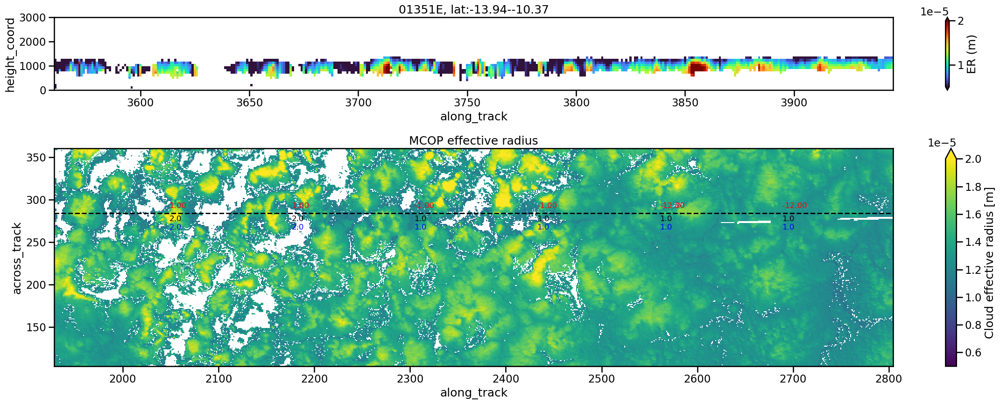

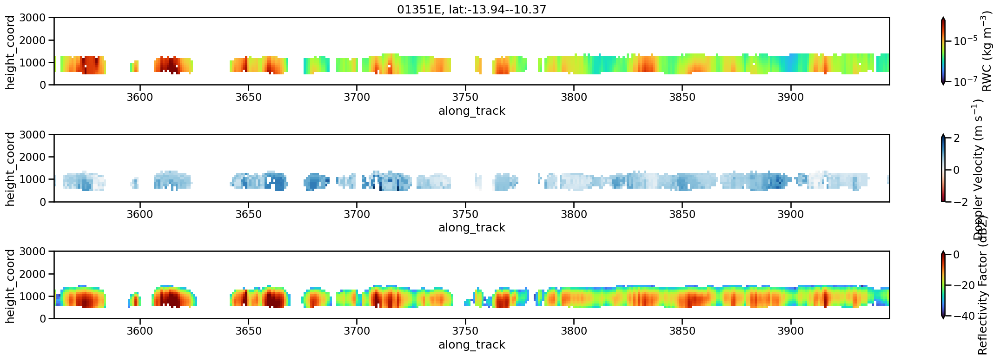

Selecting frame from 9 to 4874
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/24/ECA_EXBA_MSI_COP_2A_20240824T200602Z_20250904T095255Z_01367E/ECA_EXBA_MSI_COP_2A_20240824T200602Z_20250904T095255Z_01367E/ECA_EXBA_MSI_COP_2A_20240824T200602Z_20250904T095255Z_01367E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/24/ECA_EXBA_MSI_COP_2A_20240824T200602Z_20250904T095255Z_01367E/ECA_EXBA_MSI_COP_2A_20240824T200602Z_20250904T095255Z_01367E/ECA_EXBA_MSI_COP_2A_20240824T200602Z_20250904T095255Z_01367E.h5
Orbit: 01367E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/24/ECA_EXBA_MSI_COP_2A_20240824T200602Z_20250904T095255Z_01367E/ECA_EXBA_MSI_COP_2A_20240824T200602Z_20250904T095255Z_013

KeyboardInterrupt: 

In [ ]:
for i,orbit in enumerate(np.unique(ds_at_transition.orbit.values)[:5]):
    ds_at_transition_orbit = ds_at_transition.where(ds_at_transition.orbit == orbit, drop=True)
    lat_min = ds_at_transition_orbit.lat_min.min().values
    lat_max = ds_at_transition_orbit.lat_max.max().values
    plot_ACMCAP_MCOP_for_orbit(orbit, lat_min - 1, lat_max + 1)
    if i >= 5:
        break

#### ACMCAP frames for CO transitions

In [23]:
sys.path.append('./../../../ectools/')
from ectools import ecio
from ectools import ecplot as ecplt

In [ ]:
bt_co_c = bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True)
bt_co_o = bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True)

orbits_c = np.unique(bt_co_c.orbit_startpoint)
orbits_o = np.unique(bt_co_o.orbit_startpoint)
orbits = np.unique(np.concatenate((orbits_c, orbits_o)))
#orbit = orbits[0]
month = '08'

for orbit in orbits: # ['06766E']: '06704E'
    print(f'Plotting orbit {orbit}')

    bt_co_c_orbit = bt_co_c.where(bt_co_c.orbit_startpoint == orbit, drop=True)
    bt_co_o_orbit = bt_co_o.where(bt_co_o.orbit_startpoint == orbit, drop=True)

    # load ACMCAP
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/{month}/*/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    lat_range = (-22.5, -2.5)
    lon_range = (-95, -75)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_range[0]) & (ACMCAP.latitude < lat_range[1]) & (ACMCAP.longitude > lon_range[0]) & (ACMCAP.longitude < lon_range[1]), drop=True)
    ACMCAP.encoding = encoding.copy()

    # load MCOP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/{month}/*/*_{orbit}.h5')[0]
        MCOP = ecio.load_MCOP(filename)
        MCOP = MCOP.assign_coords(
            {
            'along_track': (
                ["along_track"],
                MCOP['along_track'].data,
                MCOP['along_track'].attrs
                ),
            'across_track': (
                ['across_track'],
                MCOP['across_track'].data,
                MCOP['across_track'].attrs
                )
            })
        MCOP2 = MCOP.where((MCOP.latitude > lat_range[0]) & (MCOP.latitude < lat_range[1]) & (MCOP.longitude > lon_range[0]) & (MCOP.longitude < lon_range[1]), drop=True)
        MCOP2 = MCOP2[['latitude','longitude','cloud_water_path','cloud_optical_thickness','cloud_effective_radius']]
        MCOP2['time'] = MCOP['time'].sel(along_track=MCOP2.along_track)
        MCOP2 = MCOP2.assign_coords(
            {
            'time': (
                ['along_track'],
                MCOP2.time.data,
                MCOP2.time.attrs
                )
            })
        MCOP2 = MCOP2.swap_dims({'along_track': 'time'})
    except:
        print(f'No MCOP data for {orbit}')
        MCOP2 = None

    # plot
    fig, axs = plt.subplots(3,1, figsize=(35,15), gridspec_kw={'height_ratios': [1, 1, 1]})

    # highlight scenes for which transitions were found
    for ax in axs[0:2]:
        for i in range(len(bt_co_c_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='yellow', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_c_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            ax.annotate(bt_co_c_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    for ax in axs[0:2]:
        for i in range(len(bt_co_o_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='deeppink', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_o_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            ax.annotate(bt_co_o_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    ax = axs[0]
    ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=4000)

    ax = axs[1]
    ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", hmax=4000)

    if MCOP2 is not None:
        ax = axs[2]
        ax.sharex(axs[0])
        (np.log(MCOP2.cloud_water_path*1000)).T.plot(ax=ax, cmap='viridis', vmax=7, vmin=2.5, add_colorbar=False)
        ax.axhline(284, color='k', linestyle='--', lw=2)
        ax.set_title('MCOP liquid water path')
        # add cbar to the right
        cbar_ax = fig.add_axes([0.99, 0.09, 0.009, 0.18])  # [left, bottom, width, height]
        cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
        cbar.set_label('log(LWP) [g m$^{-2}$]')
        cbar.set_ticks([3,4,5,6])
    fig.tight_layout()
    plt.show()

<Axes: xlabel='lon_traj', ylabel='lat_traj'>

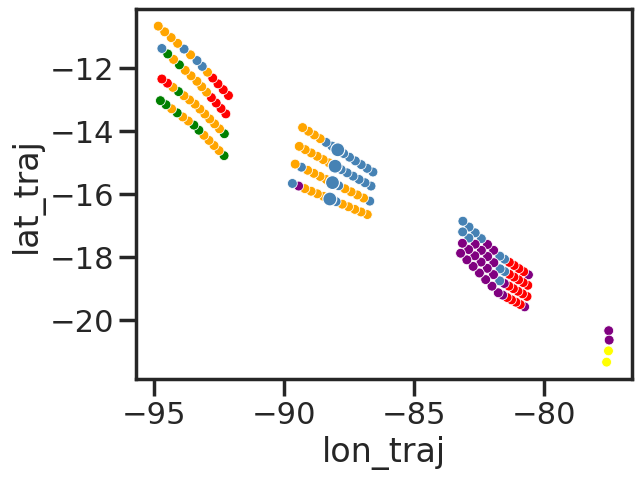

In [ ]:
orbit = '06766E'
tmp = bt_co_back_from_o.where(bt_co_back_from_o.orbit_startpoint == orbit, drop=True)
for i in range(len(tmp.timestep)):
    sns.scatterplot(data = tmp.isel(timestep=i), x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=50)

sns.scatterplot(data = tmp.sel(timestep=0), x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100)

#### ACMCAP profiles of CO transitioning clouds

In [ ]:
# create a big figure with many small subplots (like peek_at_acmcap) to compare the different trajectory sets
# the subplots are at x-positions determined by the transition_time_diff values, and y-positions determined s.t. plots dont overlap
hue_variable = 'rwp'  # can be 'rain_rate_cbh', 'lwp'

fig = plt.figure(figsize=(40, 20))
# Track occupied positions to avoid overlaps
occupied_positions = []  # List of (left, right, bottom, top) rectangles
subplot_width = 0.05
subplot_height = 0.015

#transition_times = bt_dataset.transition_time_diff.values
#valid_times = transition_times[~np.isnan(transition_times)]
#time_min, time_max = valid_times.min(), valid_times.max()
time_min, time_max = -40, 40

sns.set_context('talk', font_scale=0.8)

for bt_dataset, transition_from_msi_cats in [
    (bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True), [0, 1]),
    (bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True), [2])
    ]:


    for i, t_ in enumerate(bt_dataset.time_startpoint.values):
        print(t_)
        orbit = bt_dataset.sel(time_startpoint=t_).orbit_startpoint.values
        acmcap_orbit = acmcap[acmcap.orbit == orbit]
        acmcap_time_startpoint = acmcap_orbit[np.abs(pd.to_datetime(acmcap_orbit.time) - pd.to_datetime(t_)) < pd.Timedelta('0.1s')]
        # check
        scene_0_matches = False
        scene_1_matches = False
        if np.isin(np.unique(acmcap_time_startpoint.cats_0), transition_from_msi_cats):
            print(f'CATS_0 = {transition_from_msi_cats} match confirmed')
            scene_0_matches = True
            scene_id_0 = np.unique(acmcap_time_startpoint.scene_id_0)
        if np.isin(np.unique(acmcap_time_startpoint.cats_1), transition_from_msi_cats):
            print(f'CATS_1 = {transition_from_msi_cats} match confirmed')
            scene_1_matches = True
            scene_id_1 = np.unique(acmcap_time_startpoint.scene_id_1)

        time_to_trans = bt_dataset.sel(time_startpoint=t_).transition_time_diff.values
        if pd.isna(time_to_trans):
            continue

        if scene_0_matches and scene_1_matches:
            acmcap_orbit_0 = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0[0]]
            tmp_latmax, tmp_latmin = acmcap_orbit_0.latitude.max(), acmcap_orbit_0.latitude.min()
            acmcap_orbit_1 = acmcap_orbit[(acmcap_orbit.scene_id_1 == scene_id_1[0]) & ((acmcap_orbit.latitude > tmp_latmax) | (acmcap_orbit.latitude < tmp_latmin))]  # remove overlapping latitudes
            tmp_scene = pd.concat([acmcap_orbit_0, acmcap_orbit_1])
            tmp_scene = tmp_scene.sort_values(by='latitude')
            scene_id = f'{scene_id_0[0]} & {scene_id_1[0]}'
        elif scene_0_matches:
            tmp_scene = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0[0]]
            scene_id = f'{scene_id_0[0]}'
        elif scene_1_matches:
            tmp_scene = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1[0]]
            scene_id = f'{scene_id_1[0]}'
        else:
            continue  # Skip plotting if no matches

        def add_profile(profile_arr, cbh_m, cth_m):
            # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
            for i in range(len(cth_m)):
                cbh = cbh_m.values[i]
                cth = cth_m.values[i]
                if np.isnan(cbh) or np.isnan(cth):
                    continue
                cbh_idx = int(cbh // 100)
                cth_idx = int(cth // 100)
                # Ensure indices are within bounds
                cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
                cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
                profile_arr[i, cbh_idx:cth_idx+1] += 1
            return profile_arr
        
        x_length = len(tmp_scene.latitude)
        profile_arr = xr.DataArray(np.zeros((x_length, 20)), dims=['latitude', 'height'], coords={'latitude': tmp_scene.latitude.values, 'height': np.arange(20)*100})
        profile_arr = add_profile(profile_arr, tmp_scene.cbh_m, tmp_scene.cth_m)


        # add axes to the big figure at the correct position
        # Calculate normalized position
        #norm_x = (time_to_trans - time_min) / (time_max - time_min)
        ## Position the subplot
        #left = 0.1 + norm_x * 0.8  # Use 80% of figure width
        #bottom = 0.1 + (i % 5) * 0.15  # Stack multiple rows if needed
        #width = 0.15
        #height = 0.05
        #ax = fig.add_axes([left, bottom, width, height])
        
        # Calculate normalized x position
        norm_x = (time_to_trans - time_min) / (time_max - time_min)
        left = 0.1 + norm_x * 0.8  # Use 80% of figure width
        right = left + subplot_width
        
        # Find available vertical position
        bottom = 0.1  # Start from bottom
        found_position = False
        
        while not found_position:
            top = bottom + subplot_height
            
            # Check if this position overlaps with any existing subplot
            overlaps = False
            for occupied in occupied_positions:
                occ_left, occ_right, occ_bottom, occ_top = occupied
                
                # Check for overlap
                if (left < occ_right and right > occ_left and 
                    bottom < occ_top and top > occ_bottom):
                    overlaps = True
                    break
            
            if not overlaps:
                found_position = True
            else:
                bottom += subplot_height + 0.002  # Move up with small gap
        
        # Record this position as occupied
        occupied_positions.append((left, right, bottom, top))
        
        # Create the subplot
        ax = fig.add_axes([left, bottom, subplot_width, subplot_height])
        
        im1 = ax.imshow(profile_arr.T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='Blues')
        if hue_variable == 'rwp':
            im2 = ax.imshow((profile_arr * tmp_scene.rwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='turbo', norm=LogNorm(5e-3, 5e-1))
            #plt.colorbar(im2, ax=ax, label='RR / kg m$^{-2}$ s$^{-1}$')
        elif hue_variable == 'lwp':
            im2 = ax.imshow((profile_arr * tmp_scene.lwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='viridis', norm=LogNorm(1e-4, 5e-1))
            #plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
        #ax.set_xticks(ticks=np.linspace(0, x_length, 3), labels=[f'{lat:.2f}' for lat in np.linspace(tmp_scene.latitude.values[0], tmp_scene.latitude.values[-1], 3)])
        #ax.set_title(f'{orbit}, $\Delta$t={time_to_trans}, Scene ID {scene_id}')
        ax.set_axis_off()  # Turn off axis for small plots

#max_y_position = np.max([occupied_positions[i][1] for i in range(len(occupied_positions))])
ax = fig.add_axes([0.9, 0.5, 0.01, 0.1])  # Position for colorbar
if hue_variable == 'rwp':
    plt.colorbar(im2, ax=ax, label='RWP / kg m$^{-2}$')
elif hue_variable == 'lwp':
    plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
ax.set_axis_off()

# plot one big time arrow at the bottom to indicate time axis
ax = fig.add_axes([0.1, 0.05, 0.9, 0.02])  # Position for time axis
ax.arrow(0, 0.5, 1, 0, head_width=0.03, head_length=0.02, length_includes_head=True, fc='black', ec='black')
ax.text(0, 0.48, f'{time_min} h', ha='center')
ax.text(1, 0.48, f'{time_max} h', ha='center')
ax.text(0.5, 0.48, f'transition', ha='center')
ax.set_axis_off()

In [ ]:
# look at example profiles
tmp = bt_co_forward_from_c.isel(time_startpoint=slice(0,20))
tmp = bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True)#.isel(time_startpoint=slice(0,5))
tmp = bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True).isel(time_startpoint=slice(0,20))
add_acmcap_info_to_bt(tmp, acmcap, transition_from_msi_cats=[0,1], peek_at_acmcap_clouds=True)

#### example for presentation

IndexError: index 1 is out of bounds for axis 0 with size 0

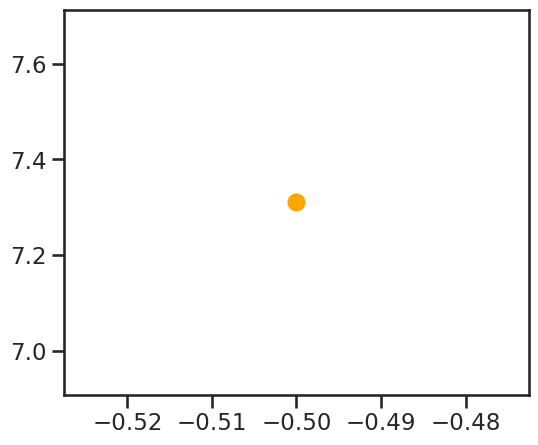

In [33]:
sns.set_context('talk', font_scale=1)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

bt_co_forward_from_c.where(bt_co_forward_from_c.orbit_startpoint == '06766E', drop=True)

plt.figure(figsize=(6, 5))
tmp_c = bt_co_forward_from_c.where(bt_co_forward_from_c.orbit_startpoint == '06766E', drop=True)
#sns.scatterplot(data = tmp_c, x='transition_time_diff', y='rain_rate_cbh', hue='lwp', hue_norm=LogNorm(1e-2, 1e-1), palette='viridis', legend=False, s=100)
tmp_c_sel = tmp_c.where(~np.isnan(tmp_c.transition_time_diff), drop=True).isel(time_startpoint=[9])
plt.plot([tmp_c_sel.transition_time_diff.values], [tmp_c_sel.rwp.values*1e3], 'o', color='orange', markersize=12)

tmp_o = bt_co_back_from_o.where(bt_co_back_from_o.orbit_startpoint == '06766E', drop=True)
#sns.scatterplot(data = tmp_o, x='transition_time_diff', y='rain_rate_cbh', hue='lwp', hue_norm=LogNorm(1e-2, 1e-1), palette='viridis', legend=False, s=100)
tmp_o_sel = tmp_o.where(~np.isnan(tmp_o.transition_time_diff), drop=True).isel(time_startpoint=[1])
plt.plot([tmp_o_sel.transition_time_diff.values], [tmp_o_sel.rwp.values*1e3], 'o', color='deeppink', markersize=12)

plt.yscale('log')
plt.ylim(2e-4, 5e-2)
plt.xlim(-5, 5)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / kg m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

#sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(1e-2, 1e-1))
#sm.set_array([])
#cbar = plt.colorbar(sm, ax=plt.gca(), fraction=0.025)
#cbar.set_label('LWP/ kg m$^{-2}$')

1.0
Original shape: FrozenMappingWarningOnValuesAccess({'y': 2712, 'x': 2712, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 548, 'x': 557, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Lat range: -23.19 to -2.12
Lon range: -97.63 to -74.62


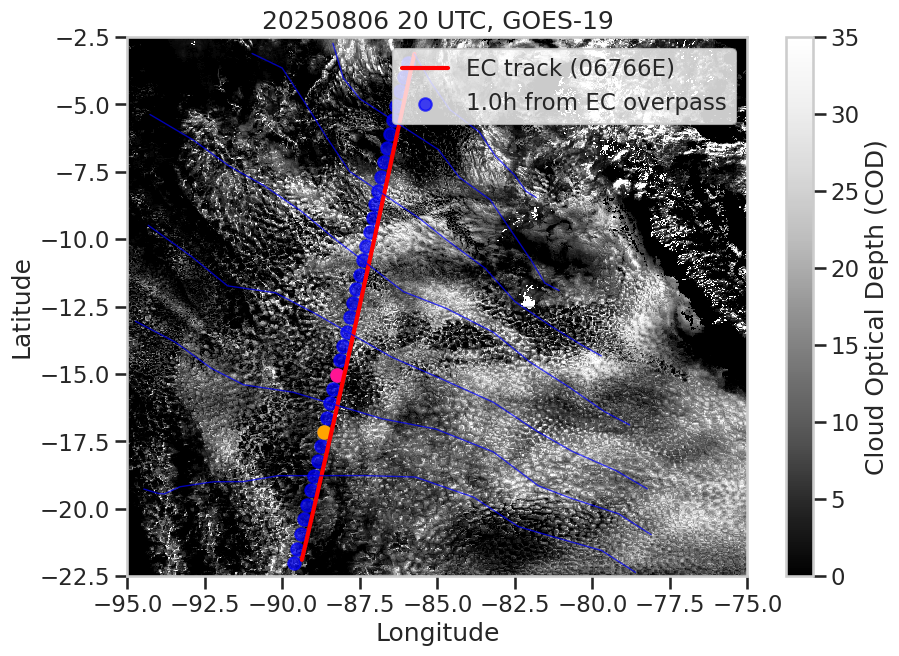

In [ ]:
orbit = '06766E'
bt_orbit = bt_with_goes.where(bt_with_goes.orbit_startpoint == orbit, drop=True)
overpass_date = str(bt_orbit.time_startpoint[0].dt.strftime('%Y%m%d').values)
valid_dates = np.abs(bt_orbit.datetime_traj - bt_orbit.time_startpoint[0]) < np.timedelta64(42, 'h')
bt_orbit = bt_orbit.where(valid_dates)

goes_time = 20
overpass_time = 19
date = overpass_date

timestep = (pd.to_datetime(date+str(goes_time).zfill(2)+'00') - pd.to_datetime(overpass_date+str(overpass_time).zfill(2)+'00')).total_seconds() / 3600
print(timestep)

with xr.open_dataset(f'/home/jmayer/Object_Data/GOES19/2025/{date[4:6]}/goes19_CODF_{date}_{goes_time}00.nc') as ds:
    # Crop to your region
    ds_COD_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

plt.figure(figsize=(10, 7))
plt.pcolormesh(ds_COD_cropped.longitude, ds_COD_cropped.latitude, ds_COD_cropped['COD'], 
            vmax=35, cmap='Greys_r', shading='auto')
plt.colorbar(label='Cloud Optical Depth (COD)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title(f'{date} {goes_time} UTC, GOES-19')

bt_startpoint = bt_orbit.sel(timestep=0)
plt.plot(bt_startpoint.lon_traj.values, bt_startpoint.lat_traj.values, color='red', lw=3, label=f'EC track ({orbit})')

bt_at_sel_timestep = bt_orbit.sel(timestep=timestep)
plt.scatter(bt_at_sel_timestep.lon_traj.values, bt_at_sel_timestep.lat_traj.values, color='blue', marker='o', alpha=0.7, label=f'{timestep}h from EC overpass')

tmp_at_sel_timestep = tmp_c.where(~np.isnan(tmp_c.transition_time_diff), drop=True).sel(timestep=timestep).isel(time_startpoint=[11])
plt.scatter(tmp_at_sel_timestep.lon_traj.values, tmp_at_sel_timestep.lat_traj.values, color='orange', marker='o', alpha=1)

tmp_at_sel_timestep = tmp_o.where(~np.isnan(tmp_o.transition_time_diff), drop=True).sel(timestep=timestep).isel(time_startpoint=[1])
plt.scatter(tmp_at_sel_timestep.lon_traj.values, tmp_at_sel_timestep.lat_traj.values, color='deeppink', marker='o', alpha=1)


for i in range(len(bt_orbit.time_startpoint)//5):
    traj = bt_orbit.isel(time_startpoint=i*5).sortby('timestep')
    plt.plot(traj.lon_traj.values, traj.lat_traj.values, color='blue', lw=1, alpha=0.7)

plt.legend()
plt.ylim(lat_bounds)
plt.xlim(lon_bounds)
plt.show()

Plotting orbit 06766E


Selecting frame from 9 to 4877
Selecting frame from 443 to 11483


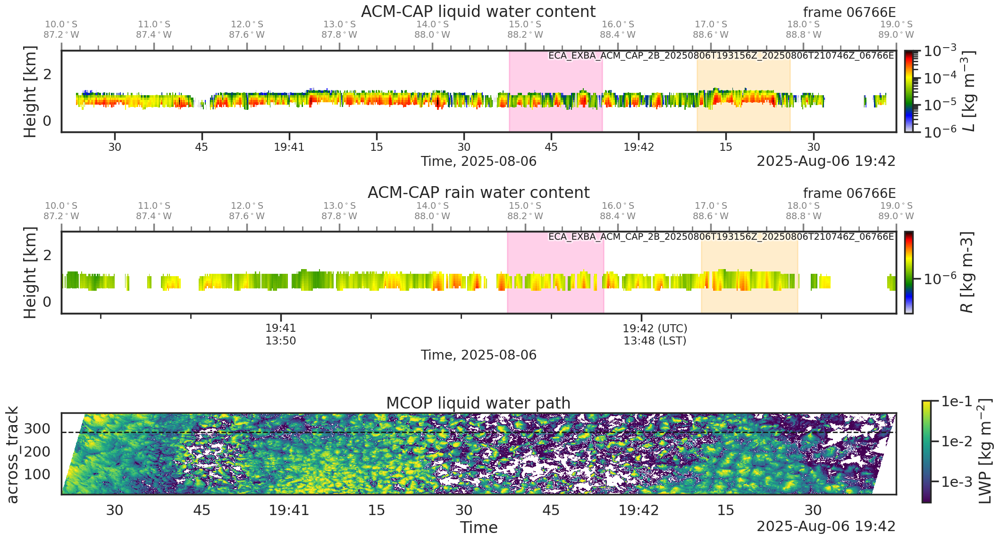

In [67]:
sns.set_style('white')
month = '08'

for orbit in ['06766E']:
    print(f'Plotting orbit {orbit}')

    bt_co_c_orbit = bt_co_c.where(bt_co_c.orbit_startpoint == orbit, drop=True)
    bt_co_o_orbit = bt_co_o.where(bt_co_o.orbit_startpoint == orbit, drop=True)
    bt_co_c_orbit = bt_co_c_orbit.where(~np.isnan(bt_co_c_orbit.transition_time_diff), drop=True).isel(time_startpoint=[11])
    bt_co_o_orbit = bt_co_o_orbit.where(~np.isnan(bt_co_o_orbit.transition_time_diff), drop=True).isel(time_startpoint=[1])

    # load ACMCAP
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/{month}/*/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    lat_range = (-19, -10)
    lon_range = (-95, -75)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_range[0]) & (ACMCAP.latitude < lat_range[1]) & (ACMCAP.longitude > lon_range[0]) & (ACMCAP.longitude < lon_range[1]), drop=True)
    ACMCAP.encoding = encoding.copy()

    # load MCOP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/{month}/*/*_{orbit}.h5')[0]
        MCOP = ecio.load_MCOP(filename)
        MCOP = MCOP.assign_coords(
            {
            'along_track': (
                ["along_track"],
                MCOP['along_track'].data,
                MCOP['along_track'].attrs
                ),
            'across_track': (
                ['across_track'],
                MCOP['across_track'].data,
                MCOP['across_track'].attrs
                )
            })
        MCOP2 = MCOP.where((MCOP.latitude > lat_range[0]) & (MCOP.latitude < lat_range[1]) & (MCOP.longitude > lon_range[0]) & (MCOP.longitude < lon_range[1]), drop=True)
        MCOP2 = MCOP2[['latitude','longitude','cloud_water_path','cloud_optical_thickness','cloud_effective_radius']]
        MCOP2['time'] = MCOP['time'].sel(along_track=MCOP2.along_track)
        MCOP2 = MCOP2.assign_coords(
            {
            'time': (
                ['along_track'],
                MCOP2.time.data,
                MCOP2.time.attrs
                )
            })
        MCOP2 = MCOP2.swap_dims({'along_track': 'time'})
    except:
        print(f'No MCOP data for {orbit}')
        MCOP2 = None

    # plot
    fig, axs = plt.subplots(3,1, figsize=(20,12), gridspec_kw={'height_ratios': [1, 1, 1]})

    # highlight scenes for which transitions were found
    for ax in axs[0:2]:
        for i in range(len(bt_co_c_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='orange', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_c_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            #ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            #ax.annotate(bt_co_c_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    for ax in axs[0:2]:
        for i in range(len(bt_co_o_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='deeppink', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_o_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            #ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            #ax.annotate(bt_co_o_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    ax = axs[0]
    ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=3000)

    ax = axs[1]
    ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", hmax=3000)

    if MCOP2 is not None:
        ax = axs[2]
        ax.sharex(axs[0])
        (np.log(MCOP2.cloud_water_path)).T.plot(ax=ax, cmap='viridis', vmax=-3.2, vmin=-1, add_colorbar=False)
        ax.axhline(284, color='k', linestyle='--', lw=2)
        ax.set_title('MCOP liquid water path')
        # add cbar to the right
        cbar_ax = fig.add_axes([0.99, 0.09, 0.009, 0.18])  # [left, bottom, width, height]
        cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
        cbar.set_label('LWP [kg m$^{-2}$]')
        cbar.set_ticks([-3,-2,-1])
        cbar.set_ticklabels(['1e-3', '1e-2', '1e-1'])
    fig.tight_layout()
    plt.show()

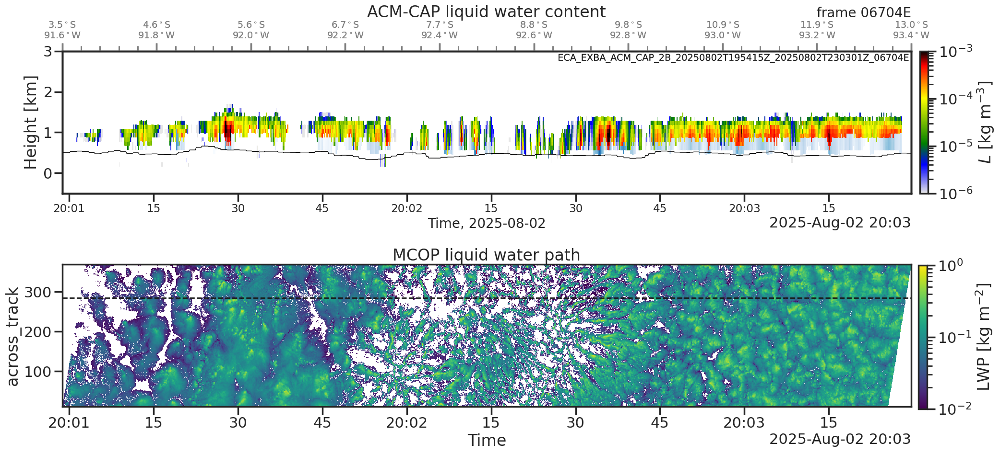

In [42]:
fig, axs = plt.subplots(2,1, figsize=(20,10), gridspec_kw={'height_ratios': [1, 1]})

ax = axs[0]
ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", cmap='Blues', plot_range=[1e-6,1e-3], hmax=3000)
ax.collections[0].colorbar.remove()
ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=3000)

lcl = acmcap[(acmcap.orbit == orbit) & (acmcap.latitude > -13) & (acmcap.latitude < -3.5)].lcl.values
time = acmcap[(acmcap.orbit == orbit) & (acmcap.latitude > -13) & (acmcap.latitude < -3.5)].time.values
plt.plot(time, lcl, color='black', lw=1, label='LCL')

if MCOP2 is not None:
    ax = axs[1]
    ax.sharex(axs[0])
    MCOP2.cloud_water_path.T.plot(ax=ax, cmap='viridis', norm=LogNorm(vmin=1e-2, vmax=1e0), add_colorbar=False)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP liquid water path')
    # add cbar to the right
    cbar_ax = fig.add_axes([0.97, 0.12, 0.009, 0.3])  # [left, bottom, width, height]
    cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
    cbar.set_label('LWP [kg m$^{-2}$]')
fig.tight_layout()
plt.show()

### OC transitions

In [58]:
bt_oc_forward_from_o = add_acmcap_info_to_bt(bt_oc_forward_from_o, acmcap, transition_from_goes_cats=[2])

2025-07-01T19:54:36.605387008
No CATS = [2] match found
2025-07-01T19:54:44.669450944
No CATS = [2] match found
2025-07-01T19:54:52.733513920
No CATS = [2] match found
2025-07-01T19:55:00.797578048
No CATS = [2] match found
2025-07-01T19:55:08.861642048
No CATS = [2] match found
2025-07-01T19:55:16.925705088
No CATS = [2] match found
2025-07-01T19:55:24.989771968
No CATS = [2] match found
2025-07-01T19:55:33.053838912
No CATS = [2] match found
2025-07-01T19:55:41.117903104
No CATS = [2] match found
2025-07-01T19:55:49.181966464
No CATS = [2] match found
2025-07-01T19:55:57.246030080
No CATS = [2] match found
2025-07-01T19:56:05.310094016
No CATS = [2] match found
2025-07-01T19:56:13.374157056
No CATS = [2] match found
2025-07-01T19:56:21.438221056
No CATS = [2] match found
2025-07-01T19:56:29.502284032
No CATS = [2] match found
2025-07-01T19:56:37.566348032
No CATS = [2] match found
2025-07-01T19:56:45.630411904
No CATS = [2] match found
2025-07-01T19:56:53.694474880
No CATS = [2] matc

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


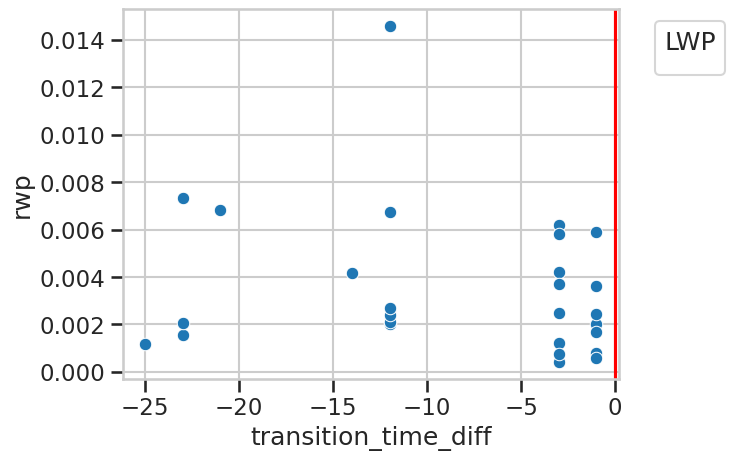

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


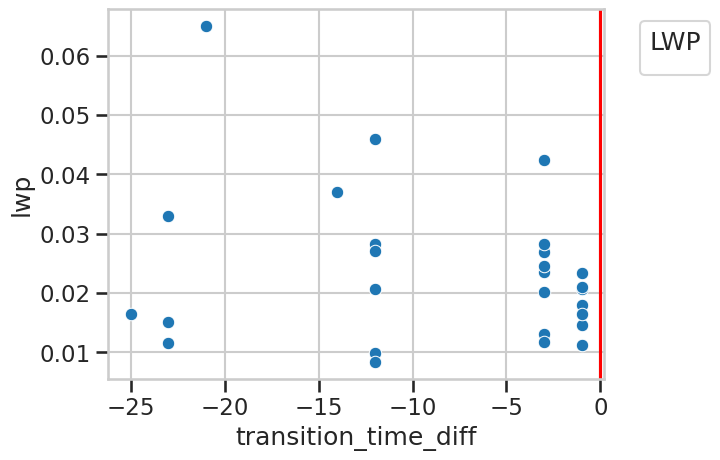

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


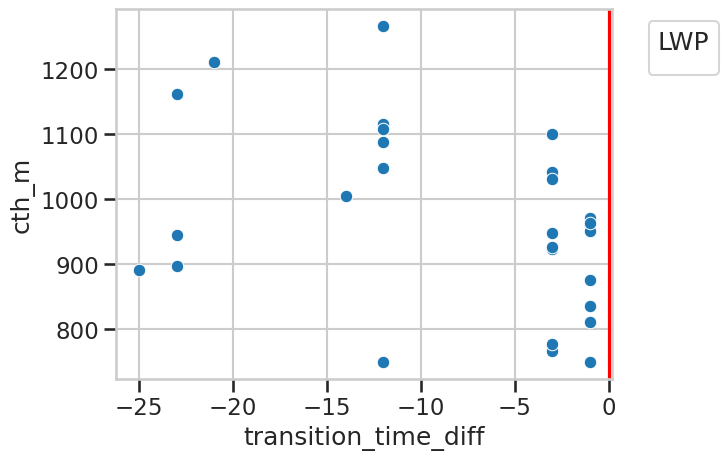

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


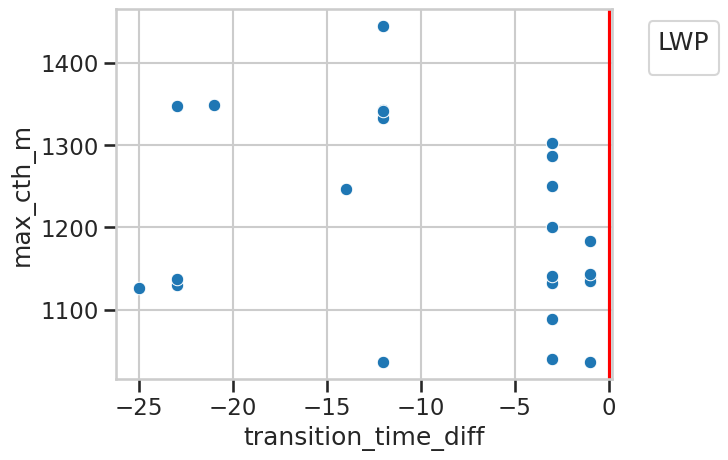

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


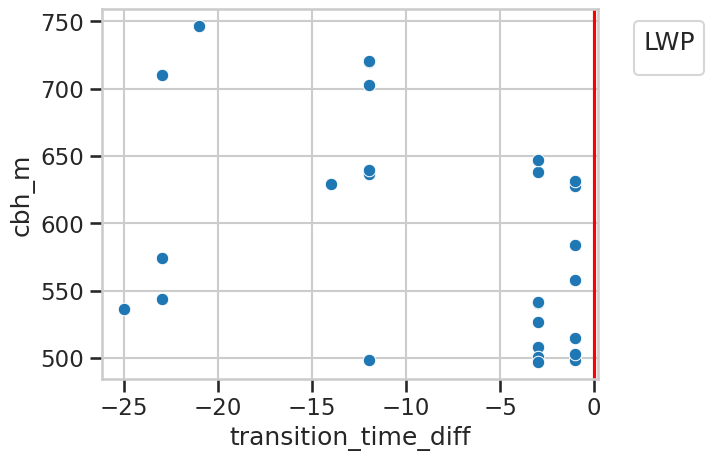

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


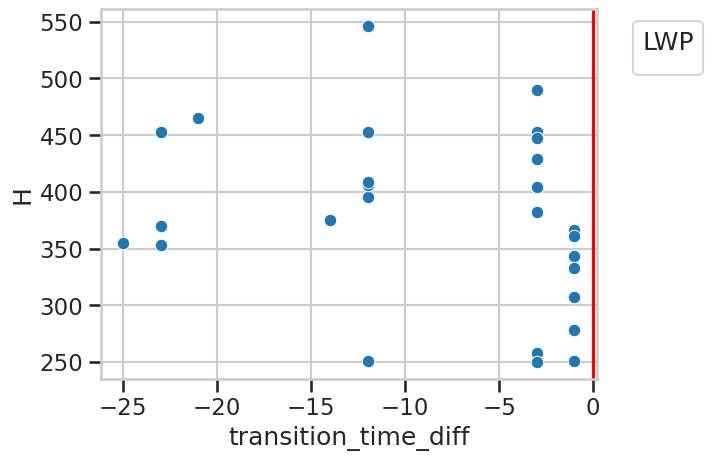

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


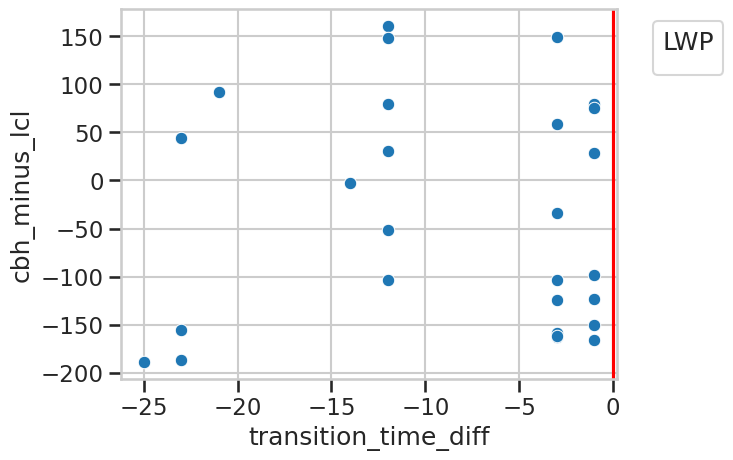

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


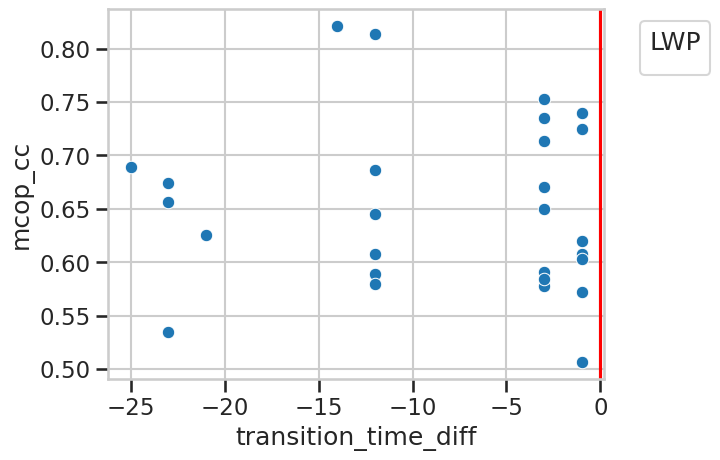

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


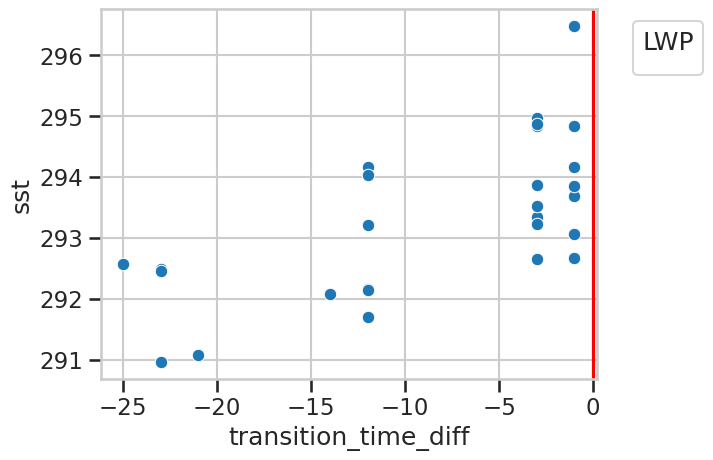

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


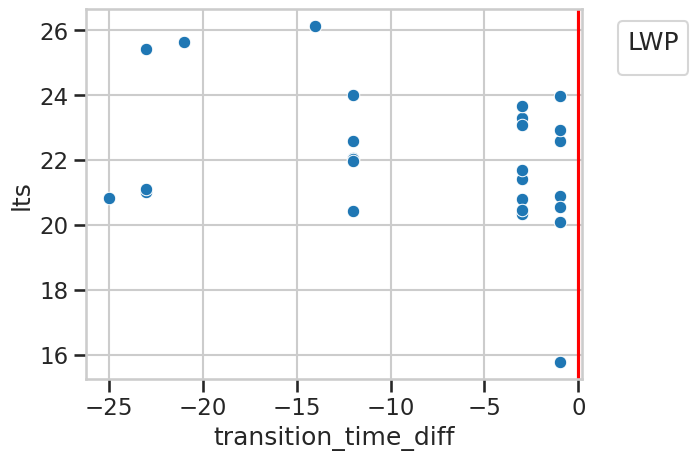

In [59]:
sns.set_context('talk', font_scale=1)
sns.set_style('whitegrid')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False
for var in ['rwp', 'lwp', 'cth_m','max_cth_m', 'cbh_m', 'H', 'cbh_minus_lcl', 'mcop_cc', 'sst', 'lts']:
    sns.scatterplot(data = bt_oc_forward_from_o, x='transition_time_diff', y=var)#, hue='orbit_startpoint', palette='tab10', legend=True, s=100)
    
    plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.axvline(0, color='red', linestyle='-')
    plt.show()